# Objective and current stage
**The requested comparison set is complete.** Joint c/f calibration now follows the original 20 x 5 x 5 scheme; all 360 paired calibration summaries are available. All 84 horizon rows of the historical eTable 12 definitions have been reproduced with explicit scorer labels. The 53 previously completed bootstrap jobs were reused unchanged; one additional 500-resample job supplies the missing historical IBS arms.
This closing execution took 31.08 minutes with a sampled aggregate R working-set peak of 17.17 GiB. Its 1,000 Cox fits belong only to the missing joint c/f calibration. No imputation, ML tuning or SHAP was repeated. Retained b/e decisions remain unchanged; the Full mortality comparator remains available. Global LP/IJ, net-risk and first-event CIF alternatives, and the requested threshold summary are included. DCA is excluded. See [completion checkpoint](../docs/08_complete_checkpoint.md).

In [1]:
#| label: p225-config-and-environment
#| message: false
.t0 <- proc.time()
# Find the shared configuration and verify the existing R environment before reading scientific objects.
if (.Platform$OS.type == "windows") stopifnot(nzchar(Sys.setlocale("LC_CTYPE", "English_United States.utf8")))
root <- normalizePath(getwd(), winslash = "/", mustWork = TRUE)
while (!file.exists(file.path(root, "config.yml"))) {
  parent <- dirname(root)
  if (identical(parent, root)) stop("config.yml was not found.", call. = FALSE)
  root <- parent
}
config <- yaml::read_yaml(file.path(root, "config.yml"))
resolve_path <- function(value) normalizePath(if (grepl("^([A-Za-z]:[/\\\\]|/|\\\\\\\\)", value)) value else file.path(root, value), winslash = "/", mustWork = FALSE)
source_path <- function(name) resolve_path(config$sources[[name]])
object_dir <- resolve_path(config$paths$objects)
settings <- config$cox_consolidation
threads <- as.integer(config$imputation$threads)
Sys.setenv(OMP_NUM_THREADS = threads, OPENBLAS_NUM_THREADS = threads, MKL_NUM_THREADS = threads, R_RANGER_NUM_THREADS = threads)
options(Ncpus = threads, ranger.num.threads = threads)
lock <- jsonlite::read_json(resolve_path(config$runtime$r_lock), simplifyVector = FALSE)
packages <- c("yaml", "jsonlite", "nanoparquet", "digest", "ps", "survival", "htmltools", "knitr", "IRdisplay", "future", "parallelly", "future.apply", "riskRegression", "prodlim", "pec", "Rcpp")
stopifnot(as.character(getRversion()) == lock$R$Version, settings$mode %in% c("prepare", "recover", "bootstrap", "run"), threads <= 2L)
for (package in packages) stopifnot(requireNamespace(package, quietly = TRUE), utils::packageVersion(package) == base::package_version(lock$Packages[[package]]$Version))
future::plan(future::sequential)
set.seed(as.integer(config$imputation$seed))
stopifnot(identical(settings$calibration_comparison_method, "original_repeated_cv"), identical(settings$censoring_weights, "original_C_reestimated_IBS_fixed"))
written <- character()
run_started <- Sys.time()
show_table <- function(data, caption) {
  widget <- htmltools::browsable(htmltools::tags$div(class = "article2-table", role = "region", tabindex = 0, `aria-label` = caption, style = "max-height:420px;overflow:auto;max-width:100%;border:1px solid #ddd;padding:0.4rem;margin-bottom:0.8rem;", htmltools::HTML(knitr::kable(data, format = "html", caption = caption, row.names = FALSE, digits = 6, escape = TRUE))))
  IRdisplay::display_html(as.character(widget))
  invisible(widget)
}
show_table(data.frame(Package = packages, Version = vapply(packages, function(x) as.character(utils::packageVersion(x)), character(1L))), "Verified environment: R 4.4.1 / r-main / ir")
show_table(data.frame(Mode = settings$mode, Seed = config$imputation$seed, Main_threads = threads, Available_RAM_GiB = ps::ps_system_memory()$avail / 1024^3), "Execution mode and available memory; prepare runs only non-reportable checks")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Package,Version
yaml,2.3.10
jsonlite,1.9.1
nanoparquet,0.4.2
digest,0.6.37
ps,1.9.3
survival,3.6.4
htmltools,0.5.8.1
knitr,1.50
IRdisplay,1.1
future,1.67.0


Mode,Seed,Main_threads,Available_RAM_GiB
run,2125,2,65.88141


Elapsed: 0.061 minutes


In [2]:
#| label: p225-verify-input-sources
#| message: false
.t0 <- proc.time()
# Pin the completed inputs; historical artifacts are evidence, not clean sensitivity results.
source_keys <- c("cox_full_handoff", "cox_shap_handoff", "cox_performance_execution", "cox_shap_execution", "cox_development_matrices", "split", "presentation_notebook", "consolidation_source_audit", "manuscript", "article2_integrated_guide")
source_files <- vapply(source_keys, source_path, character(1L))
stopifnot(all(file.exists(source_files)))
source_hashes <- vapply(source_files, function(x) digest::digest(file = x, algo = "sha256"), character(1L))
input_manifest <- data.frame(Source = source_keys, Config_path = vapply(source_keys, function(x) config$sources[[x]], character(1L)), Bytes = as.numeric(file.info(source_files)$size), SHA256 = source_hashes, row.names = NULL)
full_run <- jsonlite::read_json(source_path("cox_performance_execution"), simplifyVector = TRUE)
shap_run <- jsonlite::read_json(source_path("cox_shap_execution"), simplifyVector = TRUE)
audit <- jsonlite::read_json(source_path("consolidation_source_audit"), simplifyVector = FALSE)
stopifnot(identical(source_hashes[["presentation_notebook"]], audit$source_sha256), shap_run$errors == 0L, isTRUE(shap_run$snapshot$b_e_comparisons_complete), isTRUE(shap_run$snapshot$remaining_rule_accepted))
stopifnot(full_run$snapshot$metric_control_max < 1e-8, shap_run$snapshot$metric_control_max < 1e-8, full_run$snapshot$calibration_control_max < 1e-8, shap_run$snapshot$calibration_control_max < 1e-8)
show_table(input_manifest, "Required inputs and source fingerprints; paths are configured centrally")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Source,Config_path,Bytes,SHA256
cox_full_handoff,outputs/objects/cox_full_model_handoff_2026-10-04_fcd1bd763f13.rds,1994,1773da1655fe2c94c321982acf43db72d4aac225ae92e44012fd66e845e6edcd
cox_shap_handoff,outputs/objects/Table2_SHAP_retained_model_handoff_2026-10-09_dd191173173a.rds,14755,ee7a73bfe139793cb04d2ad857ec096fa9fe2e6a71cc11ee397288da01edd000
cox_performance_execution,docs/06_full_comparison_replay_execution.json,119961,8e8a8f9a972885f754f26c60e80be5eb39a6c1887396089fe08bec61d0d14f55
cox_shap_execution,docs/07_session_export_execution.json,745217,688a1ebb2dda58ef45f93826d42b7e7312717475bfd5d4008004fa588e351e16
cox_development_matrices,outputs/objects/cox_development_matrices_2026-10-04_fcd1bd763f13.rds,11768170,8efe3273ed59e4481d2ef2764b1bafeb5c87f3f648c4b67b058d11a907a8070a
split,../cons/_out/comb_split_seed2125_test20_mar26.parquet,883144,ef71d2ffc30fdb6e6764cc81a275e29aa4a91d1bb995759335942945f7f68883
presentation_notebook,../cons/prediction225_converted_mod.ipynb,3250605,a9ffbb6943eb9e13c5c2ef61c4018f9a8e2e79ed82454e19fbba5417b5505e24
consolidation_source_audit,docs/08_prediction225_source_audit_20261009.json,16766,8a76496ed601af3a7ffbd91b96367e9cb23161ce8cfca9b34bf15ef6c9feff23
manuscript,H:/My Drive/PERSONAL ANDRES/UCH_salud_publica/asignaturas/0_TESIS/_output/BMC-MRM/man_Article2_BMC_MRM_v1.docx,4763511,3553de74e27924175367f809f08d5defd32ec770f01d1dbe12de3ab9947b2f3a
article2_integrated_guide,H:/My Drive/PERSONAL ANDRES/UCH_salud_publica/asignaturas/0_TESIS/_output/BMC-MRM/Article2_guia_integrada_coleccion_matriz_plan_20261002.md,89977,0587a21e9817416d2367834536a0bb9789cc102522200e7e6bdd7a68767b8417


Elapsed: 0.013 minutes


## 2. Retained model specifications
Full retains the original sequential decisions from 06. It excludes minimum therapeutic-process achievement and uses treatment setting plus rule-violation/undetermined discharge strata. b uses the same strata with the retained SHAP predictor set. e uses treatment setting plus physical-comorbidity strata. The historical thesis letters do not override these verified formulas.
The retained models shown here are not the complete comparison inventory. Section 4 includes initial Full, VIF-reduced Full, SHAP before added stratification and SHAP interaction comparators. b/e remain selected.

In [3]:
#| label: p225-load-retained-formulas
#| message: false
.t0 <- proc.time()
# Read formula objects and the compact b/e handoff without importing a legacy workspace.
full_handoff <- readRDS(source_path("cox_full_handoff"))
shap_handoff <- readRDS(source_path("cox_shap_handoff"))
stopifnot(identical(full_handoff$signature, config$cox_shap$reference_cox_signature), identical(shap_handoff$signature, shap_run$snapshot$remaining_signature), identical(shap_handoff$performance_signature, shap_run$snapshot$performance_signature))
stopifnot(identical(shap_handoff$formulas, as.list(shap_run$snapshot$retained_formulas)))
formulas <- list(Full_readmission = full_handoff$value$formulas$readmission$stratified, b = stats::as.formula(shap_handoff$formulas$b, env = asNamespace("survival")), Full_mortality = full_handoff$value$formulas$death$stratified, e = stats::as.formula(shap_handoff$formulas$e, env = asNamespace("survival")))
formula_terms <- function(f) attr(stats::terms(f), "term.labels")
formula_strata <- function(f) sub("^strata\\((.*)\\)$", "\\1", grep("^strata\\(", formula_terms(f), value = TRUE))
removed_collinear <- "evaluacindelprocesoteraputico_logro_minimo"
stopifnot(all(vapply(formulas, function(f) !removed_collinear %in% all.vars(f), logical(1L))))
stopifnot("dit_m" %in% all.vars(formulas$b), !"dit_m" %in% all.vars(formulas$e))
expected_discharge_strata <- c("plan_type_strata", "tr_outcome_adm_discharge_rule_violation_undet")
for (id in c("Full_readmission", "Full_mortality", "b")) stopifnot(setequal(formula_strata(formulas[[id]]), expected_discharge_strata))
stopifnot(setequal(formula_strata(formulas$e), c("plan_type_strata", "any_phys_dx")))
model_registry <- data.frame(Model = names(formulas), Outcome = c("Readmission", "Readmission", "Mortality", "Mortality"), Predictor_set = c("Full, retained in 06", "SHAP b, retained in 07", "Full, retained in 06", "SHAP e, retained in 07"), Ordinary_terms = vapply(formulas, function(f) sum(!startsWith(formula_terms(f), "strata(")), integer(1L)), Stratification = c(rep("Treatment setting + rule violation/undetermined discharge", 3L), "Treatment setting + physical comorbidity"), Formula = vapply(formulas, function(f) paste(deparse(f), collapse = " "), character(1L)), row.names = NULL)
show_table(model_registry, "Selected models remain fixed; the reporting registry below also includes intermediate stages and interactions")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Model,Outcome,Predictor_set,Ordinary_terms,Stratification,Formula
Full_readmission,Readmission,"Full, retained in 06",63,Treatment setting + rule violation/undetermined discharge,"Surv(readmit_time_from_disch_m, readmit_event) ~ adm_age_rec3 + porc_pobr + dit_m + national_foreign + ethnicity + dg_psiq_cie_10_instudy + dg_psiq_cie_10_dg + dx_f3_mood + dx_f6_personality + dx_f_any_severe_mental + any_phys_dx + polysubstance_strict + sex_rec_woman + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + sub_dep_icd10_status_drug_dependence + any_violence_1_domestic_violence_sex_abuse + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + first_sub_used_alcohol + first_sub_used_cocaine_paste + first_sub_used_cocaine_powder + first_sub_used_other + primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + tipo_de_vivienda_rec2_other_unknown + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + marital_status_rec_single + marital_status_rec_separated_divorced_annulled_widowed + tenure_status_household_renting + tenure_status_household_others + tenure_status_household_stays_temporarily_with_a_relative + tenure_status_household_illegal_settlement + urbanicity_cat_2_mixed + urbanicity_cat_1_rural + evaluacindelprocesoteraputico_logro_intermedio + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + eva_fam_logro_intermedio + eva_fam_logro_minimo + eva_relinterp_logro_intermedio + eva_relinterp_logro_minimo + eva_ocupacion_logro_intermedio + eva_ocupacion_logro_minimo + eva_sm_logro_intermedio + eva_sm_logro_minimo + eva_fisica_logro_intermedio + eva_fisica_logro_minimo + eva_transgnorma_logro_intermedio + eva_transgnorma_logro_minimo + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet)"
b,Readmission,"SHAP b, retained in 07",26,Treatment setting + rule violation/undetermined discharge,"Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + adm_age_rec3 + porc_pobr + sex_rec_woman + ethnicity + dit_m + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + dg_psiq_cie_10_dg + sub_dep_icd10_status_drug_dependence + polysubstance_strict + eva_sm_logro_intermedio + eva_sm_logro_minimo + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + evaluacindelprocesoteraputico_logro_intermedio + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet)"
Full_mortality,Mortality,"Full, retained in 06",63,Treatment setting + rule violation/undetermined discharge,"Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + porc_pobr + dit_m + national_foreign + ethnicity + dg_psiq_cie_10_instudy + dg_psiq_cie_10_dg + dx_f3_mood + dx_f6_personality + dx_f_any_severe_mental + any_phys_dx + polysubstance_strict + sex_rec_woman + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + sub_dep_icd10_status_drug_dependence + any_violence_1_domestic_violence_sex_abuse + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + first_sub_used_alcohol + first_sub_used_cocaine_pas

Elapsed: 0.000 minutes


In [4]:
#| label: p225-verify-development-matrices
#| message: false
.t0 <- proc.time()
# Keep the fixed development membership and order across all five completed imputations.
matrix_bundle <- readRDS(source_path("cox_development_matrices"))
stopifnot(identical(matrix_bundle$signature, full_handoff$signature))
development <- matrix_bundle$value
rm(matrix_bundle)
split <- nanoparquet::read_parquet(source_path("split"))
split <- split[order(split$row_id), ]
expected_ids <- as.integer(split$row_id[as.logical(split$is_train)])
outcomes <- c("readmit_time_from_disch_m", "readmit_event", "death_time_from_disch_m", "death_event")
required_columns <- unique(unlist(lapply(formulas, all.vars)))
stopifnot(length(development) == 5L, !anyDuplicated(expected_ids))
for (data in development) {
  stopifnot(identical(as.integer(data$row_id), expected_ids), identical(names(data), names(development[[1L]])), all(required_columns %in% names(data)), !anyNA(data[required_columns]))
  for (name in outcomes) stopifnot(identical(data[[name]], development[[1L]][[name]]))
}
participants <- length(expected_ids)
horizons <- as.numeric(unlist(config$cox_performance$horizons_months))
grid <- sort(unique(c(0, seq(0.25, max(horizons), by = config$cox_performance$ibs_grid_step_months), horizons)))
show_table(data.frame(Imputation = seq_along(development), Participants = vapply(development, nrow, integer(1L)), Included_in_holdout = 0L, Missing_required_values = 0L), "Development membership verified; no new imputation or participant exclusion")
cat("Imputation and SHAP selection used complete development before internal CV. This stage does not establish independent validation of that preprocessing.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Imputation,Participants,Included_in_holdout,Missing_required_values
1,70521,0,0
2,70521,0,0
3,70521,0,0
4,70521,0,0
5,70521,0,0


Imputation and SHAP selection used complete development before internal CV. This stage does not establish independent validation of that preprocessing.


Elapsed: 0.013 minutes


## 3. Formal reporting design and original sources
The formal manuscript design uses one original set of five folds across five imputations for C/IBS, with 500 paired participant bootstrap resamples. The ten repeated partitions in 07 served exploration and remain available; their mean is not silently substituted for the formal estimate. Calibration retains 20 repetitions of five folds and five imputations.
For readmission, the primary C marker is net horizon risk. The historical primary IBS comparison also uses net predictions, with death handled on the observed competing-risk side. The matching published Full–SHAP IBS differences identify this arm. Predicted CIF, cause-specific C, competing-risk C and calibration are separately labelled; “AJ” alone does not identify the predicted probability.

In [5]:
#| label: p225-formal-design-and-source-map
#| message: false
.t0 <- proc.time()
# Preserve the formal source design; this preparation neither reduces bootstrap nor introduces new resampling.
stopifnot(settings$c_ibs_repeats == 1L, config$cox_performance$folds == 5L, config$cox_performance$n_imputations == 5L, settings$calibration_repeats == 20L, settings$bootstrap_replicates == 500L)
formal_design <- data.frame(Component = c("Uno C and paired delta C", "Classical integrated IBS and paired delta IBS", "Readmission calibration", "Mortality calibration", "Clean DeepSurv-informed sensitivity"), Predictions = c("Net risk 1-S(h), pooled across imputations", "Net survival; readmission observed competing-risk weights; mortality KM weights", "Cause-specific predicted CIF versus AJ", "All-cause net risk versus KM", "Pending reconstruction after development-only imputation"), Design = c("Original 5 folds x 5 imputations; 500 paired participant resamples", "Original folds; shared participant resamples across arms within IBS; fixed censoring weights; 0.25-month integration grid", "20 repetitions x 5 folds x 5 imputations", "20 repetitions x 5 folds x 5 imputations", "Historical artifacts are controls only"), Current_stage = c(rep("Inputs verified; formal intervals not run", 2L), rep("Completed 06/07 caches inventoried; consolidation pending", 2L), "Not available in the clean pipeline"))
show_table(formal_design, "Formal 225 design; no interval is borrowed from a historical execution")
source_map <- do.call(rbind, lapply(audit$source_map, function(x) data.frame(Original_labels = paste(unlist(x$labels), collapse = "; "), Purpose = x$purpose, Manuscript = if (is.null(x$manuscript)) "Intermediate or traceability" else x$manuscript)))
show_table(source_map, "Original _mod workflow retained as a traceable map")
cat("Development DCA/calibration figures do not replace held-out Figures 3-4 or eTable 15. Clean DeepSurv results remain pending; no historical sensitivity is presented as regenerated.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Component,Predictions,Design,Current_stage
Uno C and paired delta C,"Net risk 1-S(h), pooled across imputations",Original 5 folds x 5 imputations; 500 paired participant resamples,Inputs verified; formal intervals not run
Classical integrated IBS and paired delta IBS,Net survival; readmission observed competing-risk weights; mortality KM weights,Original folds; shared participant resamples across arms within IBS; fixed censoring weights; 0.25-month integration grid,Inputs verified; formal intervals not run
Readmission calibration,Cause-specific predicted CIF versus AJ,20 repetitions x 5 folds x 5 imputations,Completed 06/07 caches inventoried; consolidation pending
Mortality calibration,All-cause net risk versus KM,20 repetitions x 5 folds x 5 imputations,Completed 06/07 caches inventoried; consolidation pending
Clean DeepSurv-informed sensitivity,Pending reconstruction after development-only imputation,Historical artifacts are controls only,Not available in the clean pipeline


Original_labels,Purpose,Manuscript
setup; load-data; define-formulas; source-functions,"Canonical historical workspace, formulas, calibration/evaluation helpers",Intermediate or traceability
define-settings; ici-readmit-models; ici-death-models-apply; ici-table; ici-death-table,Development ICI/ECE/E:O,Table 2 calibration; original model inventory broader than retained b/e
calibration-plots-readmission; calibration-plots-death,Development calibration plots,"Intermediate development figures, not Figure 3 (holdout)"
dual-pending; run-dual-pending; extract-metrics; build-table,Historical candidate metric inventory,"Intermediate, not the final corrected Graf/absolute-risk source"
dca-setup; dca-run; dca-summary-and-panel; dca-panel-figures; dca-panel-figures-std; dca-panel-export,Development DCA,"Not Figure 4 / eTable 15, which are held-out"
nri-idi-epi-table-models-html; nri-idi-epi-table-models-html2; threshold-metrics-compute; threshold-metrics-table-html,Development reclassification and threshold summaries,Intermediate; not held-out table
deltaCIBS-cv-fit-commongrid; deltaCIBS-ds-common-grid; deltaCIBS-ds-risk-selection; save-ds-risk-selection-save; prepare-ds-results-for-save,Historical common-grid primary and DeepSurv-informed Cox candidates,"DeepSurv contribution to Table 2 / eTables 9,11,12"
annex-paired-delta-c-risk-ext-build; annex-paired-delta-c-risk-ext-run; annex-paired-delta-c-risk-ext-report,Final extended horizon-specific Uno C and paired delta C,Table 2 C/delta C; eTable 11
annex-cr-cindex-readmit-build; annex-cr-cindex-readmit-run,Sensitivity separating readmission net/CIF marker and cause-specific/competing-risk scoring,Additional intermediate sensitivity; do not substitute for primary net-risk C
p225-annex-ibs-classical-dev; p225-annex-ibs-classical-dev-save; p225-annex-ibs-readmit-fuller-pair; p225-annex-ibs-classical-dev-post,Classical Graf IBS and shared paired delta IBS,Table 2 IBS/delta IBS; eTable 12


Development DCA/calibration figures do not replace held-out Figures 3-4 or eTable 15. Clean DeepSurv results remain pending; no historical sensitivity is presented as regenerated.


Elapsed: 0.000 minutes


In [6]:
#| label: p225-find-completed-primary-caches
#| message: false
.t0 <- proc.time()
# Use unique signature-matched files; never select a cache by modification time alone.
cache_files <- list.files(object_dir, full.names = TRUE)
unique_cache <- function(pattern) {
  paths <- cache_files[grepl(pattern, basename(cache_files))]
  if (length(paths) != 1L) stop("Expected one completed cache for: ", pattern, "; found ", length(paths), call. = FALSE)
  paths[[1L]]
}
full_signature <- full_run$snapshot$performance_signature
shap_signature <- shap_handoff$performance_signature
registry <- lapply(names(formulas), function(id) {
  outcome <- if (id %in% c("Full_readmission", "b")) "readmission" else "death"
  full <- startsWith(id, "Full_")
  key <- if (full) paste0(outcome, "_stratified") else paste0(outcome, "_", substr(digest::digest(deparse(formulas[[id]]), algo = "sha256"), 1L, 12L), "_r01")
  signature <- if (full) full_signature else shap_signature
  prefix <- if (full) "perf06_" else "perf07_"
  suffix <- paste0("_", key, "_[0-9-]+_", signature, "\\.rds$")
  data.frame(Model = id, Outcome = outcome, Signature = signature, Metrics = unique_cache(paste0("^", prefix, "metrics", suffix)), Predictions = unique_cache(paste0("^", prefix, "oof", suffix)), stringsAsFactors = FALSE)
})
cache_registry <- do.call(rbind, registry)
cache_paths <- unique(c(cache_registry$Metrics, cache_registry$Predictions))
cache_manifest <- data.frame(Path = substring(cache_paths, nchar(root) + 2L), Bytes = as.numeric(file.info(cache_paths)$size), SHA256 = vapply(cache_paths, function(x) digest::digest(file = x, algo = "sha256"), character(1L)), row.names = NULL)
show_table(cache_manifest, "Existing primary point-estimate inputs; no saved prediction is overwritten")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Path,Bytes,SHA256
outputs/objects/perf06_metrics_readmission_stratified_2026-10-05_d2d6c6bd02f5.rds,2065867,7f81ec2580a7abba4945a793df8f252f083dd4b527d58c4c517564d84b89ba00
outputs/objects/perf07_metrics_readmission_42ac0abf67aa_r01_2026-10-06_a9e685eb9086.rds,2065959,75d2c382b2eb010360e4de0db3cd1d4f050d099187219b7cc0e96d56eee96dbd
outputs/objects/perf06_metrics_death_stratified_2026-10-05_d2d6c6bd02f5.rds,2067598,19def7f4ab8825391278e4efa2c2d15b5986730f7b00347735debe6f1cc69249
outputs/objects/perf07_metrics_death_e667fa3ccd7d_r01_2026-10-06_a9e685eb9086.rds,2065627,4189eb88e493938eae4f8f989ef6c6eff159748aa5dbb50293f234dcf1db5e57
outputs/objects/perf06_oof_readmission_stratified_2026-10-05_d2d6c6bd02f5.rds,124420318,fc927f973cba3a7040f6f84f61cd56ee53f32bfaf845629aa65936e05995e4d3
outputs/objects/perf07_oof_readmission_42ac0abf67aa_r01_2026-10-06_a9e685eb9086.rds,124381359,71453df579acd7d9a045646909c00c94002bb42c83526dcd33fce6b4beff7410
outputs/objects/perf06_oof_death_stratified_2026-10-05_d2d6c6bd02f5.rds,120501919,d75261a20c4db4240cf370ea99177219afd15e2075eb0aad444fcbe3d23255ae
outputs/objects/perf07_oof_death_e667fa3ccd7d_r01_2026-10-06_a9e685eb9086.rds,120516452,9d771349d7dee0694168ba72a4c57fa49f4a1dd4d2124128d334a7a723ae0ad5


Elapsed: 0.225 minutes


In [7]:
#| label: p225-reproduce-cached-point-estimates
#| message: false
.t0 <- proc.time()
# Re-score one stored prediction matrix at a time; no Cox model is fitted.
point_rows <- list()
point_controls <- list()
for (j in seq_len(nrow(cache_registry))) {
  item <- cache_registry[j, ]
  metrics <- readRDS(item$Metrics)
  predictions <- readRDS(item$Predictions)
  stopifnot(identical(metrics$signature, item$Signature), identical(predictions$signature, item$Signature))
  survival_matrix <- predictions$value
  saved <- metrics$value
  stopifnot(identical(dim(survival_matrix), c(participants, length(grid))), all(is.finite(survival_matrix)), min(survival_matrix) >= 0, max(survival_matrix) <= 1)
  stopifnot(all(saved$coverage$Omitted == 0L), all(saved$coverage$Expected == participants), identical(as.numeric(saved$table$Horizon), horizons))
  contributions <- saved$scored_ibs$contrib_trapezoid
  stopifnot(identical(dim(contributions), c(participants, length(horizons))), all(is.finite(contributions)))
  ibs_check <- colMeans(contributions) / horizons
  data <- development[[1L]]
  time <- if (item$Outcome == "readmission") data$readmit_time_from_disch_m else data$death_time_from_disch_m
  event <- if (item$Outcome == "readmission") data$readmit_event else data$death_event
  c_check <- vapply(horizons, function(h) {
    marker <- 1 - survival_matrix[, match(h, grid)]
    unname(survival::concordance(survival::Surv(time, event) ~ marker, timewt = "n/G2", reverse = TRUE, ymax = h)$concordance)
  }, numeric(1L))
  control <- data.frame(Model = item$Model, Max_C_difference = max(abs(c_check - saved$table$C)), Max_IBS_difference = max(abs(ibs_check - saved$table$IBS)), Participants = participants, Omitted = 0L)
  stopifnot(control$Max_C_difference < 1e-10, control$Max_IBS_difference < 1e-10)
  point_controls[[j]] <- control
  point_rows[[j]] <- data.frame(Model = item$Model, Outcome = item$Outcome, Horizon_months = horizons, C = saved$table$C, IBS = saved$table$IBS, Status = "Verified cached point; formal CI pending")
  rm(predictions, survival_matrix, contributions, saved, metrics)
  invisible(gc(verbose = FALSE))
}
point_controls <- do.call(rbind, point_controls)
point_estimates <- do.call(rbind, point_rows)
show_table(point_controls, "Reproduction check against the completed source values; zero model fits")
show_table(point_estimates, "Original-partition points loaded for 225; this is not the completed Table 2")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Model,Max_C_difference,Max_IBS_difference,Participants,Omitted
Full_readmission,0,0,70521,0
b,0,0,70521,0
Full_mortality,0,0,70521,0
e,0,0,70521,0


Model,Outcome,Horizon_months,C,IBS,Status
Full_readmission,readmission,6,0.643738,0.038661,Verified cached point; formal CI pending
Full_readmission,readmission,12,0.631193,0.060993,Verified cached point; formal CI pending
Full_readmission,readmission,36,0.614634,0.108454,Verified cached point; formal CI pending
Full_readmission,readmission,60,0.609429,0.133272,Verified cached point; formal CI pending
b,readmission,6,0.645833,0.038649,Verified cached point; formal CI pending
b,readmission,12,0.632861,0.060970,Verified cached point; formal CI pending
b,readmission,36,0.614506,0.108444,Verified cached point; formal CI pending
b,readmission,60,0.609504,0.133281,Verified cached point; formal CI pending
Full_mortality,death,6,0.783476,0.004439,Verified cached point; formal CI pending
Full_mortality,death,12,0.766311,0.006420,Verified cached point; formal CI pending


Elapsed: 0.112 minutes


## 4. Paired comparison preparation
Every unique pair among the six specifications is included separately for readmission and mortality. Horizons are 6, 12, 36 and 60 months. Differences are **A minus B**: positive C favours A; negative IBS, ICI or ECE favours A. For E:O, proximity to 1 matters; the sign of its raw difference alone does not identify a better model.
The original primary risk-based C uses net risk, not the linear predictor. Classical IBS integrates the Brier curve on the 0.25-month grid, divided by the horizon; it is not the mean of the four reported horizons. Readmission IBS preserves the competing-event observed-side weights. NET/CIF sensitivity arms and the unrebuilt DeepSurv branch are not silently conflated with these primary specification comparisons.
The original 225 uses participant bootstrap for C/IBS, but calibration variability across 20 CV repetitions. A participant bootstrap for ICI/ECE/E:O would be an additional analysis. The investigator confirmed the original repeated-CV method. The c/f AJ calibration combination is also missing: c/e and b/f from 07 cannot be renamed c/f. The source inventory and pair registry below show this gap explicitly.
The investigator explicitly retained both original methods. C re-estimates censoring weights inside each resample; IBS retains fixed contributions. This differs from the Table 2 note, which describes fixed weights for both; the clarification is recorded in the decision log and Word is untouched. Calibration differences across matched repetitions are descriptive; their SD is not a confidence interval.
The intermediate SHAP models keep treatment setting as their only stratifier. The discharge or physical-comorbidity indicator is still an ordinary covariate at that step. They exclude the collinear term and reuse the exact formulas and caches from 07; no new model is invented.

Zero-risk diagnostics count participant-by-repetition-by-horizon entries, not distinct participants. No participant is omitted or assigned a different stratum to resolve these entries.

In [8]:
#| label: p225-all-specifications-and-pairs
#| message: false
.t0 <- proc.time()
# Include original reporting comparators without reversing the retained b/e decisions.
# Read the exact intermediate formulas already fitted in 07, preserving term order and cache identity.
diagnostic_signature <- shap_run$snapshot$signature
sequential_signature <- shap_run$snapshot$sequential_signature
intermediate_paths <- c(s_readmission = unique_cache(paste0("^shap07_current_readmission_reduced_", sequential_signature, "_[0-9-]+_", diagnostic_signature, "\\.rds$")), s_death = unique_cache(paste0("^shap07_current_death_initial_[0-9-]+_", diagnostic_signature, "\\.rds$")))
intermediate_formulas <- lapply(intermediate_paths, function(p) {
  object <- readRDS(p)
  stopifnot(identical(object$signature, diagnostic_signature))
  f <- stats::formula(object$value$fit)
  stopifnot(identical(formula_strata(f), "plan_type_strata"), !removed_collinear %in% all.vars(f))
  f
})
stopifnot(setequal(setdiff(formula_terms(intermediate_formulas$s_readmission), formula_terms(formulas$b)), "tr_outcome_adm_discharge_rule_violation_undet"), setequal(setdiff(formula_terms(formulas$b), formula_terms(intermediate_formulas$s_readmission)), "strata(tr_outcome_adm_discharge_rule_violation_undet)"))
stopifnot(setequal(setdiff(formula_terms(intermediate_formulas$s_death), formula_terms(formulas$e)), "any_phys_dx"), setequal(setdiff(formula_terms(formulas$e), formula_terms(intermediate_formulas$s_death)), "strata(any_phys_dx)"))
comparison_formulas <- list()
comparison_rows <- list()
for (oc in c("readmission", "death")) {
  ids <- if (oc == "readmission") c("g_readmission", "h_readmission", "Full_readmission", "s_readmission", "b", "c") else c("g_death", "h_death", "Full_mortality", "s_death", "e", "f")
  fs <- c(unname(full_handoff$value$formulas[[oc]][c("full", "reduced", "stratified")]), list(intermediate_formulas[[ids[4L]]], formulas[[ids[5L]]], stats::as.formula(shap_run$snapshot$interaction_formulas[[if (oc == "readmission") "Readmission" else "Death"]], env = asNamespace("survival"))))
  stopifnot(length(fs) == 6L, all(vapply(fs, inherits, logical(1L), what = "formula")))
  names(fs) <- ids
  comparison_formulas <- c(comparison_formulas, fs)
  comparison_rows[[oc]] <- data.frame(Model = ids, Outcome = oc, Label = c("Initial Full", "Full without collinear term", "Retained stratified Full", "SHAP before added stratification", "Retained SHAP", "SHAP with interactions"), Role = c("Reference before VIF removal", "Reference before added stratification", "Full comparator retained in 06", "SHAP without collinear term; setting strata only", "Selected in 07", "Rejected in 07; comparison only"), Source_stage = c("full", "reduced", "stratified", "shap_intermediate", "shap", "interaction"), Formula = vapply(fs, function(f) paste(deparse(f), collapse = " "), character(1L)), row.names = NULL)
  stopifnot(removed_collinear %in% all.vars(fs[[1L]]), all(vapply(fs[-1L], function(f) !removed_collinear %in% all.vars(f), logical(1L))))
}
comparison_registry <- do.call(rbind, comparison_rows)
comparison_registry$Ordinary_terms <- vapply(comparison_formulas, function(f) sum(!startsWith(formula_terms(f), "strata(")), integer(1L))
comparison_registry$Stratification <- vapply(comparison_formulas, function(f) paste(formula_strata(f), collapse = "; "), character(1L))
comparison_registry$Thesis_letter <- c("g", "h", "a", "SHAP intermediate", "b", "c", "g", "h", "d", "SHAP intermediate", "e", "f")
comparison_registry$Calibration_partner <- "None: all-cause KM"
comparison_registry$Calibration_prefix <- comparison_registry$Calibration_aggregate_prefix <- character(nrow(comparison_registry))
for (j in seq_len(nrow(comparison_registry))) {
  item <- comparison_registry[j, ]
  full <- item$Source_stage %in% c("full", "reduced", "stratified")
  if (full) {
    comparison_registry$Calibration_prefix[j] <- paste("perf06_cal", item$Outcome, item$Source_stage, sep = "_")
    comparison_registry$Calibration_aggregate_prefix[j] <- paste0("perf06_calibration_", item$Source_stage)
    if (item$Outcome == "readmission") comparison_registry$Calibration_partner[j] <- paste("Matching Full", item$Source_stage)
  } else if (item$Outcome == "readmission") {
    partner <- c(s_readmission = "s_death", b = "e", c = "f")[[item$Model]]
    comparison_registry$Calibration_partner[j] <- partner
    comparison_registry$Calibration_prefix[j] <- if (item$Model == "c") "perf08_cal_aj_c_f" else paste0("perf07_cal_aj_readmission_", substr(digest::digest(deparse(comparison_formulas[[item$Model]]), algo = "sha256"), 1L, 12L), "_death_", substr(digest::digest(deparse(comparison_formulas[[partner]]), algo = "sha256"), 1L, 12L))
    comparison_registry$Calibration_aggregate_prefix[j] <- comparison_registry$Calibration_prefix[j]
  } else {
    comparison_registry$Calibration_prefix[j] <- paste0("perf07_cal_km_death_", substr(digest::digest(deparse(comparison_formulas[[item$Model]]), algo = "sha256"), 1L, 12L))
    comparison_registry$Calibration_aggregate_prefix[j] <- comparison_registry$Calibration_prefix[j]
  }
}
pair_registry <- do.call(rbind, lapply(c("readmission", "death"), function(oc) {
  pairs <- utils::combn(comparison_registry$Model[comparison_registry$Outcome == oc], 2L)
  data.frame(Outcome = oc, A = pairs[1L, ], B = pairs[2L, ], C_IBS = "Prepared", Calibration = ifelse(oc == "readmission" & (pairs[1L, ] == "c" | pairs[2L, ] == "c"), "Pending joint c/f calibration", "Original repeated-CV summaries prepared"))
}))
stopifnot(identical(shap_run$snapshot$reference_performance_signature, full_signature))
stopifnot(nrow(pair_registry) == 30L, !anyDuplicated(pair_registry[c("Outcome", "A", "B")]))
show_table(comparison_registry, "Six specifications per outcome; exact clean formulas override historical letter descriptions")
show_table(pair_registry, "All 30 primary specification pairs; no functional-form candidates")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Model,Outcome,Label,Role,Source_stage,Formula,Ordinary_terms,Stratification,Thesis_letter,Calibration_partner,Calibration_aggregate_prefix,Calibration_prefix
g_readmission,readmission,Initial Full,Reference before VIF removal,full,"Surv(readmit_time_from_disch_m, readmit_event) ~ adm_age_rec3 + porc_pobr + dit_m + national_foreign + ethnicity + dg_psiq_cie_10_instudy + dg_psiq_cie_10_dg + dx_f3_mood + dx_f6_personality + dx_f_any_severe_mental + any_phys_dx + polysubstance_strict + sex_rec_woman + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + sub_dep_icd10_status_drug_dependence + any_violence_1_domestic_violence_sex_abuse + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_rule_violation_undet + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + first_sub_used_alcohol + first_sub_used_cocaine_paste + first_sub_used_cocaine_powder + first_sub_used_other + primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + tipo_de_vivienda_rec2_other_unknown + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + marital_status_rec_single + marital_status_rec_separated_divorced_annulled_widowed + tenure_status_household_renting + tenure_status_household_others + tenure_status_household_stays_temporarily_with_a_relative + tenure_status_household_illegal_settlement + urbanicity_cat_2_mixed + urbanicity_cat_1_rural + evaluacindelprocesoteraputico_logro_intermedio + evaluacindelprocesoteraputico_logro_minimo + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + eva_fam_logro_intermedio + eva_fam_logro_minimo + eva_relinterp_logro_intermedio + eva_relinterp_logro_minimo + eva_ocupacion_logro_intermedio + eva_ocupacion_logro_minimo + eva_sm_logro_intermedio + eva_sm_logro_minimo + eva_fisica_logro_intermedio + eva_fisica_logro_minimo + eva_transgnorma_logro_intermedio + eva_transgnorma_logro_minimo + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + strata(plan_type_strata)",65,plan_type_strata,g,Matching Full full,perf06_calibration_full,perf06_cal_readmission_full
h_readmission,readmission,Full without collinear term,Reference before added stratification,reduced,"Surv(readmit_time_from_disch_m, readmit_event) ~ adm_age_rec3 + porc_pobr + dit_m + national_foreign + ethnicity + dg_psiq_cie_10_instudy + dg_psiq_cie_10_dg + dx_f3_mood + dx_f6_personality + dx_f_any_severe_mental + any_phys_dx + polysubstance_strict + sex_rec_woman + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + sub_dep_icd10_status_drug_dependence + any_violence_1_domestic_violence_sex_abuse + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_rule_violation_undet + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + first_sub_used_alcohol + first_sub_used_cocaine_paste + first_sub_used_cocaine_powder + first_sub_used_other + primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + tipo_de_vivienda_rec2_other_unknown + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + marital_status_rec_single + marital_status_rec_separated_divorced_annulled_widowed + tenure_status_household_renting + tenure_status_household_others + tenure_status_household_stays_temporarily_with_a_relative + tenure_status_household_illegal_settlement + urbanicity_cat_2_mixed + urbanicity_cat_1_rural + evaluacindelprocesoteraputico_logro_intermedio + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + eva_fam_logro_intermedio + eva_fam_logro_minimo 

Outcome,A,B,C_IBS,Calibration
readmission,g_readmission,h_readmission,Prepared,Original repeated-CV summaries prepared
readmission,g_readmission,Full_readmission,Prepared,Original repeated-CV summaries prepared
readmission,g_readmission,s_readmission,Prepared,Original repeated-CV summaries prepared
readmission,g_readmission,b,Prepared,Original repeated-CV summaries prepared
readmission,g_readmission,c,Prepared,Pending joint c/f calibration
readmission,h_readmission,Full_readmission,Prepared,Original repeated-CV summaries prepared
readmission,h_readmission,s_readmission,Prepared,Original repeated-CV summaries prepared
readmission,h_readmission,b,Prepared,Original repeated-CV summaries prepared
readmission,h_readmission,c,Prepared,Pending joint c/f calibration
readmission,Full_readmission,s_readmission,Prepared,Original repeated-CV summaries prepared


Elapsed: 0.004 minutes


In [9]:
#| label: p225-verify-shared-original-partition
#| message: false
.t0 <- proc.time()
# Reconstruct the exact 06 source partition and compare it with the executed 07 first-repetition hash.
historical_dual <- readRDS(source_path("cox_fold_control"))
original_folds <- lapply(seq_len(5L), function(i) lapply(seq_len(5L), function(k) {
  hit <- Filter(function(x) x$imp_idx == i && x$fold_idx == k, historical_dual$raw_predictions)
  stopifnot(length(hit) == 1L)
  as.integer(hit[[1L]]$original_val_idx)
}))
for (folds in original_folds) stopifnot(identical(sort(unlist(folds)), seq_len(participants)))
original_fold_signature <- digest::digest(original_folds, algo = "sha256")
stopifnot(identical(original_fold_signature, shap_run$snapshot$fold_signatures[[1L]]))
show_table(data.frame(Source = "06 historical partition = 07 r01", Imputations = 5L, Folds_per_imputation = 5L, Same_signature = TRUE, Signature = original_fold_signature), "Exact shared partition check; imputations retain their original different splits")
rm(historical_dual)
invisible(gc(verbose = FALSE))
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Source,Imputations,Folds_per_imputation,Same_signature,Signature
06 historical partition = 07 r01,5,5,TRUE,ecd6b69239f4b072670d64674489176a7856cda0bd1725f14afd077306a0ab91


Elapsed: 0.012 minutes


In [10]:
#| label: p225-load-all-paired-inputs
#| message: false
.t0 <- proc.time()
# Keep only four horizon risks and integrated individual IBS contributions in memory.
paired_inputs <- list()
paired_cache_rows <- list()
paired_controls <- list()
paired_points <- list()
for (j in seq_len(nrow(comparison_registry))) {
  item <- comparison_registry[j, ]
  from_full <- item$Source_stage %in% c("full", "reduced", "stratified")
  signature <- if (from_full) full_signature else shap_signature
  key <- if (from_full) paste(item$Outcome, item$Source_stage, sep = "_") else paste0(item$Outcome, "_", substr(digest::digest(deparse(comparison_formulas[[item$Model]]), algo = "sha256"), 1L, 12L), "_r01")
  prefix <- if (from_full) "perf06_" else "perf07_"
  suffix <- paste0("_", key, "_[0-9-]+_", signature, "\\.rds$")
  mp <- unique_cache(paste0("^", prefix, "metrics", suffix))
  pp <- unique_cache(paste0("^", prefix, "oof", suffix))
  m <- readRDS(mp)
  p <- readRDS(pp)
  stopifnot(identical(m$signature, signature), identical(p$signature, signature), identical(dim(p$value), c(participants, length(grid))), all(is.finite(p$value)), min(p$value) >= 0, max(p$value) <= 1)
  stopifnot(all(m$value$coverage$Omitted == 0), all(m$value$coverage$Expected == participants), identical(as.numeric(m$value$table$Horizon), horizons))
  risks <- 1 - p$value[, match(horizons, grid), drop = FALSE]
  contributions <- sweep(m$value$scored_ibs$contrib_trapezoid, 2L, horizons, "/")
  stopifnot(identical(dim(contributions), dim(risks)), all(is.finite(contributions)))
  d <- development[[1L]]
  tt <- if (item$Outcome == "readmission") d$readmit_time_from_disch_m else d$death_time_from_disch_m
  ee <- if (item$Outcome == "readmission") d$readmit_event else d$death_event
  cc <- vapply(seq_along(horizons), function(h) {
    marker <- risks[, h]
    unname(survival::concordance(survival::Surv(tt, ee) ~ marker, timewt = "n/G2", reverse = TRUE, ymax = horizons[h])$concordance)
  }, numeric(1L))
  control <- data.frame(Model = item$Model, C_max_difference = max(abs(cc - m$value$table$C)), IBS_max_difference = max(abs(colMeans(contributions) - m$value$table$IBS)), Omitted = 0L)
  stopifnot(control$C_max_difference < 1e-10, control$IBS_max_difference < 1e-10)
  paired_inputs[[item$Model]] <- list(risk = risks, ibs = contributions)
  paired_controls[[j]] <- control
  paired_points[[j]] <- data.frame(Model = item$Model, Outcome = item$Outcome, Horizon = horizons, C = cc, IBS = colMeans(contributions))
  paired_cache_rows[[j]] <- data.frame(Model = item$Model, Signature = signature, Metric_path = substring(mp, nchar(root) + 2L), Prediction_path = substring(pp, nchar(root) + 2L), Metric_sha256 = digest::digest(file = mp, algo = "sha256"), Prediction_sha256 = digest::digest(file = pp, algo = "sha256"))
  rm(p, m, risks, contributions)
  invisible(gc(verbose = FALSE))
}
paired_controls <- do.call(rbind, paired_controls)
paired_points <- do.call(rbind, paired_points)
paired_cache_manifest <- do.call(rbind, paired_cache_rows)
show_table(paired_controls, "All twelve saved point-estimate controls must pass before any bootstrap")
show_table(paired_points, "Verified original-partition points; formal intervals still pending")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Model,C_max_difference,IBS_max_difference,Omitted
g_readmission,0,0,0
h_readmission,0,0,0
Full_readmission,0,0,0
s_readmission,0,0,0
b,0,0,0
c,0,0,0
g_death,0,0,0
h_death,0,0,0
Full_mortality,0,0,0
s_death,0,0,0


Model,Outcome,Horizon,C,IBS
g_readmission,readmission,6,0.642569,0.038720
g_readmission,readmission,12,0.630942,0.061038
g_readmission,readmission,36,0.614742,0.108476
g_readmission,readmission,60,0.609532,0.133315
h_readmission,readmission,6,0.642609,0.038720
h_readmission,readmission,12,0.630992,0.061037
h_readmission,readmission,36,0.614810,0.108473
h_readmission,readmission,60,0.609579,0.133311
Full_readmission,readmission,6,0.643738,0.038661
Full_readmission,readmission,12,0.631193,0.060993


Elapsed: 1.005 minutes


## Additive metric branches: confirmed scope
**Primary: outcome-specific net risk `1-S(t)`.** The first-event readmission CIF, exact IPCW Wolbers concordance and global reference-zero LP are additional analyses. All-cause mortality remains the original outcome; death before readmission supplies only the competing hazard for the readmission CIF. No imputation, ML tuning or SHAP is repeated.

| Branch | Prediction / weighting | Inference |
|---|---|---|
| Primary risk-based C and IBS | Original net risk, both outcomes | 500 paired participant resamples |
| Added readmission CIF | First-event Cox hazards; Aalen-Johansen-type product integration at event times | Uno C and integrated Brier; 500 paired resamples |
| Added truncated Wolbers C | Readmission CIF; exact IPCW, including observed competing deaths | 500 paired resamples; G re-estimated per draw |
| Within own strata and within common setting | Both net risk and CIF; actual groups in each imputation | Mean of 25 block-specific C statistics, preserving the original within-stratum route |
| Supplemental global LP | `predict(type="lp", reference="zero")`; same OOF partitions | Joint IJ covariance and Wald 95% intervals; not bootstrap percentiles |

Within-stratum C excludes cross-group pairs and estimates G inside each group. The common-setting branch gives candidates the same group definition; the own-strata branch retains each formula's definition. The primary global C is calculated on pooled OOF scores, whereas the original within-stratum route averages 25 block statistics: their difference therefore reflects both grouping and aggregation. They are not interchangeable estimands.

IBS has individual losses, not pairs. With the approved fixed G and the same losses, averaging group IBS values in proportion to their sizes recovers global IBS exactly. The two within-stratum IBS views therefore reuse its estimate, paired deltas and intervals, labelled as an identity rather than extra evidence. No separate stratum-specific censoring model is silently introduced for IBS.

All deltas are A minus B: positive C favours A, negative IBS favours A. Undefined comparable-pair groups are flagged; an undefined whole block stops execution rather than being omitted. No comparison automatically changes the retained b/e models.

The CIF integration uses each fold's first-event Cox fits before pooling across imputations. Brier integration preserves the original 0.25-month grid and zero-origin trapezoid convention; it is not an average of the four reporting horizons. CIF inference is conditional on the fixed OOF predictions and the approved preprocessing; it does not estimate uncertainty from repeating the entire discovery pipeline.

```{mermaid}
flowchart TD
  A["Original five imputations and shared candidate partitions"] --> B["Primary: net-risk C and integrated Brier"]
  A --> C["Recovered OOF LP and first-event CIF"]
  C --> D["Saved net survival reproduced exactly"]
  D --> E["CIF: Uno C, integrated Brier and IPCW Wolbers C"]
  B --> F["Global, own-strata and common-setting views"]
  E --> F
  F --> G["Completed: 500 paired draws per comparison"]
  D --> H["Supplement: global LP with joint IJ covariance"]
  D --> I["Only requested threshold summary_wide"]
  G --> J["Investigator review; b/e retained"]
  H --> J
  A --> K["Completed joint c/f calibration: 20 x 5 x 5"]
  A --> L["Completed historical eTable 12: actual scorer labelled"]
  K --> J
  L --> J
```


In [11]:
#| label: p225-extended-oof-engine
#| message: true
.t0 <- proc.time()
# Recover only predictions and small model metadata; keep every original participant and partition.
p225_extended_pair <- function(pair, context, run = FALSE, allow_new_fits = TRUE) {
  started <- Sys.time()
  required_packages <- c("survival", "pec", "riskRegression", "prodlim", "digest")
  stopifnot(all(vapply(required_packages, requireNamespace, logical(1L), quietly = TRUE)))
  data <- context$development
  folds <- context$folds
  n <- nrow(data[[1L]])
  M <- length(data)
  grid <- as.numeric(context$grid)
  horizons <- as.numeric(context$horizons)
  horizon_columns <- match(horizons, grid)
  ids <- as.integer(data[[1L]]$row_id)
  formula_r <- context$formulas[[pair$Readmission]]
  formula_d <- context$formulas[[pair$Death]]
  stopifnot(M == 5L, length(folds) == M, !anyDuplicated(ids), !anyNA(horizon_columns), identical(grid, sort(unique(grid))))
  for (i in seq_len(M)) stopifnot(identical(as.integer(data[[i]]$row_id), ids), length(folds[[i]]) == 5L, identical(sort(as.integer(unlist(folds[[i]]))), seq_len(n)))
  # Preserve the calibration event convention, including nonnegative times and death-first ties.
  first_event <- function(d) {
    tr <- d$readmit_time_from_disch_m
    td <- d$death_time_from_disch_m
    er <- d$readmit_event
    ed <- d$death_event
    stopifnot(is.numeric(tr), is.numeric(td), all(is.finite(tr)), all(is.finite(td)), min(tr, td) >= 0, all(er %in% c(0, 1)), all(ed %in% c(0, 1)))
    tt <- pmin(tr, td)
    rr <- er == 1L & abs(tr - tt) <= 1e-8
    dd <- ed == 1L & abs(td - tt) <= 1e-8
    d$.ftime <- tt
    d$.fstatus <- integer(length(tt))
    d$.fstatus[rr & !dd] <- 1L
    d$.fstatus[dd] <- 2L
    d
  }
  strata_variables <- function(f) {
    terms <- attr(stats::terms(f), "term.labels")
    hits <- terms[startsWith(terms, "strata(")]
    unique(unlist(lapply(hits, function(x) all.vars(stats::as.formula(paste("~", x))))))
  }
  group_codes <- function(d, variables) {
    if (!length(variables)) return(rep("All", nrow(d)))
    stopifnot(all(variables %in% names(d)), !anyNA(d[variables]))
    as.character(do.call(interaction, c(unname(d[variables]), list(drop = TRUE, sep = ":"))))
  }
  hist_formula <- function(f) {
    rhs <- stats::formula(stats::delete.response(stats::terms(f)))
    result <- stats::update.formula(rhs, prodlim::Hist(.ftime, .fstatus) ~ .)
    environment(result) <- asNamespace("survival")
    result
  }
  fr <- hist_formula(formula_r)
  fd <- hist_formula(formula_d)
  vars_r <- strata_variables(formula_r)
  vars_d <- strata_variables(formula_d)
  first <- lapply(data, first_event)
  for (d in first) stopifnot(identical(d$.ftime, first[[1L]]$.ftime), identical(d$.fstatus, first[[1L]]$.fstatus), !anyNA(d[unique(c(all.vars(formula_r), all.vars(formula_d)))]))
  readmission_reusable <- all(vapply(first, function(d) identical(as.numeric(d$.ftime), as.numeric(d$readmit_time_from_disch_m)) && identical(as.integer(d$.fstatus == 1L), as.integer(d$readmit_event)), logical(1L)))
  group_variables <- unique(c(vars_r, vars_d, "plan_type_strata"))
  strata_variation <- do.call(rbind, lapply(group_variables, function(variable) do.call(rbind, lapply(seq_len(M), function(i) data.frame(Variable = variable, Imputation = i, Different_from_imputation1 = sum(as.character(data[[i]][[variable]]) != as.character(data[[1L]][[variable]])), Missing = sum(is.na(data[[i]][[variable]])))))))
  model_ids <- c(readmission = pair$Readmission, death = pair$Death)
  manifest <- context$net_manifest[match(unname(model_ids), context$net_manifest$Model), , drop = FALSE]
  stopifnot(!anyNA(manifest$Model), identical(as.character(manifest$Model), unname(model_ids)))
  used_columns <- unique(c("row_id", all.vars(formula_r), all.vars(formula_d), "plan_type_strata"))
  values_sha256 <- digest::digest(lapply(data, function(d) d[, used_columns, drop = FALSE]), algo = "sha256")
  input_contract <- list(engine = digest::digest(deparse(sys.function()), algo = "sha256"), pair = pair, formulas = lapply(list(readmission = formula_r, death = formula_d), deparse), development = context$development_sha256, development_values = values_sha256, folds = digest::digest(folds, algo = "sha256"), ids = digest::digest(ids, algo = "sha256"), grid = grid, horizons = horizons, source_predictions = manifest[, c("Model", "Prediction_sha256", "Signature")], packages = stats::setNames(vapply(required_packages, function(x) as.character(utils::packageVersion(x)), character(1L)), required_packages), lp_reference = "zero", first_event_tie = "death_first", cif_product_limit = TRUE, pool = "mean of per-imputation OOF LP and CIF", within_groups = "actual validation-imputation strata; no frozen group assignment")
  signature <- substr(digest::digest(input_contract, algo = "sha256"), 1L, 16L)
  pattern <- paste0("^p225_extended_", pair$Pair, "_[0-9-]+_", signature, "\\.rds$")
  hits <- list.files(context$cache_dir, pattern = pattern, full.names = TRUE)
  stopifnot(length(hits) <= 1L)
  path <- if (length(hits)) hits else file.path(context$cache_dir, paste0("p225_extended_", pair$Pair, "_", Sys.Date(), "_", signature, ".rds"))
  fits_per_fold <- if (readmission_reusable) 3L else 4L
  plan <- list(Pair = pair$Pair, Readmission = pair$Readmission, Death = pair$Death, Signature = signature, Path = path, Complete_cache = length(hits) == 1L, Planned_Cox_fits = if (length(hits)) 0L else 25L * fits_per_fold, Readmission_CSC_reuse = readmission_reusable, Strata_variation = strata_variation)
  if (!isTRUE(run)) return(plan)
  if (length(hits)) {
    cached <- readRDS(path)
    stopifnot(identical(cached$signature, signature), identical(cached$value$provenance, input_contract), identical(cached$value$id, ids), identical(dim(cached$value$cif), c(n, length(grid))), all(is.finite(cached$value$cif)), min(cached$value$cif) >= -1e-10, max(cached$value$cif) <= 1 + 1e-10, length(cached$value$fold_records) == 25L, all(cached$value$anchor$Maximum_absolute_difference < 1e-10), all(vapply(cached$value$lp, function(x) length(x) == n && all(is.finite(x)), logical(1L))))
    stopifnot(all(vapply(seq_len(nrow(manifest)), function(j) identical(digest::digest(file = manifest$Prediction_path[j], algo = "sha256"), manifest$Prediction_sha256[j]), logical(1L))))
    for (record in cached$value$fold_records) stopifnot(identical(record$original_val_idx, as.integer(folds[[record$imp_idx]][[record$fold_idx]])), identical(record$id, ids[record$original_val_idx]))
    plan$New_Cox_fits <- 0L
    plan$Elapsed_seconds <- as.numeric(difftime(Sys.time(), started, units = "secs"))
    plan$Anchor <- cached$value$anchor
    return(plan)
  }
  if (!isTRUE(allow_new_fits)) stop("The completed extended-prediction cache is unavailable; cache-only validation forbids new model fits.", call. = FALSE)
  # Accumulate in the same imputation/fold order as 06/07; never pool hazards before CIF prediction.
  accumulated_r <- accumulated_d <- accumulated_cif <- matrix(0, n, length(grid))
  accumulated_lp_r <- accumulated_lp_d <- numeric(n)
  fold_records <- fit_metadata <- vector("list", M * 5L)
  support_rows <- list()
  captured_warnings <- character()
  new_fits <- 0L
  group_support <- function(training, validation, columns, outcome, i, k) {
    tr <- group_codes(training, columns)
    va <- group_codes(validation, columns)
    unsupported <- sum(!va %in% tr)
    if (unsupported) stop(sprintf("%s imp%d fold%d: %d unsupported validation strata; nobody was omitted.", outcome, i, k, unsupported), call. = FALSE)
    lev <- unique(tr)
    data.frame(Imputation = i, Fold = k, Outcome = outcome, Stratum = lev, Training_n = vapply(lev, function(z) sum(tr == z), integer(1L)), Training_first_readmissions = vapply(lev, function(z) sum(training$.fstatus[tr == z] == 1L), integer(1L)), Training_first_deaths = vapply(lev, function(z) sum(training$.fstatus[tr == z] == 2L), integer(1L)), Validation_n = vapply(lev, function(z) sum(va == z), integer(1L)), Unsupported = 0L)
  }
  validate_fit <- function(fit, expected_n) stopifnot(fit$n == expected_n, all(is.finite(stats::coef(fit))), identical(fit$method, "efron"))
  fit_small <- function(fit) list(coefficients = stats::coef(fit), means = fit$means, formula = paste(deparse(stats::formula(fit)), collapse = " "), ties = fit$method, n = fit$n, events = fit$nevent, lp_reference = "zero")
  valid_probability <- function(x, rows, columns, kind) {
    stopifnot(identical(dim(x), c(rows, columns)), all(is.finite(x)))
    if (min(x) < -1e-10 || max(x) > 1 + 1e-10) stop(paste(kind, "probability outside [0,1]; no clipping or fallback applied."), call. = FALSE)
    invisible(TRUE)
  }
  for (i in seq_len(M)) {
    covered <- integer(n)
    for (k in seq_len(5L)) {
      task_started <- Sys.time()
      vi <- as.integer(folds[[i]][[k]])
      ti <- setdiff(seq_len(n), vi)
      train <- first[[i]][ti, , drop = FALSE]
      test <- first[[i]][vi, , drop = FALSE]
      support_rows[[length(support_rows) + 1L]] <- group_support(train, test, vars_r, "readmission", i, k)
      support_rows[[length(support_rows) + 1L]] <- group_support(train, test, vars_d, "death", i, k)
      # CSC fits the readmission and death-before-readmission hazards using the approved first-event data.
      csc <- withCallingHandlers(riskRegression::CSC(list(fr, fd), data = train, cause = 1, fitter = "coxph", ties = "efron", model = TRUE, na.action = stats::na.fail), warning = function(w) { captured_warnings <<- unique(c(captured_warnings, conditionMessage(w))) })
      new_fits <- new_fits + 2L
      stopifnot(all(c("Cause 1", "Cause 2") %in% names(csc$models)))
      for (fit in csc$models) validate_fit(fit, length(ti))
      # Reuse Cause 1 only when its response exactly equals the original readmission response.
      fit_r <- if (readmission_reusable) csc$models[["Cause 1"]] else survival::coxph(formula_r, data = data[[i]][ti, , drop = FALSE], ties = "efron", x = TRUE, y = TRUE, model = TRUE, na.action = stats::na.fail)
      if (!readmission_reusable) new_fits <- new_fits + 1L
      fit_d <- survival::coxph(formula_d, data = data[[i]][ti, , drop = FALSE], ties = "efron", x = TRUE, y = TRUE, model = TRUE, na.action = stats::na.fail)
      new_fits <- new_fits + 1L
      validate_fit(fit_r, length(ti))
      validate_fit(fit_d, length(ti))
      pred_r <- as.matrix(pec::predictSurvProb(fit_r, newdata = test, times = grid))
      pred_d <- as.matrix(pec::predictSurvProb(fit_d, newdata = test, times = grid))
      pred_cif <- as.matrix(riskRegression::predictRisk(csc, newdata = test, times = grid, cause = 1, product.limit = TRUE))
      valid_probability(pred_r, length(vi), length(grid), "Net readmission")
      valid_probability(pred_d, length(vi), length(grid), "All-cause death")
      valid_probability(pred_cif, length(vi), length(grid), "First-event readmission CIF")
      stopifnot(all(pred_cif[, -1L, drop = FALSE] - pred_cif[, -ncol(pred_cif), drop = FALSE] >= -1e-10))
      lp_r <- as.numeric(stats::predict(fit_r, newdata = test, type = "lp", reference = "zero"))
      lp_d <- as.numeric(stats::predict(fit_d, newdata = test, type = "lp", reference = "zero"))
      stopifnot(length(lp_r) == length(vi), length(lp_d) == length(vi), all(is.finite(lp_r)), all(is.finite(lp_d)))
      accumulated_r[vi, ] <- accumulated_r[vi, ] + pred_r
      accumulated_d[vi, ] <- accumulated_d[vi, ] + pred_d
      accumulated_cif[vi, ] <- accumulated_cif[vi, ] + pred_cif
      accumulated_lp_r[vi] <- accumulated_lp_r[vi] + lp_r
      accumulated_lp_d[vi] <- accumulated_lp_d[vi] + lp_d
      covered[vi] <- covered[vi] + 1L
      h_r <- 1 - pred_r[, horizon_columns, drop = FALSE]
      h_d <- 1 - pred_d[, horizon_columns, drop = FALSE]
      h_cif <- pred_cif[, horizon_columns, drop = FALSE]
      colnames(h_r) <- colnames(h_d) <- colnames(h_cif) <- as.character(horizons)
      slot <- (i - 1L) * 5L + k
      fold_records[[slot]] <- list(imp_idx = i, fold_idx = k, id = ids[vi], original_val_idx = vi, validation_rows = vi, readmission_time = test$readmit_time_from_disch_m, readmission_event = as.integer(test$readmit_event), death_time = test$death_time_from_disch_m, death_event = as.integer(test$death_event), first_event_time = test$.ftime, first_event_status = test$.fstatus, readmission_risk = h_r, death_risk = h_d, readmission_cif = h_cif, readmission_strata = group_codes(test, vars_r), death_strata = group_codes(test, vars_d), common_strata = group_codes(test, "plan_type_strata"), readmission_lp = lp_r, death_lp = lp_d)
      fit_metadata[[slot]] <- list(imp_idx = i, fold_idx = k, readmission = fit_small(fit_r), death = fit_small(fit_d), first_event_readmission = fit_small(csc$models[["Cause 1"]]), auxiliary_death_before_readmission = fit_small(csc$models[["Cause 2"]]), elapsed_seconds = as.numeric(difftime(Sys.time(), task_started, units = "secs")))
      rm(csc, fit_r, fit_d, pred_r, pred_d, pred_cif, train, test)
      invisible(gc(verbose = FALSE))
    }
    stopifnot(all(covered == 1L))
  }
  reconstructed <- list(readmission = accumulated_r / M, death = accumulated_d / M)
  anchor <- do.call(rbind, lapply(seq_len(nrow(manifest)), function(j) {
    prediction_path <- manifest$Prediction_path[j]
    stopifnot(identical(digest::digest(file = prediction_path, algo = "sha256"), manifest$Prediction_sha256[j]))
    saved <- readRDS(prediction_path)
    stopifnot(identical(saved$signature, manifest$Signature[j]), identical(dim(saved$value), c(n, length(grid))))
    difference <- max(abs(reconstructed[[names(model_ids)[j]]] - saved$value))
    if (!is.finite(difference) || difference >= 1e-10) stop(sprintf("Net-survival anchor failed for %s: maximum difference %.12g; extended predictions are not trusted or saved.", model_ids[j], difference), call. = FALSE)
    data.frame(Model = unname(model_ids[j]), Maximum_absolute_difference = difference, Source = prediction_path, Omitted = 0L)
  }))
  first_metadata <- list(time_zero = sum(first[[1L]]$.ftime == 0), time_differs_original_readmission = sum(first[[1L]]$.ftime != first[[1L]]$readmit_time_from_disch_m), status_differs_original_readmission = sum(as.integer(first[[1L]]$.fstatus == 1L) != first[[1L]]$readmit_event), first_deaths_differ_allcause = sum(as.integer(first[[1L]]$.fstatus == 2L) != first[[1L]]$death_event))
  value <- list(id = ids, grid = grid, horizons = horizons, lp = list(readmission = accumulated_lp_r / M, death = accumulated_lp_d / M), cif = accumulated_cif / M, fold_records = fold_records, fit_metadata = fit_metadata, first_event = list(time = first[[1L]]$.ftime, status = first[[1L]]$.fstatus), first_event_checks = first_metadata, strata_variation = strata_variation, support = do.call(rbind, support_rows), anchor = anchor, provenance = input_contract, created = format(Sys.time(), "%Y-%m-%dT%H:%M:%S%z"), elapsed_seconds = as.numeric(difftime(Sys.time(), started, units = "secs")), new_cox_fits = new_fits, warnings = captured_warnings)
  stopifnot(new_fits == 25L * fits_per_fold, length(value$fold_records) == 25L, all(vapply(value$fold_records, function(x) identical(x$id, ids[x$original_val_idx]), logical(1L))))
  temporary <- paste0(path, ".partial-", Sys.getpid())
  saveRDS(list(signature = signature, value = value), temporary, compress = TRUE, version = 3L)
  stopifnot(!file.exists(path), file.rename(temporary, path))
  plan$New_Cox_fits <- new_fits
  plan$Elapsed_seconds <- value$elapsed_seconds
  plan$Anchor <- anchor
  plan
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Elapsed: 0.000 minutes


In [12]:
#| label: p225-extended-oof-parallel-runner
#| message: true
.t0 <- proc.time()
# Use one process per canonical pair; complete pair caches survive interruption without duplicating dense fold matrices.
p225_run_extended_pairs <- function(pair_registry, context, run = FALSE, workers = 1L, reserve_memory_gib = 20, worker_memory_gib = 5) {
  engine <- p225_extended_pair
  pairs <- lapply(seq_len(nrow(pair_registry)), function(j) as.list(pair_registry[j, , drop = FALSE]))
  if (!isTRUE(run)) return(lapply(pairs, engine, context = context, run = FALSE))
  available <- ps::ps_system_memory()$avail / 1024^3
  nworkers <- min(as.integer(workers), 8L, length(pairs), floor((available - reserve_memory_gib) / worker_memory_gib))
  stopifnot(nworkers >= 1L)
  if (nworkers == 1L) return(lapply(pairs, engine, context = context, run = TRUE))
  old_plan <- future::plan()
  old_options <- options(future.globals.maxSize = 5 * 1024^3)
  keys <- c("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "R_RANGER_NUM_THREADS")
  old_threads <- Sys.getenv(keys, unset = NA_character_)
  Sys.setenv(OMP_NUM_THREADS = 1, OPENBLAS_NUM_THREADS = 1, MKL_NUM_THREADS = 1, R_RANGER_NUM_THREADS = 1)
  cluster <- NULL
  on.exit({future::plan(old_plan); if (!is.null(cluster)) parallel::stopCluster(cluster); options(old_options); for (j in seq_along(keys)) if (is.na(old_threads[j])) Sys.unsetenv(keys[j]) else do.call(Sys.setenv, stats::setNames(list(old_threads[j]), keys[j]))}, add = TRUE)
  cluster <- parallelly::makeClusterPSOCK(nworkers, rscript_args = "--no-init-file", rscript_libs = .libPaths(), autoStop = FALSE)
  future::plan(future::cluster, workers = cluster)
  future.apply::future_lapply(pairs, function(pair, context, engine) engine(pair, context, run = TRUE), context = context, engine = engine, future.seed = TRUE, future.globals = FALSE, future.packages = character(), future.scheduling = 1)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Elapsed: 0.000 minutes


In [13]:
#| label: p225-original-integrated-brier-functions
#| message: true
.t0 <- proc.time()
# Preserve the original scoring definition: .ibc_to01
.ibc_to01 <- function(x) if (is.logical(x)) as.integer(x) else as.integer(as.numeric(x) > 0)
# Preserve the original scoring definition: ibs_classical_grid
ibs_classical_grid <- function(max_horizon = 60, step = 0.25, horizons = NULL) {
    stopifnot(step > 0, max_horizon > 0)
    sort(unique(c(0, seq(step, max_horizon, by = step), max_horizon, horizons)))
}
# Preserve the original scoring definition: .ibc_G_train
.ibc_G_train <- function(time_train, event_train, g_min = 0.05) {
    sf <- survival::survfit(survival::Surv(time_train, 1 - .ibc_to01(event_train)) ~ 1)
    tau <- {
        safe <- sf$time[sf$surv >= g_min]
        if (length(safe))
            max(safe)
        else Inf
    }
    list(tau = tau, at = function(tt) {
        req <- pmax(as.numeric(tt), 0)
        u <- sort(unique(req))
        g <- as.numeric(summary(sf, times = u, extend = TRUE)$surv)
        if (length(g) != length(u)) stop("Censoring lookup returned an unexpected length.", call. = FALSE)
        i <- match(req, u)
        if (anyNA(i)) stop("Censoring lookup could not restore request order.", call. = FALSE)
        pmax(g[i], g_min)
    })
}
# Preserve the original scoring definition: .ibc_contrib
.ibc_contrib <- function(G, time_te, event_te, surv_te, grid_pos, eps = 1e-08) {
    Tt <- as.numeric(time_te)
    Dt <- .ibc_to01(event_te)
    stopifnot(ncol(surv_te) == length(grid_pos), nrow(surv_te) == length(Tt))
    g_event <- G$at(pmax(Tt - eps, 0))
    out <- matrix(0, length(Tt), length(grid_pos))
    for (j in seq_along(grid_pos)) {
        t0 <- grid_pos[j]
        S0 <- surv_te[, j]
        Y0 <- as.numeric(Tt > t0)
        w <- ifelse(Tt <= t0 & Dt == 1L, 1/g_event, ifelse(Tt > t0, 1/G$at(t0), 0))
        out[, j] <- w * (Y0 - S0)^2
    }
    out
}
# Preserve the original scoring definition: .ibc_trap_weights
.ibc_trap_weights <- function(grid_pos, horizons) {
    W <- matrix(0, length(grid_pos), length(horizons))
    for (k in seq_along(horizons)) {
        keep <- which(grid_pos <= horizons[k] + 1e-12)
        if (!length(keep))
            next
        d <- diff(c(0, grid_pos[keep]))
        m <- length(d)
        w <- d/2
        if (m > 1L)
            w[seq_len(m - 1L)] <- w[seq_len(m - 1L)] + d[-1L]/2
        W[keep, k] <- w
    }
    W
}
# Preserve the original scoring definition: ibs_classical_point
ibs_classical_point <- function(pred, horizons = c(3, 6, 12, 36, 60), g_min = 0.05) {
    grid <- pred$grid
    pos <- which(grid > 0)
    grid_pos <- grid[pos]
    G <- .ibc_G_train(pred$y_train$time, pred$y_train$event, g_min = g_min)
    usable <- horizons <= min(G$tau, max(pred$y_train$time, na.rm = TRUE))
    C <- .ibc_contrib(G, pred$y_test$time, pred$y_test$event, pred$S[, pos, drop = FALSE], grid_pos)
    W <- .ibc_trap_weights(grid_pos, horizons)
    ibs <- as.numeric(colMeans(C) %*% W)/horizons
    ibs[!usable] <- NA_real_
    list(ibs = data.frame(horizon_months = horizons, ibs = ibs, usable = usable), contrib_trapezoid = C %*% W, horizons = horizons,
        tau_ipcw = G$tau, brier_curve = data.frame(time_months = grid_pos, brier = colMeans(C)))
}
# Preserve the original scoring definition: ibs_classical_readmit
ibs_classical_readmit <- function(pred, horizons = c(3, 6, 12, 36, 60), method = c("aalen-johansen", "ipcw"), g_min = 0.05,
    eps = 1e-08) {
    method <- match.arg(method)
    stopifnot(exists(".ibsb_contrib_readmit_aj", mode = "function"))
    cc <- if (method == "aalen-johansen") {
        .ibsb_contrib_readmit_aj(pred$S, pred$rt_val, pred$re_val, pred$dt_val, pred$de_val, pred$rt_tr, pred$re_tr, pred$dt_tr,
            pred$de_tr, pred$grid, g_min, eps)
    }
    else {
        .ibsb_contrib_readmit_ipcw(pred$S, pred$rt_val, pred$re_val, pred$rt_tr, pred$re_tr, pred$grid, g_min, eps)
    }
    pos <- which(cc$grid > 0)
    gp <- cc$grid[pos]
    C <- cc$C[, pos, drop = FALSE]
    usable <- horizons <= max(gp) + 1e-08
    W <- .ibc_trap_weights(gp, horizons)
    ibs <- as.numeric(colMeans(C) %*% W)/horizons
    ibs[!usable] <- NA_real_
    list(ibs = data.frame(horizon_months = horizons, ibs = ibs, usable = usable), contrib_trapezoid = C %*% W, horizons = horizons,
        method = method, grid_max_kept = max(gp), brier_curve = data.frame(time_months = gp, brier = colMeans(C)))
}
# Preserve the original scoring definition: %||%
`%||%` <- function(a, b) if (is.null(a) || length(a) == 0L) b else a
# Preserve the original scoring definition: .ibsb_to01
.ibsb_to01 <- function(x) as.integer(as.numeric(x) > 0)
# Preserve the original scoring definition: .ibsb_G_fun
.ibsb_G_fun <- function(time, cens_event, g_min = 0.05) {
    sf <- survival::survfit(survival::Surv(time, cens_event) ~ 1)
    list(fun = function(tt) {
        requested_times <- pmax(as.numeric(tt), 0)
        unique_times <- sort(unique(requested_times))
        g_unique <- as.numeric(summary(sf, times = unique_times, extend = TRUE)$surv)
        if (length(g_unique) != length(unique_times)) stop("Censoring-survival lookup returned an unexpected length.", call. = FALSE)
        lookup_index <- match(requested_times, unique_times)
        if (anyNA(lookup_index)) stop("Censoring-survival lookup could not restore request order.", call. = FALSE)
        pmax(g_unique[lookup_index], g_min)
    }, tau = {
        safe <- sf$time[sf$surv >= g_min]
        if (length(safe)) max(safe) else NA_real_
    })
}
# Preserve the original scoring definition: .ibsb_cr
.ibsb_cr <- function(readmit_time, readmit_event, death_time, death_event) {
    rt <- as.numeric(readmit_time)
    re <- .ibsb_to01(readmit_event)
    dt <- as.numeric(death_time)
    de <- .ibsb_to01(death_event)
    ftime <- pmin(rt, dt)
    r_first <- re == 1L & is.finite(ftime) & abs(rt - ftime) <= 1e-08
    d_first <- de == 1L & is.finite(ftime) & abs(dt - ftime) <= 1e-08
    fstatus <- rep(0L, length(ftime))
    fstatus[r_first & !d_first] <- 1L
    fstatus[d_first & !r_first] <- 2L
    fstatus[r_first & d_first] <- 2L
    list(ftime = ftime, fstatus = fstatus)
}
# Preserve the original scoring definition: .ibsb_contrib_readmit_aj
.ibsb_contrib_readmit_aj <- function(surv_val, rt_val, re_val, dt_val, de_val, rt_tr, re_tr, dt_tr, de_tr, grid, g_min, eps) {
    cr_v <- .ibsb_cr(rt_val, re_val, dt_val, de_val)
    cr_t <- .ibsb_cr(rt_tr, re_tr, dt_tr, de_tr)
    G <- .ibsb_G_fun(cr_t$ftime, as.integer(cr_t$fstatus == 0L), g_min = g_min)
    tau <- G$tau %||% NA_real_
    tmax_train <- max(cr_t$ftime, na.rm = TRUE)
    keep <- grid <= (if (is.finite(tau))
        tau
    else max(grid)) & grid <= tmax_train
    gk <- grid[keep]
    ft <- cr_v$ftime
    fs <- cr_v$fstatus
    C <- matrix(0, nrow = length(ft), ncol = length(gk))
    for (j in seq_along(gk)) {
        t0 <- gk[j]
        is_readmit <- fs == 1L & ft <= t0
        is_death <- fs == 2L & ft <= t0
        is_efree <- ft > t0
        Y0 <- as.numeric(!is_readmit)
        w <- ifelse(is_readmit | is_death, 1/G$fun(pmax(ft - eps, 0)), ifelse(is_efree, 1/G$fun(t0), 0))
        C[, j] <- w * (Y0 - surv_val[, which(keep)[j]])^2
    }
    list(C = C, grid = gk)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Elapsed: 0.000 minutes


In [14]:
#| label: p225-historical-etable12-helpers
#| message: false
.t0 <- proc.time()
# Copy only the missing original definitions; no external helper script is sourced at runtime.
.ibsb_contrib_death <- function(surv_val, time_val, event_val, time_train, event_train,
                                grid, g_min, eps) {
  G <- .ibsb_G_fun(time_train, 1 - .ibsb_to01(event_train), g_min = g_min)
  tau <- G$tau %||% NA_real_
  tmax_train <- max(time_train, na.rm = TRUE)
  keep <- grid <= (if (is.finite(tau)) tau else max(grid)) & grid <= tmax_train
  gk <- grid[keep]
  ev <- .ibsb_to01(event_val)
  C <- matrix(0, nrow = length(time_val), ncol = length(gk))
  for (j in seq_along(gk)) {
    t0 <- gk[j]
    Y0 <- as.numeric(time_val > t0)
    w  <- ifelse(time_val <= t0 & ev == 1L, 1 / G$fun(pmax(time_val - eps, 0)),
                 ifelse(time_val > t0, 1 / G$fun(t0), 0))
    C[, j] <- w * (Y0 - surv_val[, which(keep)[j]])^2
  }
  list(C = C, grid = gk)
}
.ibsb_contrib_readmit_ipcw <- function(surv_val, time_val, event_val, time_train, event_train,
                                       grid, g_min, eps) {
  # death-as-censoring (cause-specific): identical machinery to death, on readmit times
  .ibsb_contrib_death(surv_val, time_val, event_val, time_train, event_train, grid, g_min, eps)
}
.annexp_cif_product_integral <- function(S_readmit, S_death) {
  if (!identical(dim(S_readmit), dim(S_death))) stop("Readmission and death survival matrices have different dimensions.", call. = FALSE)
  H_readmit <- -log(pmax(S_readmit, 1e-12)); H_death <- -log(pmax(S_death, 1e-12)); S_all <- S_readmit * S_death
  n_subjects <- nrow(S_readmit); n_grid <- ncol(S_readmit); cif <- matrix(0, n_subjects, n_grid)
  previous_survival <- rep(1, n_subjects); previous_readmit_hazard <- rep(0, n_subjects); previous_death_hazard <- rep(0, n_subjects); accumulated <- rep(0, n_subjects)
  for (grid_index in seq_len(n_grid)) {
    delta_readmit <- pmax(H_readmit[, grid_index] - previous_readmit_hazard, 0); delta_death <- pmax(H_death[, grid_index] - previous_death_hazard, 0); delta_all <- delta_readmit + delta_death
    cause_fraction <- ifelse(delta_all > 0, delta_readmit / delta_all, 0); interval_event_probability <- -expm1(-delta_all)
    accumulated <- accumulated + previous_survival * cause_fraction * interval_event_probability
    cif[, grid_index] <- accumulated
    previous_survival <- S_all[, grid_index]; previous_readmit_hazard <- H_readmit[, grid_index]; previous_death_hazard <- H_death[, grid_index]
  }
  pmin(pmax(cif, 0), 1)
}
# Anchor the copied helpers to the established IPCW scorer and exact no-competing-event CIF identity.
control_grid <- c(0, 0.25, 1, 6, 12, 36, 60)
control_readmit <- rbind(exp(-0.01 * control_grid), exp(-0.10 * control_grid))
control_death <- rbind(exp(-0.02 * control_grid), exp(-0.20 * control_grid))
control_no_death <- .annexp_cif_product_integral(control_readmit, matrix(1, nrow(control_readmit), ncol(control_readmit)))
control_with_death <- .annexp_cif_product_integral(control_readmit, control_death)
control_cif_error <- max(abs(control_no_death - (1 - control_readmit)))
stopifnot(control_cif_error < 1e-12, max(control_with_death - (1 - control_readmit)) < 1e-12, min(control_with_death[, -1L] - control_with_death[, -ncol(control_with_death)]) >= 0)
control_time <- c(3, 0.7, 4, 1.6, 2.2)
control_event <- c(1L, 1L, 0L, 1L, 0L)
control_grid <- c(0, 0.5, 1, 2, 3)
control_surv <- exp(-outer(seq_len(5L) / 20, control_grid))
control_ipcw <- .ibsb_contrib_readmit_ipcw(control_surv, control_time, control_event, control_time, control_event, control_grid, 0.05, 1e-8)
control_G <- .ibc_G_train(control_time, control_event, 0.05)
control_anchor <- .ibc_contrib(control_G, control_time, control_event, control_surv[, -1L], control_grid[-1L], 1e-8)
control_ipcw_error <- max(abs(control_ipcw$C[, -1L] - control_anchor))
stopifnot(identical(control_ipcw$grid, control_grid), control_ipcw_error < 1e-12)
show_table(data.frame(Control = c("No competing event: historical CIF equals net risk", "Copied IPCW helper versus established scorer"), Maximum_error = c(control_cif_error, control_ipcw_error)), "Small numerical controls; no cohort fit or reportable bootstrap")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Control,Maximum_error
No competing event: historical CIF equals net risk,0
Copied IPCW helper versus established scorer,0


Elapsed: 0.001 minutes


In [15]:
#| label: p225-wolbers-ipcw-engine
#| message: false
.t0 <- proc.time()[[3]]
# Compile weighted rank trees once per R process; no cohort fitting is performed.
stopifnot(requireNamespace("Rcpp", quietly = TRUE), requireNamespace("prodlim", quietly = TRUE))
wolbers_cpp_code <- '
#include <Rcpp.h>
#include <algorithm>
#include <numeric>
#include <vector>
using namespace Rcpp;
struct WolbersTree {
  std::vector<double> tree;
  explicit WolbersTree(int n) : tree(n + 1, 0.0) {}
  void add(int k, double value) { for (; k < (int)tree.size(); k += k & -k) tree[k] += value; }
  double sum(int k) const { double value = 0.0; for (; k > 0; k -= k & -k) value += tree[k]; return value; }
  double concordant(int k) const { return 0.5 * (sum(k - 1) + sum(k)); }
};
// [[Rcpp::export]]
NumericMatrix wolbers_ipcw_counts_cpp(NumericVector time, IntegerVector state,
    NumericVector score, NumericVector frequency, IntegerVector group,
    NumericVector g_left, NumericVector g_right, double horizon, int n_groups) {
  const int n = time.size();
  std::vector<int> order(n);
  std::iota(order.begin(), order.end(), 0);
  std::sort(order.begin(), order.end(), [&](int i, int j) {
    return group[i] != group[j] ? group[i] < group[j] : time[i] < time[j];
  });
  NumericMatrix out(n_groups, 4);
  colnames(out) = CharacterVector::create("numerator", "denominator", "pairs_A", "pairs_B");
  for (int start = 0; start < n;) {
    Rcpp::checkUserInterrupt();
    int end = start + 1;
    while (end < n && group[order[end]] == group[order[start]]) ++end;
    const int g = group[order[start]] - 1;
    std::vector<double> levels;
    for (int p = start; p < end; ++p) levels.push_back(score[order[p]]);
    std::sort(levels.begin(), levels.end());
    levels.erase(std::unique(levels.begin(), levels.end()), levels.end());
    std::vector<int> rank(end - start);
    WolbersTree at_risk(levels.size()), prior_competing(levels.size());
    double total_A = 0.0, total_B = 0.0, count_B = 0.0;
    for (int p = start; p < end; ++p) {
      const int i = order[p];
      rank[p - start] = std::lower_bound(levels.begin(), levels.end(), score[i]) - levels.begin() + 1;
      at_risk.add(rank[p - start], frequency[i]);
      total_A += frequency[i];
    }
    for (int first = start; first < end && time[order[first]] <= horizon;) {
      int last = first + 1;
      while (last < end && time[order[last]] == time[order[first]]) ++last;
      // Events precede censoring at tied times, matching pec::cindex.
      for (int p = first; p < last; ++p) {
        const int i = order[p];
        if (state[i] != 0) { at_risk.add(rank[p - start], -frequency[i]); total_A -= frequency[i]; }
        if (state[i] == 2 && frequency[i] > 0) {
          if (g_left[i] <= 0) stop("Nonpositive G before an observed competing event; no weights were clipped.");
          const double w = frequency[i] / g_left[i];
          prior_competing.add(rank[p - start], w);
          total_B += w;
          count_B += frequency[i];
        }
      }
      // A uses G(T_i-)G(T_i); B uses G(T_i-)G(T_j-) for prior competing events.
      for (int p = first; p < last; ++p) {
        const int i = order[p];
        if (state[i] != 1 || frequency[i] == 0) continue;
        if (total_A > 0) {
          if (g_left[i] <= 0 || g_right[i] <= 0) stop("Nonpositive G for an evaluable A pair; no pairs were omitted.");
          const double w = frequency[i] / (g_left[i] * g_right[i]);
          out(g, 0) += w * at_risk.concordant(rank[p - start]);
          out(g, 1) += w * total_A;
          out(g, 2) += frequency[i] * total_A;
        }
        if (total_B > 0) {
          if (g_left[i] <= 0) stop("Nonpositive G for an evaluable B pair; no pairs were omitted.");
          const double w = frequency[i] / g_left[i];
          out(g, 0) += w * prior_competing.concordant(rank[p - start]);
          out(g, 1) += w * total_B;
          out(g, 3) += frequency[i] * count_B;
        }
      }
      for (int p = first; p < last; ++p) {
        const int i = order[p];
        if (state[i] == 0) { at_risk.add(rank[p - start], -frequency[i]); total_A -= frequency[i]; }
      }
      first = last;
    }
    start = end;
  }
  return out;
}'
Rcpp::sourceCpp(code = wolbers_cpp_code, showOutput = FALSE, verbose = FALSE)
# Reverse KM preserves the event-before-censor convention and frequency counts.
wolbers_censor_km <- function(time, event, counts = rep.int(1L, length(time)), group = rep.int("global", length(time))) {
  stopifnot(is.numeric(time), length(time) > 0L, length(event) == length(time), length(counts) == length(time), length(group) == length(time), !anyNA(group), all(is.finite(time)), all(time >= 0), all(is.finite(event)), all(event >= 0 & event == floor(event)), all(is.finite(counts)), all(counts >= 0 & counts == floor(counts)), sum(counts) > 0)
  left <- right <- rep(1, length(time))
  empty_groups <- character()
  for (level in unique(as.character(group))) {
    rows <- which(as.character(group) == level)
    active <- rows[counts[rows] > 0]
    if (!length(active)) { empty_groups <- c(empty_groups, level); next }
    if (all(event[active] != 0)) next
    d <- data.frame(time = time[active], observed = as.integer(event[active] != 0))
    fit <- prodlim::prodlim(prodlim::Hist(time, observed) ~ 1, data = d, reverse = TRUE, caseweights = counts[active])
    right_index <- findInterval(time[rows], fit$time)
    exact <- right_index > 0L & c(-Inf, fit$time)[right_index + 1L] == time[rows]
    curve <- c(1, as.numeric(fit$surv))
    left[rows] <- curve[right_index + 1L - as.integer(exact)]
    right[rows] <- curve[right_index + 1L]
  }
  list(left = left, right = right, group = as.character(group), empty_groups = empty_groups, method = "reverse_KM_event_before_censor")
}
# State 0 is censoring; cause identifies the target; other positive states compete.
wolbers_ipcw_point <- function(time, event, score, horizon, counts = rep.int(1L, length(time)), group = rep.int("global", length(time)), G = NULL, cause = 1L, censoring = c("within_group", "global")) {
  n <- length(time)
  stopifnot(is.numeric(time), n > 0L, length(event) == n, length(score) == n, length(counts) == n, length(group) == n, all(is.finite(time)), all(time >= 0), all(is.finite(event)), all(event >= 0 & event == floor(event)), all(is.finite(score)), all(is.finite(counts)), all(counts >= 0 & counts == floor(counts)), sum(counts) > 0, !anyNA(group), length(horizon) == 1L, is.finite(horizon), horizon >= 0, length(cause) == 1L, is.finite(cause), cause > 0, cause == floor(cause))
  censoring <- match.arg(censoring)
  supplied_G <- !is.null(G)
  if (is.null(G)) G <- wolbers_censor_km(time, event, counts, if (censoring == "within_group") group else rep.int("global", n))
  stopifnot(is.list(G), length(G$left) == n, length(G$right) == n, all(is.finite(G$left)), all(is.finite(G$right)), all(G$left >= 0 & G$left <= 1), all(G$right >= 0 & G$right <= 1), all(G$left >= G$right))
  groups <- factor(group)
  G_group <- if (is.null(G$group)) rep.int("global", n) else as.character(G$group)
  stopifnot(length(G_group) == n, !anyNA(G_group), all(vapply(split(G_group, groups), function(x) length(unique(x)) == 1L, logical(1))))
  for (rows in split(seq_len(n), G_group)) {
    ordered <- rows[order(time[rows])]
    tied <- diff(time[ordered]) == 0
    stopifnot(all(diff(G$left[ordered]) <= 1e-12), all(diff(G$right[ordered]) <= 1e-12), all(abs(diff(G$left[ordered])[tied]) <= 1e-12), all(abs(diff(G$right[ordered])[tied]) <= 1e-12))
  }
  state <- ifelse(event == 0, 0L, ifelse(event == cause, 1L, 2L))
  values <- wolbers_ipcw_counts_cpp(as.numeric(time), as.integer(state), as.numeric(score), as.numeric(counts), as.integer(groups), as.numeric(G$left), as.numeric(G$right), as.numeric(horizon), nlevels(groups))
  by_group <- data.frame(group = levels(groups), values, stringsAsFactors = FALSE)
  by_group$sample_weight <- vapply(levels(groups), function(x) sum(counts[groups == x]), numeric(1))
  by_group$target_events <- vapply(levels(groups), function(x) sum(counts[groups == x & event == cause & time <= horizon]), numeric(1))
  by_group$C <- ifelse(by_group$denominator > 0, by_group$numerator / by_group$denominator, NA_real_)
  by_group$status <- ifelse(by_group$denominator > 0, "ok", "no_comparable_pairs")
  denominator <- sum(by_group$denominator)
  list(C = if (denominator > 0) sum(by_group$numerator) / denominator else NA_real_, numerator = sum(by_group$numerator), denominator = denominator, by_group = by_group, status = if (denominator > 0) "ok" else "no_comparable_pairs", G_mode = if (supplied_G) "supplied_G" else paste0("reestimated_", censoring, "_G"), cause = cause, horizon = horizon)
}
cat(sprintf("Elapsed: %.3f minutes\n", (proc.time()[[3]] - .t0) / 60))


Elapsed: 0.099 minutes


In [16]:
#| label: p225-extended-metric-functions
#| message: false
.t0 <- proc.time()
# Keep the original Uno counter and literal participant multiplicities, including event/censor ties.
p225_uno_grouped <- function(time, event, marker, horizon, counts, group) {
  stopifnot(length(time) == length(marker), length(event) == length(time), length(group) == length(time), length(counts) == length(time), all(is.finite(time)), all(time >= 0), all(event %in% c(0, 1)), all(is.finite(marker)), !anyNA(group), all(is.finite(counts)), all(counts >= 0 & counts == floor(counts)), length(horizon) == 1L, is.finite(horizon), horizon >= 0)
  index <- rep.int(seq_along(time), counts)
  if (!length(index)) return(list(C = NA_real_, empty_groups = length(unique(group)), mass = 0))
  response <- get("aeqSurv", asNamespace("survival"))(survival::Surv(time[index], event[index]))
  # survival 3.6.4 mis-shapes fast multi-stratum counts; aggregate valid single-stratum counts instead.
  count_matrix <- vapply(split(seq_along(index), factor(group[index])), function(rows) {
    fit <- get("concordancefit", asNamespace("survival"))(response[rows, , drop = FALSE], marker[index[rows]], timewt = "n/G2", reverse = TRUE, ymax = horizon, timefix = FALSE, std.err = FALSE)
    unname(fit$count[1:3])
  }, numeric(3L))
  pairs <- colSums(count_matrix)
  mass <- sum(pairs)
  list(C = if (mass > 0) sum(count_matrix[1L, ] + 0.5 * count_matrix[3L, ]) / mass else NA_real_, empty_groups = sum(pairs == 0) + length(setdiff(unique(group), unique(group[index]))), mass = mass)
}
# Within-stratum C preserves the original mean over 25 fold/imputation blocks; no block is dropped.
p225_extended_point <- function(job, counts) {
  stopifnot(length(counts) == job$n, sum(counts) > 0, all(counts >= 0 & counts == floor(counts)))
  if (job$Metric == "IBS") return(list(value = as.numeric(counts %*% job$values) / sum(counts), flags = rep(0L, ncol(job$values))))
  values <- flags <- numeric(length(job$models))
  for (m in seq_along(job$models)) {
    blocks <- job$models[[m]]
    block_values <- block_flags <- numeric(length(blocks))
    for (k in seq_along(blocks)) {
      block <- blocks[[k]]
      frequency <- counts[block$index]
      if (job$Metric == "Wolbers_C") {
        z <- wolbers_ipcw_point(block$time, block$event, block$score, job$Horizon, frequency, block$group)
        block_values[k] <- z$C
        block_flags[k] <- sum(z$by_group$status != "ok")
      } else {
        z <- p225_uno_grouped(block$time, block$event, block$score, job$Horizon, frequency, block$group)
        block_values[k] <- z$C
        block_flags[k] <- z$empty_groups
      }
    }
    if (any(!is.finite(block_values))) stop(paste(job$Key, names(job$models)[m], "has an undefined block: no block or participant was silently omitted."), call. = FALSE)
    values[m] <- mean(block_values)
    flags[m] <- sum(block_flags)
  }
  stopifnot(all(is.finite(values)))
  list(value = values, flags = flags)
}
# All candidates in a job share each participant draw, also across their five imputations.
p225_extended_bootstrap <- function(job, B, seed) {
  set.seed(as.integer(seed), kind = "Mersenne-Twister", normal.kind = "Inversion", sample.kind = "Rejection")
  model_names <- if (job$Metric == "IBS") colnames(job$values) else names(job$models)
  value <- flags <- matrix(NA_real_, length(model_names), B, dimnames = list(model_names, paste0("b", seq_len(B))))
  point <- p225_extended_point(job, rep.int(1L, job$n))
  for (b in seq_len(B)) {
    counts <- tabulate(sample.int(job$n, job$n, replace = TRUE), nbins = job$n)
    result <- p225_extended_point(job, counts)
    value[, b] <- result$value
    flags[, b] <- result$flags
  }
  stopifnot(all(is.finite(value)), all(is.finite(flags)), identical(dim(value), c(length(model_names), as.integer(B))))
  list(point = stats::setNames(point$value, model_names), values = value, zero_pair_groups = flags, point_zero_pair_groups = stats::setNames(point$flags, model_names))
}
# Store only the horizon scores needed by each job; dense CIF matrices are scored once and then released.
p225_make_extended_jobs <- function(bundles, paired_inputs, comparison_registry, horizons) {
  n <- length(bundles[[1L]]$id)
  jobs <- list()
  model_pair <- setNames(rep(names(bundles), 2L), c(vapply(bundles, function(x) x$models[["readmission"]], character(1L)), vapply(bundles, function(x) x$models[["death"]], character(1L))))
  for (outcome in c("readmission", "death")) {
    ids <- comparison_registry$Model[comparison_registry$Outcome == outcome]
    for (score_type in if (outcome == "readmission") c("NET", "CIF") else "NET") for (grouping in c("global", "within_own", "within_setting")) for (h in seq_along(horizons)) {
      metrics <- if (score_type == "CIF") c("Uno_C", "Wolbers_C") else "Uno_C"
      if (score_type == "NET" && grouping == "global") next
      for (metric in metrics) {
        job <- list(Key = paste(metric, score_type, outcome, grouping, horizons[h], sep = "_"), Metric = metric, Score = score_type, Outcome = outcome, Grouping = grouping, Horizon = horizons[h], n = n, models = list())
        for (id in ids) {
          x <- bundles[[model_pair[[id]]]]
          if (grouping == "global") {
            event <- if (metric == "Wolbers_C") x$first_event$status else x$first_event$status == 1L
            job$models[[id]] <- list(list(index = seq_len(n), time = x$first_event$time, event = as.integer(event), score = x$cif_risk[, h], group = rep.int("global", n)))
          } else {
            job$models[[id]] <- lapply(x$fold_records, function(block) {
              marker <- if (score_type == "CIF") block$readmission_cif[, h] else block[[paste0(outcome, "_risk")]][, h]
              event <- if (metric == "Wolbers_C") block$first_event_status else if (score_type == "CIF") as.integer(block$first_event_status == 1L) else block[[paste0(outcome, "_event")]]
              time <- if (score_type == "CIF") block$first_event_time else block[[paste0(outcome, "_time")]]
              group <- if (grouping == "within_setting") block$common_strata else block[[paste0(outcome, "_strata")]]
              list(index = block$original_val_idx, time = time, event = event, score = marker, group = group)
            })
          }
        }
        jobs[[job$Key]] <- job
      }
    }
  }
  for (h in seq_along(horizons)) {
    ids <- comparison_registry$Model[comparison_registry$Outcome == "readmission"]
    values <- vapply(ids, function(id) bundles[[model_pair[[id]]]]$cif_ibs[, h], numeric(n))
    key <- paste("IBS_CIF_readmission_global", horizons[h], sep = "_")
    jobs[[key]] <- list(Key = key, Metric = "IBS", Score = "CIF", Outcome = "readmission", Grouping = "global", Horizon = horizons[h], n = n, values = values)
  }
  jobs
}
# Percentile limits are computed from paired differences, with all requested draws present.
p225_extended_tables <- function(results, jobs, pair_registry, B) {
  estimates <- deltas <- flags <- list()
  for (key in names(results)) {
    job <- jobs[[key]]
    result <- results[[key]]
    stopifnot(ncol(result$values) == B, all(is.finite(result$values)))
    metadata <- data.frame(Outcome = job$Outcome, Horizon = job$Horizon, Metric = job$Metric, Score = job$Score, Grouping = job$Grouping, Aggregation = if (job$Grouping == "global") "Metric of pooled OOF scores" else "Mean of 25 within-block metrics", Interval = "95% percentile paired participant bootstrap")
    for (id in names(result$point)) {
      ci <- stats::quantile(result$values[id, ], c(.025, .975), names = FALSE, type = 7L)
      estimates[[length(estimates) + 1L]] <- cbind(metadata, data.frame(Model = id, Estimate = result$point[[id]], Lower95 = ci[1L], Upper95 = ci[2L], Valid_B = B))
      flags[[length(flags) + 1L]] <- cbind(metadata, data.frame(Model = id, Point_zero_pair_groups = result$point_zero_pair_groups[[id]], Bootstrap_draws_with_zero_pair_groups = sum(result$zero_pair_groups[id, ] > 0), Maximum_zero_pair_groups = max(result$zero_pair_groups[id, ]), Omitted_participants = 0L))
    }
    pairs <- pair_registry[pair_registry$Outcome == job$Outcome, ]
    for (p in seq_len(nrow(pairs))) {
      a <- pairs$A[p]
      b <- pairs$B[p]
      difference <- result$values[a, ] - result$values[b, ]
      ci <- stats::quantile(difference, c(.025, .975), names = FALSE, type = 7L)
      deltas[[length(deltas) + 1L]] <- cbind(metadata, data.frame(A = a, B = b, Estimate_A = result$point[[a]], Estimate_B = result$point[[b]], Delta_A_minus_B = result$point[[a]] - result$point[[b]], Lower95 = ci[1L], Upper95 = ci[2L], Valid_B = B))
    }
  }
  list(by_model = do.call(rbind, estimates), pairwise = do.call(rbind, deltas), support = do.call(rbind, flags))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Elapsed: 0.000 minutes


In [17]:
#| label: complementary-lp-concordance-ij-helper
#| message: true
.t0 <- proc.time()
# Inputs: one outcome's unique participants (id, time, event) and six reference-zero LP columns with matching row IDs.
# These supplemental global LP comparisons ignore stratum baselines; they do not replace the primary risk-based comparisons.
lp_concordance_ij <- function(participants, lp, outcome, horizons = c(6, 12, 36, 60, Inf)) {
  stopifnot(is.data.frame(participants), all(c("id", "time", "event") %in% names(participants)), length(outcome) == 1L, !is.na(outcome), nzchar(outcome))
  n <- nrow(participants)
  stopifnot(n >= 2L, !anyNA(participants$id), !anyDuplicated(as.character(participants$id)), is.numeric(participants$time), all(is.finite(participants$time)), all(participants$time >= 0), all(!is.na(participants$event) & participants$event %in% c(0L, 1L)))
  stopifnot(is.matrix(lp), is.numeric(lp), identical(dim(lp), c(n, 6L)), all(is.finite(lp)), identical(rownames(lp), as.character(participants$id)))
  model_ids <- colnames(lp)
  stopifnot(length(model_ids) == 6L, all(!is.na(model_ids) & nzchar(model_ids)), !anyDuplicated(model_ids), is.numeric(horizons), length(horizons) > 0L, !anyNA(horizons), all(horizons > 0), !anyDuplicated(horizons))
  # Keep all supplied LP values unchanged; safe internal column names prevent formula parsing from altering model IDs.
  data <- data.frame(time = participants$time, event = as.integer(participants$event), lp, check.names = FALSE)
  marker_names <- paste0("marker", seq_len(6L))
  names(data)[3:8] <- marker_names
  formula <- stats::reformulate(marker_names, response = "survival::Surv(time, event)")
  pairs <- utils::combn(seq_len(6L), 2L)
  critical <- stats::qnorm(0.975)
  estimates <- comparisons <- covariance <- vector("list", length(horizons))
  names(covariance) <- as.character(horizons)
  for (h in seq_along(horizons)) {
    horizon <- horizons[h]
    events <- sum(participants$event == 1L & participants$time <= horizon)
    scope <- if (is.infinite(horizon)) "Full follow-up" else "Horizon-restricted"
    C <- rep(NA_real_, 6L)
    V <- matrix(NA_real_, 6L, 6L, dimnames = list(model_ids, model_ids))
    status <- "Insufficient events: fewer than two"
    if (events >= 2L) {
      # One joint call supplies all six IJ variances and their paired covariances; the censoring distribution is shared.
      args <- list(object = formula, data = data, timewt = "n/G2", reverse = TRUE, na.action = stats::na.fail, influence = 0L, timefix = TRUE)
      if (is.finite(horizon)) args$ymax <- horizon
      fit <- do.call(survival::concordance, args)
      C <- unname(fit$concordance)
      V <- unname(fit$var)
      stopifnot(length(C) == 6L, identical(dim(V), c(6L, 6L)), fit$n == n, all(is.finite(C)), all(C >= 0 & C <= 1), all(is.finite(V)))
      tolerance <- 64 * .Machine$double.eps * max(1, max(abs(V)))
      stopifnot(max(abs(V - t(V))) <= tolerance, all(diag(V) >= -tolerance))
      dimnames(V) <- list(model_ids, model_ids)
      status <- "Computed"
    }
    covariance[[h]] <- V
    standard_error <- sqrt(pmax(diag(V), 0))
    estimates[[h]] <- data.frame(Outcome = outcome, Horizon = horizon, Scope = scope, Model = model_ids, N = n, Events = events, C = C, SE = standard_error, Lower95 = C - critical * standard_error, Upper95 = C + critical * standard_error, Interval = "IJ Wald 95%", Status = status, row.names = NULL, stringsAsFactors = FALSE)
    a <- pairs[1L, ]
    b <- pairs[2L, ]
    delta <- C[a] - C[b]
    variance_delta <- diag(V)[a] + diag(V)[b] - 2 * V[cbind(a, b)]
    if (events >= 2L) stopifnot(all(variance_delta >= -tolerance))
    variance_delta <- pmax(variance_delta, 0)
    se_delta <- sqrt(variance_delta)
    lower <- delta - critical * se_delta
    upper <- delta + critical * se_delta
    comparisons[[h]] <- data.frame(Outcome = outcome, Horizon = horizon, Scope = scope, Model_A = model_ids[a], Model_B = model_ids[b], N = n, Events = events, C_A = C[a], C_B = C[b], Delta_C = delta, Variance_delta = variance_delta, SE_delta = se_delta, Lower95 = lower, Upper95 = upper, Excludes_zero = ifelse(is.finite(lower) & is.finite(upper), lower > 0 | upper < 0, NA), Interval = "IJ Wald 95%", Status = status, row.names = NULL, stringsAsFactors = FALSE)
  }
  estimates <- do.call(rbind.data.frame, estimates)
  comparisons <- do.call(rbind.data.frame, comparisons)
  rownames(estimates) <- rownames(comparisons) <- NULL
  stopifnot(nrow(estimates) == 6L * length(horizons), nrow(comparisons) == 15L * length(horizons))
  list(estimates = estimates, comparisons = comparisons, covariance = covariance, config = list(timewt = "n/G2", reverse = TRUE, lp_reference = "zero; provided by caller and not transformed", global_horizon = Inf, interval = "Infinitesimal-jackknife Wald 95%; not percentile or bootstrap", contrast = "Model_A minus Model_B", scope = "Supplemental global LP ranking; conditional on the supplied marker matrix; primary horizon-specific risk results remain separate", omitted_participants = 0L))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Elapsed: 0.000 minutes


In [18]:
#| label: complementary-threshold-summary-helpers
#| message: true
.t0 <- proc.time()
# Preserve the original fixed study thresholds; they are not optimized by this helper.
threshold_spec <- list(death = list(`6` = c(0.01, 0.02), `12` = c(0.01, 0.02, 0.03), `36` = c(0.02, 0.03, 0.05), `60` = c(0.03, 0.05, 0.07)), readmission = list(`6` = c(0.05, 0.10, 0.14), `12` = c(0.10, 0.15, 0.20), `36` = c(0.15, 0.20, 0.30, 0.40), `60` = c(0.20, 0.25, 0.35, 0.45)))
# Pool fold-level metrics exactly as the historical engine: finite values only, with empirical type-7 percentiles.
threshold_pool_folds <- function(raw_wide) {
  metrics <- c("NPV", "PPV", "Sens", "Spec", "F1")
  stopifnot(all(c("Model", "Risk", "horizon", "threshold", "Imp", "Fold", "n_valid", "n_cases", "n_controls", "n_pred_positive", metrics) %in% names(raw_wide)))
  groups <- split(raw_wide, interaction(raw_wide$Model, raw_wide$Risk, raw_wide$horizon, raw_wide$threshold, drop = TRUE, lex.order = TRUE))
  rows <- lapply(groups, function(x) {
    stopifnot(nrow(x) == 25L, !anyDuplicated(paste(x$Imp, x$Fold)))
    row <- data.frame(Model = x$Model[1L], Risk = x$Risk[1L], Time = x$horizon[1L], Threshold = x$threshold[1L], n_replicates = nrow(x), mean_valid_n = mean(x$n_valid), mean_cases_n = mean(x$n_cases), mean_controls_n = mean(x$n_controls), mean_pred_positive_n = mean(x$n_pred_positive), stringsAsFactors = FALSE)
    for (metric in metrics) {
      values <- x[[metric]][is.finite(x[[metric]])]
      estimates <- if (length(values)) c(mean(values), stats::quantile(values, c(0.025, 0.975), names = FALSE, type = 7L)) else rep(NA_real_, 3L)
      formatted <- vapply(estimates, function(value) if (is.finite(value)) formatC(value, format = "f", digits = 3L) else "NA", character(1L))
      row[[metric]] <- paste0(formatted[1L], " (", formatted[2L], " to ", formatted[3L], ")")
    }
    row
  })
  result <- do.call(rbind.data.frame, rows)
  result <- result[order(result$Model, result$Risk, result$Time, result$Threshold), , drop = FALSE]
  rownames(result) <- NULL
  stopifnot(identical(dim(result), c(50L, 14L)))
  result
}
# Input: two named model lists (Full a/d and retained SHAP b/e), each containing 25 paired OOF fold records.
# Each record requires imp_idx, fold_idx, id, readmission_time/event, death_time/event and readmission_risk/death_risk.
# Risks are finite n-by-4 matrices with columns 6, 12, 36, 60, equal to the original 1-S net risks; CIF fields are ignored.
# Event times are the original outcome-specific follow-up times in months; death includes deaths after readmission.
threshold_summary_from_folds <- function(fold_inputs) {
  horizons <- c(6, 12, 36, 60)
  expected_keys <- as.vector(outer(1:5, 1:5, paste, sep = "::"))
  stopifnot(is.list(fold_inputs), length(fold_inputs) == 2L, length(names(fold_inputs)) == 2L, all(nzchar(names(fold_inputs))), !anyDuplicated(names(fold_inputs)))
  keys <- lapply(fold_inputs, function(blocks) {
    stopifnot(is.list(blocks), length(blocks) == 25L)
    value <- vapply(blocks, function(block) paste(block$imp_idx, block$fold_idx, sep = "::"), character(1L))
    stopifnot(!anyDuplicated(value), setequal(value, expected_keys))
    value
  })
  # Validate alignment before computing any metric; an incomplete or nonfinite fold is an error, never silently omitted.
  target_fields <- c("id", "readmission_time", "readmission_event", "death_time", "death_event")
  for (model in seq_along(fold_inputs)) {
    for (j in seq_along(fold_inputs[[model]])) {
      block <- fold_inputs[[model]][[j]]
      reference <- fold_inputs[[1L]][[match(keys[[model]][j], keys[[1L]])]]
      n <- length(block$id)
      stopifnot(n > 0L, !anyNA(block$id), !anyDuplicated(block$id), all(target_fields %in% names(block)), all(vapply(target_fields, function(field) identical(block[[field]], reference[[field]]), logical(1L))))
      for (risk in c("readmission", "death")) {
        time <- block[[paste0(risk, "_time")]]
        event <- block[[paste0(risk, "_event")]]
        prediction <- block[[paste0(risk, "_risk")]]
        stopifnot(length(time) == n, length(event) == n, all(is.finite(time)), all(time >= 0), all(!is.na(event) & event %in% c(0L, 1L)), is.matrix(prediction), identical(dim(prediction), c(n, 4L)), identical(colnames(prediction), as.character(horizons)), all(is.finite(prediction)), all(prediction >= 0 & prediction <= 1))
      }
    }
    for (imp in 1:5) {
      ids <- unlist(lapply(fold_inputs[[model]][vapply(fold_inputs[[model]], function(block) block$imp_idx == imp, logical(1L))], `[[`, "id"), use.names = FALSE)
      stopifnot(!anyDuplicated(ids))
    }
  }
  # Retain the historical validation-fold censoring KM, G floor 0.05 and left-limit approximation time minus 1e-8.
  censoring_survival <- function(fit, times) {
    times <- pmax(as.numeric(times), 0)
    unique_times <- sort(unique(times))
    values <- as.numeric(summary(fit, times = unique_times, extend = TRUE)$surv)
    stopifnot(length(values) == length(unique_times))
    pmax(values[match(times, unique_times)], 0.05)
  }
  ratio <- function(numerator, denominator) if (is.finite(denominator) && denominator > 0) numerator / denominator else NA_real_
  rows <- list()
  for (model in seq_along(fold_inputs)) {
    for (j in seq_along(fold_inputs[[model]])) {
      block <- fold_inputs[[model]][[j]]
      first_time <- pmin(block$readmission_time, block$death_time)
      readmission_first <- block$readmission_event == 1L & abs(block$readmission_time - first_time) <= 1e-8
      death_first <- block$death_event == 1L & abs(block$death_time - first_time) <= 1e-8
      first_status <- ifelse(death_first, 2L, ifelse(readmission_first, 1L, 0L))
      for (risk in c("readmission", "death")) {
        time <- if (risk == "readmission") first_time else block$death_time
        status <- if (risk == "readmission") first_status else block$death_event
        fit <- survival::survfit(survival::Surv(time, as.integer(status == 0L)) ~ 1)
        g_event <- censoring_survival(fit, time - 1e-8)
        g_horizons <- censoring_survival(fit, horizons)
        for (h in seq_along(horizons)) {
          horizon <- horizons[h]
          pred <- block[[paste0(risk, "_risk")]][, h]
          w_event <- ifelse(time <= horizon & status == 1L, 1 / g_event, 0)
          w_control <- ifelse(time > horizon, 1 / g_horizons[h], ifelse(risk == "readmission" & status == 2L, 1 / g_event, 0))
          for (threshold in threshold_spec[[risk]][[as.character(horizon)]]) {
            positive <- pred >= threshold
            TP <- sum(w_event[positive])
            FN <- sum(w_event[!positive])
            FP <- sum(w_control[positive])
            TN <- sum(w_control[!positive])
            # Preserve raw positive counts even for zero-weight censored rows; valid counts include only positive-weight cases or controls.
            rows[[length(rows) + 1L]] <- data.frame(Model = names(fold_inputs)[model], Risk = if (risk == "death") "Death" else "Readmission", horizon = horizon, threshold = threshold, Imp = block$imp_idx, Fold = block$fold_idx, replicate_id = j, Sens = ratio(TP, TP + FN), Spec = ratio(TN, TN + FP), PPV = ratio(TP, TP + FP), NPV = ratio(TN, TN + FN), F1 = ratio(2 * TP, 2 * TP + FP + FN), TP = TP, FP = FP, FN = FN, TN = TN, n_valid = sum(w_event > 0) + sum(w_control > 0), n_cases = sum(w_event > 0), n_controls = sum(w_control > 0), n_pred_positive = sum(positive), n_pred_negative = sum(!positive), stringsAsFactors = FALSE)
          }
        }
      }
    }
  }
  raw_wide <- do.call(rbind.data.frame, rows)
  raw_wide <- raw_wide[order(raw_wide$Model, raw_wide$Risk, raw_wide$horizon, raw_wide$threshold, raw_wide$Imp, raw_wide$Fold), , drop = FALSE]
  rownames(raw_wide) <- NULL
  stopifnot(nrow(raw_wide) == 1250L)
  list(summary_wide = threshold_pool_folds(raw_wide), raw_wide = raw_wide, config = list(estimator = "ipcw", g_min = 0.05, tie_action = "death_first", risk_definition = "Original outcome-specific 1-S net risks; readmission uses competing-risk IPCW", n_readmit_competing_risk = 50L, n_readmit_ipcw_fallback = 0L, note = "Undefined metrics remain NA. Intervals are empirical 2.5/97.5 percentiles across 25 folds x imputations, not confidence intervals or bootstrap intervals."))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Elapsed: 0.000 minutes


In [19]:
#| label: p225-extended-engine-controls
#| message: false
.t0 <- proc.time()
# Check tied event/censor times, competing events and participant multiplicities against a direct pair enumeration.
toy <- data.frame(time = c(0, 0, 1, 1, 2, 3, 4, 5), event = c(1L, 0L, 2L, 1L, 0L, 2L, 1L, 2L), score = c(.5, .5, .8, .1, .9, .2, .6, .2))
frequency <- c(2L, 1L, 3L, 1L, 1L, 2L, 1L, 1L)
G <- wolbers_censor_km(toy$time, toy$event, frequency)
numerator <- denominator <- 0
for (i in seq_len(nrow(toy))) if (toy$event[i] == 1L && toy$time[i] <= 4) for (j in seq_len(nrow(toy))) {
  if (i == j) next
  weight <- if (toy$time[j] > toy$time[i] || (toy$time[j] == toy$time[i] && toy$event[j] == 0)) frequency[i] * frequency[j] / (G$left[i] * G$right[i]) else if (toy$event[j] == 2L) frequency[i] * frequency[j] / (G$left[i] * G$left[j]) else 0
  numerator <- numerator + weight * ((toy$score[i] > toy$score[j]) + .5 * (toy$score[i] == toy$score[j]))
  denominator <- denominator + weight
}
wolbers_control <- wolbers_ipcw_point(toy$time, toy$event, toy$score, 4, frequency)
wolbers_control_gap <- abs(wolbers_control$C - numerator / denominator)
stopifnot(wolbers_control_gap < 1e-10)
group <- rep(c("A", "B"), each = 4L)
index <- rep.int(seq_len(nrow(toy)), frequency)
expanded <- data.frame(time = toy$time[index], event = as.integer(toy$event[index] == 1L), marker = toy$score[index], group = group[index])
control_formula <- survival::Surv(time, event) ~ marker + strata(group)
environment(control_formula) <- asNamespace("survival")
reference <- survival::concordance(control_formula, data = expanded, timewt = "n/G2", reverse = TRUE, ymax = 4)
uno_control <- p225_uno_grouped(toy$time, as.integer(toy$event == 1L), toy$score, 4, frequency, group)
uno_control_gap <- abs(uno_control$C - reference$concordance)
stopifnot(uno_control_gap < 1e-10)
# A model compared with itself must have an exactly zero paired bootstrap difference.
block <- list(index = seq_len(nrow(toy)), time = toy$time, event = toy$event, score = toy$score, group = rep("global", nrow(toy)))
toy_job <- list(Key = "synthetic", Metric = "Wolbers_C", Horizon = 4, n = nrow(toy), models = list(A = list(block), B = list(block)))
toy_boot <- p225_extended_bootstrap(toy_job, 3L, as.integer(config$imputation$seed))
stopifnot(all(toy_boot$values["A", ] - toy_boot$values["B", ] == 0))
# Recombining individual IBS losses by group size is an algebraic identity, not a different performance metric.
loss <- c(.1, .2, .05, .4, .3, .01, .02, .1)
group_loss <- tapply(loss * frequency, group, sum)
group_size <- tapply(frequency, group, sum)
ibs_grouping_gap <- abs(sum(group_loss / group_size * group_size) / sum(group_size) - sum(loss * frequency) / sum(frequency))
stopifnot(ibs_grouping_gap < 1e-12)
extension_controls <- data.frame(Control = c("Exact Wolbers versus direct pair enumeration", "Grouped Uno versus survival public formula", "Paired identical predictors", "IBS size-weighted regrouping"), Maximum_difference = c(wolbers_control_gap, uno_control_gap, max(abs(toy_boot$values["A", ] - toy_boot$values["B", ])), ibs_grouping_gap), Scope = "Synthetic, non-reportable")
show_table(extension_controls, "Implementation checks only: these are not cohort performance estimates or confidence intervals")
rm(toy, toy_boot, toy_job, block, expanded, reference)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Control,Maximum_difference,Scope
Exact Wolbers versus direct pair enumeration,0,"Synthetic, non-reportable"
Grouped Uno versus survival public formula,0,"Synthetic, non-reportable"
Paired identical predictors,0,"Synthetic, non-reportable"
IBS size-weighted regrouping,0,"Synthetic, non-reportable"


Elapsed: 0.002 minutes


In [20]:
#| label: p225-extended-recovery-plan-and-run
#| message: false
.t0 <- proc.time()
# Recover only missing OOF scores using the original 25 partitions and the six approved model pairs.
extended_pairs <- data.frame(Pair = c("g", "h", "full", "s", "shap", "interaction"), Readmission = comparison_registry$Model[comparison_registry$Outcome == "readmission"], Death = comparison_registry$Model[comparison_registry$Outcome == "death"])
extended_net_manifest <- paired_cache_manifest
extended_net_manifest$Prediction_path <- vapply(extended_net_manifest$Prediction_path, resolve_path, character(1L))
extended_context <- list(development = development, folds = original_folds, grid = grid, horizons = horizons, formulas = comparison_formulas, development_sha256 = source_hashes[["cox_development_matrices"]], net_manifest = extended_net_manifest, cache_dir = object_dir)
extended_plan <- p225_run_extended_pairs(extended_pairs, extended_context, run = FALSE)
extended_plan_table <- do.call(rbind, lapply(extended_plan, function(x) data.frame(Pair = x$Pair, Readmission = x$Readmission, Death = x$Death, Complete_cache = x$Complete_cache, Planned_Cox_fits = x$Planned_Cox_fits, Signature = x$Signature)))
show_table(extended_plan_table, "Additional LP/CIF inputs: reuse complete caches; no imputation, tuning or SHAP is repeated")
extended_new_fits <- 0L
if (settings$mode %in% c("recover", "run")) {
  recovered <- p225_run_extended_pairs(extended_pairs, extended_context, run = TRUE, workers = settings$workers, reserve_memory_gib = settings$reserve_memory_gib, worker_memory_gib = config$cox_shap$worker_memory_gib)
  extended_new_fits <- sum(vapply(recovered, function(x) x$New_Cox_fits, integer(1L)))
  written <- c(written, vapply(recovered[vapply(recovered, function(x) x$New_Cox_fits > 0, logical(1L))], `[[`, character(1L), "Path"))
  extended_plan <- p225_run_extended_pairs(extended_pairs, extended_context, run = FALSE)
}
extended_ready <- all(vapply(extended_plan, `[[`, logical(1L), "Complete_cache"))
if (settings$mode == "bootstrap" && !extended_ready) stop("LP/CIF caches are missing: use the approved recover stage before bootstrap; no partial bootstrap was started.", call. = FALSE)
cat(if (extended_ready) "LP/CIF caches available; signatures and net-survival anchors will be checked before use.\n" else "Prepared only: LP/CIF cohort recovery has not run. The planned Cox fits require the resource checkpoint.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Pair,Readmission,Death,Complete_cache,Planned_Cox_fits,Signature
g,g_readmission,g_death,TRUE,0,042fc64f48c089d1
h,h_readmission,h_death,TRUE,0,c70104c29c82551f
full,Full_readmission,Full_mortality,TRUE,0,aba41245f0b6ae1f
s,s_readmission,s_death,TRUE,0,fab08c0e453374c0
shap,b,e,TRUE,0,9e3d046afc1e5a59
interaction,c,f,TRUE,0,28f66a90b9232fb3


LP/CIF caches available; signatures and net-survival anchors will be checked before use.


Elapsed: 1.010 minutes


In [21]:
#| label: p225-extended-load-and-score
#| message: false
.t0 <- proc.time()
# Use the existing competing-risk Brier loss and integration grid, changing only the predicted readmission risk to CIF.
p225_cif_loss <- function(cif, data, grid, horizons) {
  pred <- list(S = 1 - cif, grid = grid, rt_val = data$readmit_time_from_disch_m, re_val = data$readmit_event, dt_val = data$death_time_from_disch_m, de_val = data$death_event, rt_tr = data$readmit_time_from_disch_m, re_tr = data$readmit_event, dt_tr = data$death_time_from_disch_m, de_tr = data$death_event)
  scored <- ibs_classical_readmit(pred, horizons = horizons, method = "aalen-johansen", g_min = 0.05)
  stopifnot(all(scored$ibs$usable), identical(as.numeric(scored$horizons), horizons))
  loss <- sweep(scored$contrib_trapezoid, 2L, horizons, "/")
  stopifnot(all(is.finite(loss)), identical(dim(loss), c(nrow(data), length(horizons))))
  loss
}
# Anchor the reused loss function against the existing b IBS before trusting any CIF branch.
control_row <- paired_cache_manifest[paired_cache_manifest$Model == "b", ]
control_net <- readRDS(resolve_path(control_row$Prediction_path))$value
extended_ibs_anchor <- max(abs(p225_cif_loss(1 - control_net, development[[1L]], grid, horizons) - paired_inputs$b$ibs))
stopifnot(extended_ibs_anchor < 1e-10)
rm(control_net)
extended_bundles <- list()
extended_input_hashes <- character()
if (extended_ready) for (p in seq_along(extended_plan)) {
  plan <- extended_plan[[p]]
  checked <- p225_extended_pair(as.list(extended_pairs[p, ]), extended_context, run = TRUE, allow_new_fits = FALSE)
  stopifnot(checked$New_Cox_fits == 0L)
  x <- readRDS(plan$Path)$value
  stopifnot(identical(x$id, expected_ids), length(x$fold_records) == 25L, all(x$anchor$Maximum_absolute_difference < 1e-10))
  extended_input_hashes[plan$Pair] <- digest::digest(file = plan$Path, algo = "sha256")
  x$models <- c(readmission = plan$Readmission, death = plan$Death)
  x$cif_risk <- x$cif[, match(horizons, grid), drop = FALSE]
  x$cif_ibs <- p225_cif_loss(x$cif, development[[1L]], grid, horizons)
  x$cif <- NULL
  extended_bundles[[plan$Pair]] <- x
  invisible(gc(verbose = FALSE))
}
extended_jobs <- if (extended_ready) p225_make_extended_jobs(extended_bundles, paired_inputs, comparison_registry, horizons) else list()
if (extended_ready) stopifnot(length(extended_jobs) == 44L)
show_table(data.frame(Control = "Reused integrated Brier contributions versus saved b", Maximum_absolute_difference = extended_ibs_anchor, CIF_ready = extended_ready), "The existing net-risk result anchors the additive CIF scoring route")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Control,Maximum_absolute_difference,CIF_ready
Reused integrated Brier contributions versus saved b,0,TRUE


Elapsed: 1.866 minutes


In [22]:
#| label: p225-original-aj-calibration-engine
#| message: false
.t0 <- proc.time()
# Preserve the exact 07 grouped AJ/ICI/ECE/EO mathematics for the missing c/f prediction pair.
calibrate_cscox_aj_grouped_corr <- function(formula_readmit, formula_death = NULL, data, times = c(12, 36, 60), readmit_time_var = "readmit_time_from_disch_m",
    readmit_event_var = "readmit_event", death_time_var = "death_time_from_disch_m", death_event_var = "death_event", n_imputations = NULL,
    validation = c("apparent", "cv"), folds = 5L, n_repeats = 10L, g = 10L, min_bin_n = 20L, compute_ici = FALSE, ici_times = NULL,
    ici_df = 4L, seed = 2125L, tie_action = c("death_first", "readmit_first", "drop", "error"), verbose = TRUE, make_plots = TRUE,
    parallel_cv = TRUE, parallel_calibration = parallel_cv, future_scheduling = 2, debug_fit = FALSE, ici_span = 0.75, cache_prefix = NULL) {
    # Capture the small cache context locally so parallel folds write distinct resumable files.
    cache_dir_local <- object_dir
    cache_signature_local <- cf_signature
    cache_date_local <- cf_date
    performance_cache <- function(key, compute) {
        path <- file.path(cache_dir_local, paste0("perf08_", key, "_", cache_date_local, "_", cache_signature_local, ".rds"))
        if (file.exists(path)) {
            saved <- readRDS(path)
            stopifnot(identical(saved$signature, cache_signature_local))
            return(saved$value)
        }
        value <- compute()
        temporary <- paste0(path, ".partial")
        saveRDS(list(signature = cache_signature_local, value = value), temporary)
        stopifnot(!file.exists(path), file.rename(temporary, path))
        value
    }
    # The caller counts completed new fold files; process-local counters are not pooled.
    record_performance_fits <- function(n) invisible(NULL)
    if (!requireNamespace("survival", quietly = TRUE))
        stop("Package 'survival' is required.")
    if (!requireNamespace("riskRegression", quietly = TRUE))
        stop("Package 'riskRegression' is required.")
    if (!requireNamespace("prodlim", quietly = TRUE))
        stop("Package 'prodlim' is required.")
    if (isTRUE(compute_ici) && !requireNamespace("splines", quietly = TRUE))
        stop("Package 'splines' is required when compute_ici = TRUE.")
    if (!inherits(formula_readmit, "formula"))
        stop("'formula_readmit' must be a formula.")
    if (!is.null(formula_death) && !inherits(formula_death, "formula"))
        stop("'formula_death' must be NULL or a formula.")
    validation <- match.arg(validation)
    tie_action <- match.arg(tie_action)
    if (!is.numeric(times) || length(times) == 0L || any(!is.finite(times)) || any(times < 0)) {
        stop("'times' must be a non-empty numeric vector of non-negative finite values.")
    }
    times <- sort(unique(as.numeric(times)))
    folds <- as.integer(folds)
    n_repeats <- as.integer(n_repeats)
    g <- as.integer(g)
    min_bin_n <- as.integer(min_bin_n)
    ici_df <- as.integer(ici_df)
    if (is.null(ici_times)) {
        ici_times <- times
    }
    else {
        if (!is.numeric(ici_times) || any(!is.finite(ici_times)))
            stop("'ici_times' must be numeric.")
        ici_times <- sort(unique(as.numeric(ici_times)))
    }
    if (any(!ici_times %in% times))
        stop("'ici_times' must be a subset of 'times'.")
    if (validation == "cv" && folds < 2L)
        stop("'folds' must be >= 2 when validation = 'cv'.")
    if (n_repeats < 1L)
        stop("'n_repeats' must be >= 1.")
    if (g < 1L)
        stop("'g' must be >= 1.")
    if (min_bin_n < 1L)
        stop("'min_bin_n' must be >= 1.")
    if (ici_df < 1L)
        stop("'ici_df' must be >= 1.")
    if (validation == "apparent" && n_repeats != 1L) {
        if (isTRUE(verbose))
            message("validation = 'apparent': using a single run and ignoring n_repeats > 1.")
        n_repeats <- 1L
    }
    .msg <- function(...) {
        if (isTRUE(verbose))
            message(...)
    }
    .as_df_list <- function(x, n_imputations = NULL) {
        if (is.data.frame(x)) {
            out <- list(as.data.frame(x))
        }
        else if (is.list(x) && length(x) > 0L && all(vapply(x, is.data.frame, logical(1)))) {
            out <- lapply(x, as.data.frame)
        }
        else {
            stop("'data' must be a data.frame or a list of data.frames.")
        }
        if (!is.null(n_imputations)) {
            out <- out[seq_len(min(as.integer(n_imputations), length(out)))]
        }
        out
    }
    .run_stats <- function(x, probs = c(0.025, 0.975), type = 8) {
        x <- x[is.finite(x)]
        n <- length(x)
        if (n == 0L) {
            return(c(mean = NA_real_, sd = NA_real_, min = NA_real_, p025 = NA_real_, p975 = NA_real_, max = NA_real_, n = 0L))
        }
        q <- stats::quantile(x, probs = c(0, probs, 1), na.rm = TRUE, names = FALSE, type = type)
        c(mean = mean(x), sd = if (n > 1L) stats::sd(x) else 0, min = q[1], p025 = q[2], p975 = q[3], max = q[4], n = n)
    }
    .coerce_event01 <- function(x, varname) {
        if (is.logical(x))
            return(as.integer(x))
        if (is.factor(x))
            x <- as.character(x)
        if (is.character(x)) {
            out <- rep(NA_integer_, length(x))
            ok <- !is.na(x)
            x0 <- trimws(tolower(x[ok]))
            out_ok <- ifelse(x0 %in% c("1", "true", "yes", "y"), 1L, ifelse(x0 %in% c("0", "false", "no", "n"), 0L, NA_integer_))
            bad_nonmissing <- is.na(out_ok)
            if (any(bad_nonmissing)) {
                bad_vals <- unique(x[ok][bad_nonmissing])
                stop("Variable '", varname, "' contains non-missing values that cannot be coerced to 0/1: ", paste(utils::head(bad_vals,
                  10), collapse = ", "))
            }
            out[ok] <- out_ok
            return(out)
        }
        if (is.numeric(x) || is.integer(x)) {
            ux <- unique(stats::na.omit(x))
            if (!all(ux %in% c(0, 1))) {
                stop("Variable '", varname, "' must contain only 0/1 values (besides NA).")
            }
            return(as.integer(x))
        }
        stop("Variable '", varname, "' must be logical, numeric/integer 0/1, factor, or character.")
    }
    .rhs_formula <- function(formula_obj) {
        f_rhs <- stats::formula(stats::delete.response(stats::terms(formula_obj)))
        environment(f_rhs) <- environment(formula_obj)
        f_rhs
    }
    .build_hist_formula <- function(rhs_formula) {
        f_hist <- stats::update.formula(rhs_formula, prodlim::Hist(.ftime, .fstatus) ~ .)
        env <- new.env(parent = globalenv())
        env$strata <- survival::strata
        if (exists("strat", envir = asNamespace("riskRegression"), inherits = FALSE)) {
            env$strat <- get("strat", envir = asNamespace("riskRegression"), inherits = FALSE)
        }
        environment(f_hist) <- env
        f_hist
    }
    .make_first_event_data <- function(d) {
        req <- c(readmit_time_var, readmit_event_var, death_time_var, death_event_var)
        miss <- setdiff(req, names(d))
        if (length(miss) > 0L)
            stop("Missing required columns: ", paste(miss, collapse = ", "))
        tr <- d[[readmit_time_var]]
        td <- d[[death_time_var]]
        er <- .coerce_event01(d[[readmit_event_var]], readmit_event_var)
        ed <- .coerce_event01(d[[death_event_var]], death_event_var)
        if (!is.numeric(tr) || !is.numeric(td))
            stop("Time variables must be numeric.")
        if (any(tr < 0, na.rm = TRUE) || any(td < 0, na.rm = TRUE))
            stop("Negative follow-up times are not allowed.")
        d$.tr_raw <- tr
        d$.td_raw <- td
        d$.er_raw <- er
        d$.ed_raw <- ed
        .ftime <- pmin(tr, td)
        r_at_first <- (er == 1L) & !is.na(er) & !is.na(.ftime) & (abs(tr - .ftime) <= 1e-08)
        d_at_first <- (ed == 1L) & !is.na(ed) & !is.na(.ftime) & (abs(td - .ftime) <= 1e-08)
        .fstatus <- rep(0L, length(.ftime))
        .fstatus[r_at_first & !d_at_first] <- 1L
        .fstatus[d_at_first & !r_at_first] <- 2L
        both_at_first <- r_at_first & d_at_first
        n_ties <- sum(both_at_first, na.rm = TRUE)
        if (n_ties > 0L) {
            if (tie_action == "error") {
                stop("Found ", n_ties, " simultaneous readmission/death first events.")
            }
            else if (tie_action == "death_first") {
                .msg("Found ", n_ties, " ties; assigning them to death-first.")
                .fstatus[both_at_first] <- 2L
            }
            else if (tie_action == "readmit_first") {
                .msg("Found ", n_ties, " ties; assigning them to readmission-first.")
                .fstatus[both_at_first] <- 1L
            }
            else if (tie_action == "drop") {
                .msg("Found ", n_ties, " ties; they will be dropped by unified filtering.")
                .fstatus[both_at_first] <- NA_integer_
            }
        }
        d$.ftime <- .ftime
        d$.fstatus <- .fstatus
        d
    }
    .analysis_mask <- function(d0, rhs_readmit, rhs_death) {
        mf_readmit <- stats::model.frame(rhs_readmit, data = d0, na.action = stats::na.pass)
        mf_death <- stats::model.frame(rhs_death, data = d0, na.action = stats::na.pass)
        stats::complete.cases(d0[, c(".ftime", ".fstatus"), drop = FALSE]) & stats::complete.cases(mf_readmit) & stats::complete.cases(mf_death)
    }
    .validate_analysis_data <- function(dcc, validation, folds) {
        n <- nrow(dcc)
        n1 <- sum(dcc$.fstatus == 1L, na.rm = TRUE)
        n2 <- sum(dcc$.fstatus == 2L, na.rm = TRUE)
        if (n == 0L)
            stop("No complete cases remain after unified filtering.")
        if (n1 < 1L)
            stop("No readmission-first events remain in the analysis cohort.")
        if (n2 < 1L)
            stop("No death-first events remain in the analysis cohort.")
        if (validation == "cv") {
            if (folds > n)
                stop("'folds' cannot exceed the analysis sample size.")
            if (n1 < 2L)
                stop("Cross-validation is not feasible: fewer than 2 readmission-first events remain.")
            if (n2 < 2L)
                stop("Cross-validation is not feasible: fewer than 2 death-first events remain.")
        }
        invisible(TRUE)
    }
    .make_stratified_folds <- function(status, folds, seed_local) {
        set.seed(seed_local)
        n <- length(status)
        if (folds > n)
            stop("'folds' cannot exceed sample size.")
        fold_id <- integer(n)
        classes <- sort(unique(status))
        offset <- 0L
        for (cl in classes) {
            idx <- which(status == cl)
            idx <- sample(idx, length(idx), replace = FALSE)
            assign <- ((seq_along(idx) - 1L + offset)%%folds) + 1L
            fold_id[idx] <- assign
            offset <- (offset + length(idx))%%folds
        }
        tab <- tabulate(fold_id, nbins = folds)
        while (any(tab == 0L)) {
            empty_fold <- which(tab == 0L)[1L]
            donor_fold <- which.max(tab)
            donor_idx <- which(fold_id == donor_fold)
            move_idx <- sample(donor_idx, 1L)
            fold_id[move_idx] <- empty_fold
            tab <- tabulate(fold_id, nbins = folds)
        }
        for (k in seq_len(folds)) {
            tr_status <- status[fold_id != k]
            if (sum(tr_status == 1L, na.rm = TRUE) == 0L)
                stop("Invalid fold split: training fold ", k, " has zero readmission-first events.")
            if (sum(tr_status == 2L, na.rm = TRUE) == 0L)
                stop("Invalid fold split: training fold ", k, " has zero death-first events.")
            if (sum(fold_id == k) == 0L)
                stop("Invalid fold split: test fold ", k, " is empty.")
        }
        fold_id
    }
    .fit_csc_and_predict <- function(train_data, test_data, f1, f2, times) {
        fit <- tryCatch(riskRegression::CSC(list(f1, f2), data = train_data), error = function(e) stop("riskRegression::CSC failed.\nOriginal error: ",
            e$message))
        pred <- riskRegression::predictRisk(object = fit, newdata = test_data, times = times, cause = 1)
        if (is.null(dim(pred))) {
            pred <- matrix(pred, nrow = nrow(test_data), byrow = TRUE)
        }
        else {
            pred <- as.matrix(pred)
        }
        if (nrow(pred) != nrow(test_data) || ncol(pred) != length(times)) {
            stop("Predicted matrix has wrong dimensions: expected ", nrow(test_data), "x", length(times), ", got ", nrow(pred),
                "x", ncol(pred), ".")
        }
        if (any(!is.finite(pred)))
            stop("Non-finite predicted risks were produced. Calibration would be invalid.")
        pred <- pmin(pmax(pred, 0), 1)
        colnames(pred) <- paste0("t_", times)
        pred
    }
    .run_one_fold_csc <- function(task, analysis_data, times, M, f1, f2) {
        compute <- function() {
            tr_idx <- task$tr_idx
            te_idx <- task$te_idx
            pred_sum <- matrix(0, nrow = length(te_idx), ncol = length(times))
            for (m in seq_len(M)) {
                pred_m <- tryCatch(.fit_csc_and_predict(train_data = analysis_data[[m]][tr_idx, , drop = FALSE], test_data = analysis_data[[m]][te_idx,
                  , drop = FALSE], f1 = f1, f2 = f2, times = times), error = function(e) {
                  stop("Parallel task failed at repetition=", task$r, ", fold=", task$k, ", imputation=", m, ": ", conditionMessage(e),
                    call. = FALSE)
                })
                pred_sum <- pred_sum + pred_m
            }
            value <- list(r = task$r, te_idx = te_idx, pred_fold_avg = pred_sum/M)
            record_performance_fits(2L * M)
            value
        }
        task_name <- paste0(if (is.null(cache_prefix))
            "cal_readmission"
        else cache_prefix, "_r", sprintf("%02d", task$r), "_f", sprintf("%02d", task$k))
        cat(sprintf("[%s] %s start (fit or cache)\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value <- if (is.null(cache_prefix))
            compute()
        else performance_cache(task_name, compute)
        cat(sprintf("[%s] %s complete\n", format(Sys.time(), "%Y-%m-%d %H:%M:%S"), task_name))
        flush.console()
        value
    }
    .run_one_calibration_repetition <- function(rep_obj, rep_total, times, reference_data, reference_observed, common_cutpoints,
        common_bin_maps, min_bin_n, compute_ici, ici_times, ici_df, n_input, n_analysis, n_dropped, n_readmit, n_death, M) {
        r <- rep_obj$repetition
        pred_r <- rep_obj$pred
        curves_rep <- list()
        metrics_rep <- list()
        for (j in seq_along(times)) {
            t_horizon <- times[j]
            pred_vec <- pred_r[, j]
            calib_obj <- .grouped_calibration(d = reference_data, pred_vec = pred_vec, t_horizon = t_horizon, cutpoints = common_cutpoints[[j]],
                bin_map = common_bin_maps[[j]], min_bin_n = min_bin_n)
            calib_df <- calib_obj$curve
            if (is.null(calib_df) || nrow(calib_df) == 0L) {
                warning("No calibration bins survived for repetition ", r, " at time ", t_horizon, ".", call. = FALSE)
                next
            }
            obs_row <- reference_observed[reference_observed$time_months == t_horizon, , drop = FALSE]
            ece <- stats::weighted.mean(abs(calib_df$mean_predicted - calib_df$observed), w = calib_df$n_patients, na.rm = TRUE)
            if (isTRUE(compute_ici) && t_horizon %in% ici_times && length(calib_obj$obs_lookup) > 0L) {
                ici_obj <- .compute_ici_loess(pred_vec = pred_vec, bins = calib_obj$bins, obs_lookup = calib_obj$obs_lookup,
                  loess_span = ici_span)
            }
            else {
                ici_obj <- list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_)
            }
            mean_pred <- mean(pred_vec, na.rm = TRUE)
            eo_ratio <- if (is.na(obs_row$observed[1]) || obs_row$observed[1] <= 0)
                NA_real_
            else mean_pred/obs_row$observed[1]
            calib_df$repetition <- r
            calib_df$time_months <- t_horizon
            curves_rep[[length(curves_rep) + 1L]] <- calib_df
            metrics_rep[[length(metrics_rep) + 1L]] <- data.frame(repetition = r, time_months = t_horizon, ici = ici_obj$ici,
                e50 = ici_obj$e50, e90 = ici_obj$e90, emax = ici_obj$emax, ece = ece, eo_ratio = eo_ratio, mean_predicted = mean_pred,
                observed = obs_row$observed[1], observed_lower = obs_row$observed_lower[1], observed_upper = obs_row$observed_upper[1],
                n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit, n_death = n_death,
                n_used_calibration = calib_obj$n_used, n_excluded_calibration = calib_obj$n_excluded, n_bins = nrow(calib_df),
                n_imputations = M, stringsAsFactors = FALSE)
        }
        list(repetition = r, rep_total = rep_total, curves = curves_rep, metrics = metrics_rep)
    }
    .make_cutpoints <- function(x, g = 10L) {
        x <- x[is.finite(x)]
        if (length(x) == 0L)
            return(numeric(0))
        if (length(unique(x)) == 1L)
            return(numeric(0))
        probs <- seq(0, 1, length.out = g + 1L)
        q <- stats::quantile(x, probs = probs, na.rm = TRUE, names = FALSE, type = 8)
        unique(q[-c(1, length(q))])
    }
    .assign_bins <- function(x, cutpoints) {
        bins <- rep(NA_integer_, length(x))
        ok <- is.finite(x)
        if (!any(ok))
            return(bins)
        if (length(cutpoints) == 0L) {
            bins[ok] <- 1L
        }
        else {
            bins[ok] <- findInterval(x[ok], vec = cutpoints, all.inside = TRUE) + 1L
        }
        bins
    }
    .build_global_bin_map <- function(x, cutpoints, min_bin_n) {
        bins0 <- .assign_bins(x, cutpoints)
        levs <- sort(unique(stats::na.omit(bins0)))
        if (length(levs) == 0L)
            return(integer(0))
        groups <- lapply(levs, function(z) z)
        counts_full <- tabulate(bins0[!is.na(bins0)], nbins = max(levs))
        counts <- as.numeric(counts_full[levs])
        repeat {
            n_groups <- length(groups)
            if (n_groups == 1L)
                break
            small <- which(counts < min_bin_n)
            if (length(small) == 0L)
                break
            g_idx <- small[1L]
            if (g_idx == 1L) {
                target <- 2L
            }
            else if (g_idx == n_groups) {
                target <- n_groups - 1L
            }
            else {
                target <- if (counts[g_idx - 1L] <= counts[g_idx + 1L])
                  g_idx - 1L
                else g_idx + 1L
            }
            groups[[target]] <- sort(c(groups[[target]], groups[[g_idx]]))
            counts[target] <- counts[target] + counts[g_idx]
            keep <- setdiff(seq_len(n_groups), g_idx)
            groups <- groups[keep]
            counts <- counts[keep]
        }
        n_orig_bins <- if (length(cutpoints) == 0L)
            1L
        else length(cutpoints) + 1L
        bin_map <- rep(NA_integer_, n_orig_bins)
        if (length(groups) == 1L && counts[1L] < min_bin_n)
            return(bin_map)
        for (i in seq_along(groups)) {
            bin_map[unlist(groups[[i]], use.names = FALSE)] <- i
        }
        bin_map
    }
    .apply_bin_map <- function(bins, bin_map) {
        out <- rep(NA_integer_, length(bins))
        ok <- !is.na(bins) & bins >= 1L & bins <= length(bin_map)
        if (any(ok))
            out[ok] <- bin_map[bins[ok]]
        out
    }
    .state_position <- function(pstate_obj, states, target) {
        cn <- if (is.null(dim(pstate_obj)))
            names(pstate_obj)
        else colnames(pstate_obj)
        if (!is.null(cn)) {
            idx <- match(target, cn)
            if (!is.na(idx))
                return(idx)
        }
        idx <- match(target, states)
        if (is.na(idx))
            stop("Could not locate state '", target, "' in survfit output.")
        ncols <- if (is.null(dim(pstate_obj)))
            length(pstate_obj)
        else ncol(pstate_obj)
        if (ncols == length(states) + 1L)
            return(idx + 1L)
        if (ncols == length(states))
            return(idx)
        stop("Unexpected pstate structure: ", ncols, " columns for ", length(states), " states.")
    }
    .aj_cif_readmit <- function(d, t_horizon) {
        d$.status_factor <- factor(d$.fstatus, levels = 0:2, labels = c("censor", "readmit", "death"))
        fit <- survival::survfit(survival::Surv(.ftime, .status_factor) ~ 1, data = d, conf.int = 0.95)
        s <- summary(fit, times = t_horizon, extend = TRUE)
        if (length(s$pstate) == 0L)
            return(list(risk = 0, lower = 0, upper = 0))
        state_pos <- .state_position(s$pstate, fit$states, "readmit")
        if (is.null(dim(s$pstate))) {
            risk <- as.numeric(s$pstate[state_pos])
            lower <- if (!is.null(s$lower) && length(s$lower) >= state_pos)
                as.numeric(s$lower[state_pos])
            else NA_real_
            upper <- if (!is.null(s$upper) && length(s$upper) >= state_pos)
                as.numeric(s$upper[state_pos])
            else NA_real_
        }
        else {
            risk <- as.numeric(s$pstate[1, state_pos])
            lower <- if (!is.null(s$lower) && ncol(s$lower) >= state_pos)
                as.numeric(s$lower[1, state_pos])
            else NA_real_
            upper <- if (!is.null(s$upper) && ncol(s$upper) >= state_pos)
                as.numeric(s$upper[1, state_pos])
            else NA_real_
        }
        if (is.na(lower))
            lower <- risk
        if (is.na(upper))
            upper <- risk
        list(risk = pmin(pmax(risk, 0), 1), lower = pmin(pmax(lower, 0), 1), upper = pmin(pmax(upper, 0), 1))
    }
    .grouped_calibration <- function(d, pred_vec, t_horizon, cutpoints, bin_map, min_bin_n) {
        bins0 <- .assign_bins(pred_vec, cutpoints)
        bins <- .apply_bin_map(bins0, bin_map)
        levs <- sort(unique(stats::na.omit(bins)))
        if (length(levs) == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec)), bins = bins, obs_lookup = numeric(0)))
        }
        out <- vector("list", length(levs))
        keep_idx <- 0L
        for (b in levs) {
            idx <- which(bins == b)
            if (length(idx) < min_bin_n)
                next
            obs <- .aj_cif_readmit(d[idx, , drop = FALSE], t_horizon)
            keep_idx <- keep_idx + 1L
            out[[keep_idx]] <- data.frame(bin = b, mean_predicted = mean(pred_vec[idx], na.rm = TRUE), observed = obs$risk,
                n_patients = length(idx), stringsAsFactors = FALSE)
        }
        if (keep_idx == 0L) {
            return(list(curve = NULL, n_used = 0L, n_excluded = sum(is.finite(pred_vec)), bins = bins, obs_lookup = numeric(0)))
        }
        curve <- do.call(rbind, out[seq_len(keep_idx)])
        obs_lookup <- stats::setNames(curve$observed, as.character(curve$bin))
        list(curve = curve, n_used = sum(curve$n_patients), n_excluded = sum(is.finite(pred_vec)) - sum(curve$n_patients),
            bins = bins, obs_lookup = obs_lookup)
    }
    .compute_ici_loess <- function(pred_vec, bins, obs_lookup, loess_span = 0.75) {
        obs_individual <- obs_lookup[as.character(bins)]
        valid <- !is.na(obs_individual) & is.finite(pred_vec)
        if (sum(valid) < 10L) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_))
        }
        pv <- pred_vec[valid]
        ov <- as.numeric(obs_individual[valid])
        lo <- tryCatch(stats::loess(ov ~ pv, span = loess_span, control = stats::loess.control(surface = "interpolate")),
            error = function(e) NULL)
        if (is.null(lo)) {
            return(list(ici = NA_real_, e50 = NA_real_, e90 = NA_real_, emax = NA_real_))
        }
        abs_err <- abs(stats::fitted(lo) - pv)
        list(ici = mean(abs_err, na.rm = TRUE), e50 = as.numeric(stats::quantile(abs_err, probs = 0.5, na.rm = TRUE, names = FALSE,
            type = 8)), e90 = as.numeric(stats::quantile(abs_err, probs = 0.9, na.rm = TRUE, names = FALSE, type = 8)), emax = max(abs_err,
            na.rm = TRUE))
    }
    .pool_summary <- function(by_repetition) {
        if (nrow(by_repetition) == 0L)
            return(by_repetition)
        time_levels <- sort(unique(by_repetition$time_months))
        out <- lapply(time_levels, function(tt) {
            z <- by_repetition[by_repetition$time_months == tt, , drop = FALSE]
            ici_st <- .run_stats(z$ici)
            e50_st <- .run_stats(z$e50)
            e90_st <- .run_stats(z$e90)
            emax_st <- .run_stats(z$emax)
            ece_st <- .run_stats(z$ece)
            eo_st <- .run_stats(z$eo_ratio)
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = tt, ici_mean = unname(ici_st["mean"]), ici_sd = unname(ici_st["sd"]), ici_min = unname(ici_st["min"]),
                ici_p025 = unname(ici_st["p025"]), ici_p975 = unname(ici_st["p975"]), ici_max = unname(ici_st["max"]), e50_mean = unname(e50_st["mean"]),
                e50_sd = unname(e50_st["sd"]), e50_min = unname(e50_st["min"]), e50_p025 = unname(e50_st["p025"]), e50_p975 = unname(e50_st["p975"]),
                e50_max = unname(e50_st["max"]), e90_mean = unname(e90_st["mean"]), e90_sd = unname(e90_st["sd"]), e90_min = unname(e90_st["min"]),
                e90_p025 = unname(e90_st["p025"]), e90_p975 = unname(e90_st["p975"]), e90_max = unname(e90_st["max"]), emax_mean = unname(emax_st["mean"]),
                emax_sd = unname(emax_st["sd"]), emax_min = unname(emax_st["min"]), emax_p025 = unname(emax_st["p025"]),
                emax_p975 = unname(emax_st["p975"]), emax_max = unname(emax_st["max"]), ece_mean = unname(ece_st["mean"]),
                ece_sd = unname(ece_st["sd"]), ece_min = unname(ece_st["min"]), ece_p025 = unname(ece_st["p025"]), ece_p975 = unname(ece_st["p975"]),
                ece_max = unname(ece_st["max"]), eo_mean = unname(eo_st["mean"]), eo_sd = unname(eo_st["sd"]), eo_min = unname(eo_st["min"]),
                eo_p025 = unname(eo_st["p025"]), eo_p975 = unname(eo_st["p975"]), eo_max = unname(eo_st["max"]), mean_pred = unname(mp_st["mean"]),
                mean_pred_sd = unname(mp_st["sd"]), mean_pred_min = unname(mp_st["min"]), mean_pred_p025 = unname(mp_st["p025"]),
                mean_pred_p975 = unname(mp_st["p975"]), mean_pred_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]),
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]),
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_runs = nrow(z), n_imp = M,
                stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months), , drop = FALSE]
    }
    .pool_curves <- function(curves_df) {
        if (nrow(curves_df) == 0L)
            return(curves_df)
        key <- paste(curves_df$time_months, curves_df$bin, sep = "___")
        spl <- split(curves_df, key)
        out <- lapply(spl, function(z) {
            mp_st <- .run_stats(z$mean_predicted)
            obs_st <- .run_stats(z$observed)
            data.frame(time_months = unique(z$time_months), bin = unique(z$bin), mean_predicted = unname(mp_st["mean"]),
                mean_predicted_sd = unname(mp_st["sd"]), mean_predicted_min = unname(mp_st["min"]), mean_predicted_p025 = unname(mp_st["p025"]),
                mean_predicted_p975 = unname(mp_st["p975"]), mean_predicted_max = unname(mp_st["max"]), observed = unname(obs_st["mean"]),
                observed_sd = unname(obs_st["sd"]), observed_min = unname(obs_st["min"]), observed_p025 = unname(obs_st["p025"]),
                observed_p975 = unname(obs_st["p975"]), observed_max = unname(obs_st["max"]), n_total = sum(z$n_patients,
                  na.rm = TRUE), n_runs = nrow(z), n_imp = M, stringsAsFactors = FALSE)
        })
        out <- do.call(rbind, out)
        rownames(out) <- NULL
        out[order(out$time_months, out$bin), , drop = FALSE]
    }
    data_list <- .as_df_list(data, n_imputations = n_imputations)
    M <- length(data_list)
    rhs_readmit <- .rhs_formula(formula_readmit)
    rhs_death <- if (is.null(formula_death))
        .rhs_formula(formula_readmit)
    else .rhs_formula(formula_death)
    f_readmit <- .build_hist_formula(rhs_readmit)
    f_death <- .build_hist_formula(rhs_death)
    effective_repeats <- if (validation == "cv")
        n_repeats
    else 1L
    .msg("Using ", M, " imputed dataset(s).")
    .msg("Validation: ", validation)
    if (validation == "cv")
        .msg("Repetitions: ", effective_repeats, " | same fold split across imputations within each repetition.")
    if (isTRUE(compute_ici)) {
        .msg("ICI: enabled at horizons ", paste(ici_times, collapse = ", "), ".")
    }
    else {
        .msg("ICI: disabled.")
    }
    d0_list <- lapply(data_list, .make_first_event_data)
    if (M > 1L) {
        ref0 <- d0_list[[1L]]
        for (m in 2:M) {
            if (nrow(d0_list[[m]]) != nrow(ref0))
                stop("All imputations must have the same number of rows and row order.")
            same_ftime <- isTRUE(all.equal(ref0$.ftime, d0_list[[m]]$.ftime, tolerance = 1e-08, check.attributes = FALSE))
            same_fstatus <- identical(ref0$.fstatus, d0_list[[m]]$.fstatus)
            if (!same_ftime || !same_fstatus) {
                stop("Outcome/time information differs across imputations. This workflow assumes only predictors were imputed.")
            }
        }
    }
    mask_list <- lapply(d0_list, function(d0) .analysis_mask(d0, rhs_readmit, rhs_death))
    keep_all <- Reduce(`&`, mask_list)
    n_input <- nrow(d0_list[[1L]])
    n_analysis <- sum(keep_all)
    n_dropped <- n_input - n_analysis
    if (n_dropped > 0L) {
        .msg("Dropping ", n_dropped, " rows due to missing outcomes/times/model covariates in at least one imputation.")
    }
    analysis_data <- lapply(d0_list, function(d0) {
        out <- d0[keep_all, , drop = FALSE]
        rownames(out) <- NULL
        out
    })
    .needed_cols <- unique(c(".ftime", ".fstatus", all.vars(rhs_readmit), all.vars(rhs_death)))
    analysis_data <- lapply(analysis_data, function(d) {
        d[, intersect(.needed_cols, names(d)), drop = FALSE]
    })
    reference_data <- analysis_data[[1L]]
    .validate_analysis_data(reference_data, validation, folds)
    n_readmit <- sum(reference_data$.fstatus == 1L, na.rm = TRUE)
    n_death <- sum(reference_data$.fstatus == 2L, na.rm = TRUE)
    reference_observed <- do.call(rbind, lapply(times, function(tt) {
        obs <- .aj_cif_readmit(reference_data, tt)
        data.frame(time_months = tt, observed = obs$risk, observed_lower = obs$lower, observed_upper = obs$upper, stringsAsFactors = FALSE)
    }))
    reference_data <- reference_data[, c(".ftime", ".fstatus"), drop = FALSE]
    pred_rep_list <- list()
    if (validation == "apparent") {
        .msg("Fitting apparent predictions averaged across imputations...", appendLF = FALSE)
        pred_sum <- matrix(0, nrow = n_analysis, ncol = length(times))
        for (m in seq_len(M)) {
            pred_sum <- pred_sum + .fit_csc_and_predict(train_data = analysis_data[[m]], test_data = analysis_data[[m]],
                f1 = f_readmit, f2 = f_death, times = times)
        }
        pred_avg <- pred_sum/M
        colnames(pred_avg) <- paste0("t_", times)
        pred_rep_list[[1L]] <- list(repetition = 1L, pred = pred_avg)
        .msg(" done")
    }
    else {
        task_list <- unlist(lapply(seq_len(effective_repeats), function(r) {
            fold_id <- .make_stratified_folds(reference_data$.fstatus, folds = folds, seed_local = seed + r)
            lapply(seq_len(folds), function(k) {
                list(r = r, k = k, tr_idx = which(fold_id != k), te_idx = which(fold_id == k))
            })
        }), recursive = FALSE)
        if (parallel_cv) {
            if (!requireNamespace("future.apply", quietly = TRUE)) {
                stop("Package 'future.apply' is required when parallel_cv = TRUE.")
            }
            .msg("Running CV predictions in parallel across ", length(task_list), " repetition x fold tasks...", appendLF = FALSE)
            task_results <- future.apply::future_lapply(X = task_list, FUN = .run_one_fold_csc, analysis_data = analysis_data,
                times = times, M = M, f1 = f_readmit, f2 = f_death, future.seed = TRUE, future.globals = FALSE, future.packages = c("survival",
                  "riskRegression", "prodlim"), future.scheduling = future_scheduling)
            .msg(" done")
        }
        else {
            .msg("Running CV predictions sequentially across ", length(task_list), " repetition x fold tasks...", appendLF = FALSE)
            task_results <- lapply(X = task_list, FUN = .run_one_fold_csc, analysis_data = analysis_data, times = times,
                M = M, f1 = f_readmit, f2 = f_death)
            .msg(" done")
        }
        for (r in seq_len(effective_repeats)) {
            pred_avg <- matrix(NA_real_, nrow = n_analysis, ncol = length(times))
            r_hits <- task_results[vapply(task_results, function(x) x$r, integer(1L)) == r]
            for (res in r_hits) {
                pred_avg[res$te_idx, ] <- res$pred_fold_avg
            }
            if (any(!is.finite(pred_avg)))
                stop("Non-finite predictions remained after averaging across imputations in repetition ", r, ".")
            colnames(pred_avg) <- paste0("t_", times)
            pred_rep_list[[length(pred_rep_list) + 1L]] <- list(repetition = r, pred = pred_avg)
        }
    }
    common_cutpoints <- vector("list", length(times))
    common_bin_maps <- vector("list", length(times))
    names(common_cutpoints) <- paste0("t_", times)
    names(common_bin_maps) <- paste0("t_", times)
    for (j in seq_along(times)) {
        pooled_preds_j <- unlist(lapply(pred_rep_list, function(obj) obj$pred[, j]), use.names = FALSE)
        cuts_j <- .make_cutpoints(pooled_preds_j, g = g)
        common_cutpoints[[j]] <- cuts_j
        common_bin_maps[[j]] <- .build_global_bin_map(x = pooled_preds_j, cutpoints = cuts_j, min_bin_n = min_bin_n)
    }
    if (isTRUE(parallel_calibration) && length(pred_rep_list) > 1L) {
        if (!requireNamespace("future.apply", quietly = TRUE)) {
            stop("Package 'future.apply' is required when parallel_calibration = TRUE.")
        }
        .msg("Calibrating ", length(pred_rep_list), " repetitions in parallel...", appendLF = FALSE)
        rep_results <- future.apply::future_lapply(X = pred_rep_list, FUN = .run_one_calibration_repetition, rep_total = length(pred_rep_list),
            times = times, reference_data = reference_data, reference_observed = reference_observed, common_cutpoints = common_cutpoints,
            common_bin_maps = common_bin_maps, min_bin_n = min_bin_n, compute_ici = compute_ici, ici_times = ici_times, ici_df = ici_df,
            n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit, n_death = n_death,
            M = M, future.seed = TRUE, future.globals = FALSE, future.packages = c("survival"), future.scheduling = future_scheduling)
        .msg(" done")
    }
    else {
        rep_results <- vector("list", length(pred_rep_list))
        for (rep_idx in seq_along(pred_rep_list)) {
            rep_obj <- pred_rep_list[[rep_idx]]
            r <- rep_obj$repetition
            .msg("Calibrating repetition ", r, "/", length(pred_rep_list), "...", appendLF = FALSE)
            rep_results[[rep_idx]] <- .run_one_calibration_repetition(rep_obj = rep_obj, rep_total = length(pred_rep_list),
                times = times, reference_data = reference_data, reference_observed = reference_observed, common_cutpoints = common_cutpoints,
                common_bin_maps = common_bin_maps, min_bin_n = min_bin_n, compute_ici = compute_ici, ici_times = ici_times,
                ici_df = ici_df, n_input = n_input, n_analysis = n_analysis, n_dropped = n_dropped, n_readmit = n_readmit,
                n_death = n_death, M = M)
            .msg(" done")
        }
    }
    curves_all <- do.call(c, lapply(rep_results, function(x) x$curves))
    metrics_all <- do.call(c, lapply(rep_results, function(x) x$metrics))
    if (is.null(curves_all))
        curves_all <- list()
    if (is.null(metrics_all))
        metrics_all <- list()
    by_repetition <- if (length(metrics_all) > 0L)
        do.call(rbind, metrics_all)
    else data.frame()
    curves_df <- if (length(curves_all) > 0L)
        do.call(rbind, curves_all)
    else data.frame()
    if (isTRUE(compute_ici) && nrow(by_repetition) > 0L) {
        ici_rows <- by_repetition$time_months %in% ici_times
        if (any(ici_rows) && all(is.na(by_repetition$ici[ici_rows]))) {
            warning("ICI/E50/E90/Emax could not be computed for the requested ICI horizons.", call. = FALSE)
        }
    }
    pooled_summary <- if (nrow(by_repetition) > 0L)
        .pool_summary(by_repetition)
    else data.frame()
    pooled_curves <- if (nrow(curves_df) > 0L)
        .pool_curves(curves_df)
    else data.frame()
    plot_list <- list()
    combined_plot <- NULL
    if (isTRUE(make_plots) && nrow(pooled_curves) > 0L && requireNamespace("ggplot2", quietly = TRUE)) {
        for (tt in times) {
            pdat <- pooled_curves[pooled_curves$time_months == tt, , drop = FALSE]
            rdat <- curves_df[curves_df$time_months == tt, , drop = FALSE]
            if (nrow(pdat) == 0L)
                next
            lim_max <- max(c(rdat$mean_predicted, rdat$observed, pdat$mean_predicted_p975, pdat$observed_p975), na.rm = TRUE)
            lim_max <- max(0.05, lim_max * 1.05)
            srow <- pooled_summary[pooled_summary$time_months == tt, , drop = FALSE]
            subtxt <- if (nrow(srow) == 1L) {
                paste0("Validation: ", validation, if (validation == "cv")
                  paste0(" | repetitions = ", effective_repeats)
                else "", if (M > 1L)
                  paste0(" | imputations averaged = ", M)
                else "", if (isTRUE(compute_ici) && tt %in% ici_times) {
                  paste0(" | ICI mean = ", formatC(srow$ici_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$ici_sd,
                    digits = 4, format = "f"))
                }
                else {
                  " | ICI not computed"
                }, " | E/O mean = ", formatC(srow$eo_mean, digits = 4, format = "f"), " | SD = ", formatC(srow$eo_sd, digits = 4,
                  format = "f"))
            }
            else {
                paste0("Validation: ", validation)
            }
            p <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
                ggplot2::geom_line(data = rdat, ggplot2::aes(x = mean_predicted, y = observed, group = repetition), color = "gray70",
                  alpha = 0.55, linewidth = 0.4) + ggplot2::geom_ribbon(data = pdat, ggplot2::aes(x = mean_predicted, ymin = observed_p025,
                ymax = observed_p975, group = 1), fill = "gray70", alpha = 0.25) + ggplot2::geom_line(data = pdat, ggplot2::aes(x = mean_predicted,
                y = observed, group = 1), color = "steelblue", linewidth = 0.9) + ggplot2::geom_point(data = pdat, ggplot2::aes(x = mean_predicted,
                y = observed), size = 2.5, shape = 21, fill = "white", color = "steelblue") + ggplot2::coord_equal(xlim = c(0,
                lim_max), ylim = c(0, lim_max)) + ggplot2::labs(title = paste0(tt, " months"), subtitle = subtxt, x = "Predicted CIF of readmission",
                y = "Observed AJ CIF of readmission") + ggplot2::theme_minimal()
            plot_list[[paste0("month_", tt)]] <- p
        }
        combined_plot <- ggplot2::ggplot() + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
            ggplot2::geom_line(data = curves_df, ggplot2::aes(x = mean_predicted, y = observed, group = interaction(time_months,
                repetition)), color = "gray70", alpha = 0.5, linewidth = 0.35) + ggplot2::geom_ribbon(data = pooled_curves,
            ggplot2::aes(x = mean_predicted, ymin = observed_p025, ymax = observed_p975, group = time_months), fill = "gray70",
            alpha = 0.25) + ggplot2::geom_line(data = pooled_curves, ggplot2::aes(x = mean_predicted, y = observed, group = time_months),
            color = "steelblue", linewidth = 0.85) + ggplot2::geom_point(data = pooled_curves, ggplot2::aes(x = mean_predicted,
            y = observed), size = 1.8, color = "steelblue") + ggplot2::facet_wrap(~time_months, scales = "free") + ggplot2::labs(title = "Grouped calibration of cause-specific Cox predictions",
            subtitle = paste0("Gray lines = repetitions | Gray ribbon = pointwise 2.5th-97.5th percentile across repetitions | Blue = mean",
                if (validation == "cv")
                  paste0(" | repeated ", folds, "-fold CV x ", effective_repeats)
                else ""), x = "Predicted CIF of readmission", y = "Observed AJ CIF of readmission") + ggplot2::theme_minimal()
    }
    structure(list(by_repetition = by_repetition, by_run = by_repetition, pooled_summary = pooled_summary, calibration_curves = pooled_curves,
        raw_curves = curves_df, reference_observed = reference_observed, plots = plot_list, combined_plot = combined_plot,
        cutpoints = common_cutpoints, bin_maps = common_bin_maps, settings = list(times = times, readmit_time_var = readmit_time_var,
            readmit_event_var = readmit_event_var, death_time_var = death_time_var, death_event_var = death_event_var, n_imputations = M,
            validation = validation, folds = if (validation == "cv") folds else NA_integer_, n_repeats = effective_repeats,
            n_runs_total = effective_repeats, g = g, min_bin_n = min_bin_n, compute_ici = isTRUE(compute_ici), ici_times = ici_times,
            ici_df = ici_df, tie_action = tie_action, parallel_cv = parallel_cv, parallel_calibration = parallel_calibration,
            future_scheduling = future_scheduling, debug_fit = debug_fit, workflow = "parallel by repetition x fold for prediction; optional parallel calibration by repetition; same folds across imputations; average held-out predictions across imputations; variability across repetitions")),
        class = "cscox_aj_grouped_calibration_corr")
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.000 minutes


In [23]:
#| label: p225-prepare-joint-cf-calibration
#| message: false
.t0 <- proc.time()
# Prepare only the missing joint c/f prediction; already completed specifications stay cached.
cf_signature <- substr(digest::digest(list(formulas = vapply(comparison_formulas[c("c", "f")], function(f) paste(deparse(f), collapse = " "), character(1L)), development = source_hashes[["cox_development_matrices"]], repeats = settings$calibration_repeats, seed = config$imputation$seed, horizons = horizons, g = 10L, min_bin_n = 20L, ici_span = 0.75, ici_df = 4L, tie_action = "death_first", packages = lock$Packages[c("survival", "riskRegression", "prodlim", "future.apply")], engine = deparse(calibrate_cscox_aj_grouped_corr)), algo = "sha256"), 1L, 12L)
cf_matches <- cache_files[grepl(paste0("^perf08_cal_aj_c_f_[0-9-]+_", cf_signature, "\\.rds$"), basename(cache_files))]
stopifnot(length(cf_matches) <= 1L)
cf_task_matches <- cache_files[grepl(paste0("^perf08_cal_aj_c_f_r[0-9]{2}_f[0-9]{2}_[0-9-]+_", cf_signature, "\\.rds$"), basename(cache_files))]
cf_dates <- unique(sub(paste0(".*_([0-9]{4}-[0-9]{2}-[0-9]{2})_", cf_signature, "\\.rds$"), "\\1", c(cf_matches, cf_task_matches)))
stopifnot(length(cf_dates) <= 1L)
cf_date <- if (length(cf_dates)) cf_dates else as.character(Sys.Date())
cf_path <- if (length(cf_matches)) cf_matches else file.path(object_dir, paste0("perf08_cal_aj_c_f_", cf_date, "_", cf_signature, ".rds"))
cf_value <- NULL
cf_new_fits <- 0L
cf_planned_fits <- (20L * 5L - length(cf_task_matches)) * 2L * length(development)
if (file.exists(cf_path)) {
  cf_saved <- readRDS(cf_path)
  stopifnot(identical(cf_saved$signature, cf_signature))
  cf_value <- cf_saved$value
} else if (identical(settings$mode, "run")) {
  # Use existing PSOCK/future packages, one native thread per process, with an explicit RAM reserve.
  run_cf <- function() {
    available <- ps::ps_system_memory()$avail / 1024^3
    nworkers <- min(as.integer(settings$workers), floor((available - settings$reserve_memory_gib) / 5))
    stopifnot(nworkers >= 1L, nworkers <= 8L)
    old_plan <- future::plan()
    old_options <- options(future.globals.maxSize = 5 * 1024^3)
    keys <- c("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "R_RANGER_NUM_THREADS")
    old_threads <- Sys.getenv(keys, unset = NA_character_)
    Sys.setenv(OMP_NUM_THREADS = 1, OPENBLAS_NUM_THREADS = 1, MKL_NUM_THREADS = 1, R_RANGER_NUM_THREADS = 1)
    cluster <- parallelly::makeClusterPSOCK(nworkers, rscript_args = "--no-init-file", rscript_libs = .libPaths(), autoStop = FALSE)
    on.exit({future::plan(old_plan); parallel::stopCluster(cluster); options(old_options); for (j in seq_along(keys)) if (is.na(old_threads[j])) Sys.unsetenv(keys[j]) else do.call(Sys.setenv, stats::setNames(list(old_threads[j]), keys[j]))}, add = TRUE)
    future::plan(future::cluster, workers = cluster)
    set.seed(as.integer(config$imputation$seed), kind = "Mersenne-Twister", normal.kind = "Inversion", sample.kind = "Rejection")
    calibrate_cscox_aj_grouped_corr(formula_readmit = comparison_formulas$c, formula_death = comparison_formulas$f, data = development, times = horizons, n_imputations = 5L, validation = "cv", folds = 5L, n_repeats = settings$calibration_repeats, compute_ici = TRUE, ici_times = horizons, g = 10L, min_bin_n = 20L, ici_span = 0.75, tie_action = "death_first", seed = as.integer(config$imputation$seed), make_plots = FALSE, parallel_cv = TRUE, parallel_calibration = FALSE, verbose = FALSE, cache_prefix = "cal_aj_c_f")
  }
  cf_value <- run_cf()
  saveRDS(list(signature = cf_signature, value = cf_value), cf_path)
  cache_files <- list.files(object_dir, full.names = TRUE)
  new_tasks <- setdiff(cache_files[grepl(paste0("^perf08_cal_aj_c_f_r[0-9]{2}_f[0-9]{2}_[0-9-]+_", cf_signature, "\\.rds$"), basename(cache_files))], cf_task_matches)
  cf_new_fits <- length(new_tasks) * 2L * length(development)
  written <- c(written, cf_path, new_tasks)
} else cat("Joint c/f calibration is prepared, not run. It needs 20 x 5 x 5 cause-specific model pairs; c/e and b/f are not substituted.\n")
if (!is.null(cf_value)) stopifnot(nrow(cf_value$by_repetition) == 80L, all(cf_value$by_repetition$n_analysis == participants), all(cf_value$by_repetition$n_dropped == 0L), all(cf_value$by_repetition$n_excluded_calibration == 0L))
show_table(data.frame(Task = "Missing c/f AJ calibration", Completed_fold_caches = length(cf_task_matches), Planned_new_Cox_fits = cf_planned_fits, Maximum_workers = settings$workers, Estimated_RAM_per_worker_GiB = 5, Reserved_RAM_GiB = settings$reserve_memory_gib, State = if (is.null(cf_value)) "Prepared; not executed" else "Complete"), "Separate calibration workload; independent of the no-refit C/IBS bootstrap")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

[2026-10-09 22:09:35] cal_aj_c_f_r01_f01 start (fit or cache)
[2026-10-09 22:09:48] cal_aj_c_f_r01_f01 complete
[2026-10-09 22:09:48] cal_aj_c_f_r01_f02 start (fit or cache)
[2026-10-09 22:10:02] cal_aj_c_f_r01_f02 complete
[2026-10-09 22:10:02] cal_aj_c_f_r01_f03 start (fit or cache)
[2026-10-09 22:10:16] cal_aj_c_f_r01_f03 complete
[2026-10-09 22:10:16] cal_aj_c_f_r01_f04 start (fit or cache)
[2026-10-09 22:10:31] cal_aj_c_f_r01_f04 complete
[2026-10-09 22:10:31] cal_aj_c_f_r01_f05 start (fit or cache)
[2026-10-09 22:10:45] cal_aj_c_f_r01_f05 complete
[2026-10-09 22:10:45] cal_aj_c_f_r02_f01 start (fit or cache)
[2026-10-09 22:10:59] cal_aj_c_f_r02_f01 complete
[2026-10-09 22:10:59] cal_aj_c_f_r02_f02 start (fit or cache)
[2026-10-09 22:11:14] cal_aj_c_f_r02_f02 complete
[2026-10-09 22:11:14] cal_aj_c_f_r02_f03 start (fit or cache)
[2026-10-09 22:11:29] cal_aj_c_f_r02_f03 complete
[2026-10-09 22:11:29] cal_aj_c_f_r02_f04 start (fit or cache)
[2026-10-09 22:11:43] cal_aj_c_f_r02_f04 c

Warning message:
"package 'prodlim' was built under R version 4.4.3"


[2026-10-09 22:09:36] cal_aj_c_f_r02_f05 start (fit or cache)
[2026-10-09 22:09:50] cal_aj_c_f_r02_f05 complete
[2026-10-09 22:09:50] cal_aj_c_f_r03_f01 start (fit or cache)
[2026-10-09 22:10:04] cal_aj_c_f_r03_f01 complete
[2026-10-09 22:10:04] cal_aj_c_f_r03_f02 start (fit or cache)
[2026-10-09 22:10:18] cal_aj_c_f_r03_f02 complete
[2026-10-09 22:10:18] cal_aj_c_f_r03_f03 start (fit or cache)
[2026-10-09 22:10:32] cal_aj_c_f_r03_f03 complete
[2026-10-09 22:10:32] cal_aj_c_f_r03_f04 start (fit or cache)
[2026-10-09 22:10:46] cal_aj_c_f_r03_f04 complete
[2026-10-09 22:10:46] cal_aj_c_f_r03_f05 start (fit or cache)
[2026-10-09 22:11:01] cal_aj_c_f_r03_f05 complete
[2026-10-09 22:11:01] cal_aj_c_f_r04_f01 start (fit or cache)
[2026-10-09 22:11:16] cal_aj_c_f_r04_f01 complete
[2026-10-09 22:11:16] cal_aj_c_f_r04_f02 start (fit or cache)
[2026-10-09 22:11:31] cal_aj_c_f_r04_f02 complete


Warning message:
"package 'prodlim' was built under R version 4.4.3"


[2026-10-09 22:09:38] cal_aj_c_f_r04_f03 start (fit or cache)
[2026-10-09 22:09:52] cal_aj_c_f_r04_f03 complete
[2026-10-09 22:09:52] cal_aj_c_f_r04_f04 start (fit or cache)
[2026-10-09 22:10:05] cal_aj_c_f_r04_f04 complete
[2026-10-09 22:10:05] cal_aj_c_f_r04_f05 start (fit or cache)
[2026-10-09 22:10:19] cal_aj_c_f_r04_f05 complete
[2026-10-09 22:10:19] cal_aj_c_f_r05_f01 start (fit or cache)
[2026-10-09 22:10:34] cal_aj_c_f_r05_f01 complete
[2026-10-09 22:10:34] cal_aj_c_f_r05_f02 start (fit or cache)
[2026-10-09 22:10:47] cal_aj_c_f_r05_f02 complete
[2026-10-09 22:10:47] cal_aj_c_f_r05_f03 start (fit or cache)
[2026-10-09 22:11:02] cal_aj_c_f_r05_f03 complete
[2026-10-09 22:11:02] cal_aj_c_f_r05_f04 start (fit or cache)
[2026-10-09 22:11:18] cal_aj_c_f_r05_f04 complete
[2026-10-09 22:11:18] cal_aj_c_f_r05_f05 start (fit or cache)
[2026-10-09 22:11:32] cal_aj_c_f_r05_f05 complete


...

[2026-10-09 22:09:45] cal_aj_c_f_r09_f03 start (fit or cache)
[2026-10-09 22:09:59] cal_aj_c_f_r09_f03 complete
[2026-10-09 22:09:59] cal_aj_c_f_r09_f04 start (fit or cache)
[2026-10-09 22:10:13] cal_aj_c_f_r09_f04 complete
[2026-10-09 22:10:13] cal_aj_c_f_r09_f05 start (fit or cache)
[2026-10-09 22:10:27] cal_aj_c_f_r09_f05 complete
[2026-10-09 22:10:27] cal_aj_c_f_r10_f01 start (fit or cache)
[2026-10-09 22:10:41] cal_aj_c_f_r10_f01 complete
[2026-10-09 22:10:41] cal_aj_c_f_r10_f02 start (fit or cache)
[2026-10-09 22:10:55] cal_aj_c_f_r10_f02 complete
[2026-10-09 22:10:55] cal_aj_c_f_r10_f03 start (fit or cache)
[2026-10-09 22:11:11] cal_aj_c_f_r10_f03 complete
[2026-10-09 22:11:11] cal_aj_c_f_r10_f04 start (fit or cache)
[2026-10-09 22:11:26] cal_aj_c_f_r10_f04 complete
[2026-10-09 22:11:26] cal_aj_c_f_r10_f05 start (fit or cache)
[2026-10-09 22:11:40] cal_aj_c_f_r10_f05 complete


Warning message:
"package 'prodlim' was built under R version 4.4.3"


[2026-10-09 22:11:33] cal_aj_c_f_r11_f01 start (fit or cache)
[2026-10-09 22:11:47] cal_aj_c_f_r11_f01 complete
[2026-10-09 22:11:47] cal_aj_c_f_r11_f02 start (fit or cache)
[2026-10-09 22:12:01] cal_aj_c_f_r11_f02 complete
[2026-10-09 22:12:01] cal_aj_c_f_r11_f03 start (fit or cache)
[2026-10-09 22:12:15] cal_aj_c_f_r11_f03 complete
[2026-10-09 22:12:15] cal_aj_c_f_r11_f04 start (fit or cache)
[2026-10-09 22:12:31] cal_aj_c_f_r11_f04 complete
[2026-10-09 22:12:31] cal_aj_c_f_r11_f05 start (fit or cache)
[2026-10-09 22:12:45] cal_aj_c_f_r11_f05 complete
[2026-10-09 22:12:45] cal_aj_c_f_r12_f01 start (fit or cache)
[2026-10-09 22:13:01] cal_aj_c_f_r12_f01 complete
[2026-10-09 22:13:01] cal_aj_c_f_r12_f02 start (fit or cache)
[2026-10-09 22:13:16] cal_aj_c_f_r12_f02 complete
[2026-10-09 22:13:16] cal_aj_c_f_r12_f03 start (fit or cache)
[2026-10-09 22:13:32] cal_aj_c_f_r12_f03 complete
[2026-10-09 22:11:34] cal_aj_c_f_r12_f04 start (fit or cache)
[2026-10-09 22:11:48] cal_aj_c_f_r12_f04 c

Task,Completed_fold_caches,Planned_new_Cox_fits,Maximum_workers,Estimated_RAM_per_worker_GiB,Reserved_RAM_GiB,State
Missing c/f AJ calibration,0,1000,6,5,20,Complete


Elapsed: 22.525 minutes


In [24]:
#| label: p225-calibration-source-inventory
#| message: false
.t0 <- proc.time()
# Expose the missing joint c/f combination instead of substituting c/e or b/f.
calibration_values <- list()
calibration_sources <- list()
for (j in seq_len(nrow(comparison_registry))) {
  item <- comparison_registry[j, ]
  if (item$Model == "c" && is.null(cf_value)) {
    calibration_sources[[j]] <- data.frame(Model = "c", Outcome = "readmission", Partner = "f", Status = "Missing joint c/f; 07 c/e is a different prediction", Path = NA_character_)
    next
  }
  full <- item$Source_stage %in% c("full", "reduced", "stratified")
  if (item$Model == "c") {
    p <- cf_path
    value <- cf_value
  } else if (full) {
    p <- unique_cache(paste0("^perf06_calibration_", item$Source_stage, "_[0-9-]+_", full_signature, "\\.rds$"))
    obj <- readRDS(p)
    stopifnot(identical(obj$signature, full_signature))
    value <- obj$value[[item$Outcome]]
  } else {
    p <- unique_cache(paste0("^", item$Calibration_aggregate_prefix, "_[0-9-]+_", shap_signature, "\\.rds$"))
    obj <- readRDS(p)
    stopifnot(identical(obj$signature, shap_signature))
    value <- obj$value
  }
  reps <- if (item$Outcome == "readmission") value$by_repetition else value$rep_results
  stopifnot(nrow(reps) == 20L * length(horizons), setequal(reps$time_months, horizons), all(is.finite(as.matrix(reps[c("ici", "ece")]))))
  if (item$Outcome == "readmission") stopifnot(all(reps$n_dropped == 0L), all(reps$n_excluded_calibration == 0L), all(reps$n_analysis == participants))
  calibration_values[[item$Model]] <- value
  calibration_sources[[j]] <- data.frame(Model = item$Model, Outcome = item$Outcome, Partner = item$Calibration_partner, Status = "20 x 5 x 5 complete; original method retained", Path = substring(p, nchar(root) + 2L))
}
calibration_sources <- do.call(rbind, calibration_sources)
show_table(calibration_sources, "Calibration inventory: cached values are not participant-bootstrap intervals")
cat("Original readmission summaries use percentiles across CV repetitions (type 8); mortality reports means/SD. Table 2 ICI and E:O have no participant-bootstrap CI. The investigator retained this original method; no calibration bootstrap is added.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Model,Outcome,Partner,Status,Path
g_readmission,readmission,Matching Full full,20 x 5 x 5 complete; original method retained,outputs/objects/perf06_calibration_full_2026-10-05_d2d6c6bd02f5.rds
h_readmission,readmission,Matching Full reduced,20 x 5 x 5 complete; original method retained,outputs/objects/perf06_calibration_reduced_2026-10-05_d2d6c6bd02f5.rds
Full_readmission,readmission,Matching Full stratified,20 x 5 x 5 complete; original method retained,outputs/objects/perf06_calibration_stratified_2026-10-05_d2d6c6bd02f5.rds
s_readmission,readmission,s_death,20 x 5 x 5 complete; original method retained,outputs/objects/perf07_cal_aj_readmission_4a90502a255a_death_436e7b657181_2026-10-06_a9e685eb9086.rds
b,readmission,e,20 x 5 x 5 complete; original method retained,outputs/objects/perf07_cal_aj_readmission_42ac0abf67aa_death_e667fa3ccd7d_2026-10-06_a9e685eb9086.rds
c,readmission,f,20 x 5 x 5 complete; original method retained,outputs/objects/perf08_cal_aj_c_f_2026-10-09_ff0998e7f195.rds
g_death,death,None: all-cause KM,20 x 5 x 5 complete; original method retained,outputs/objects/perf06_calibration_full_2026-10-05_d2d6c6bd02f5.rds
h_death,death,None: all-cause KM,20 x 5 x 5 complete; original method retained,outputs/objects/perf06_calibration_reduced_2026-10-05_d2d6c6bd02f5.rds
Full_mortality,death,None: all-cause KM,20 x 5 x 5 complete; original method retained,outputs/objects/perf06_calibration_stratified_2026-10-05_d2d6c6bd02f5.rds
s_death,death,None: all-cause KM,20 x 5 x 5 complete; original method retained,outputs/objects/perf07_cal_km_death_436e7b657181_2026-10-06_a9e685eb9086.rds


Original readmission summaries use percentiles across CV repetitions (type 8); mortality reports means/SD. Table 2 ICI and E:O have no participant-bootstrap CI. The investigator retained this original method; no calibration bootstrap is added.


Elapsed: 0.002 minutes


In [25]:
#| label: p225-paired-calibration-comparisons
#| message: false
.t0 <- proc.time()
# Pair the same CV repetition after verifying all saved fold row indices; no participant bootstrap or CV-based CI is invented.
calibration_controls <- calibration_fold_controls <- list()
calibration_long <- list()
reference_folds <- list()
for (j in seq_len(nrow(comparison_registry))) {
  item <- comparison_registry[j, ]
  id <- item$Model
  if (!id %in% names(calibration_values)) next
  full <- item$Source_stage %in% c("full", "reduced", "stratified")
  signature <- if (full) full_signature else if (id == "c") cf_signature else shap_signature
  prefix <- item$Calibration_prefix
  model_folds <- vector("list", 20L)
  zero_entries <- 0L
  for (r in seq_len(20L)) {
    counts <- integer(participants)
    model_folds[[r]] <- vector("list", 5L)
    for (k in seq_len(5L)) {
      path <- unique_cache(paste0("^", prefix, sprintf("_r%02d_f%02d_", r, k), "[0-9-]+_", signature, "\\.rds$"))
      saved <- readRDS(path)
      stopifnot(identical(saved$signature, signature), saved$value$r == r)
      rows <- if (item$Outcome == "readmission") saved$value$te_idx else saved$value$test_idx
      values <- if (item$Outcome == "readmission") saved$value$pred_fold_avg else saved$value$risk_mat
      stopifnot(!anyDuplicated(rows), all(rows >= 1L & rows <= participants), identical(dim(values), c(length(rows), length(horizons))), all(is.finite(values)), min(values) >= 0, max(values) <= 1)
      counts[rows] <- counts[rows] + 1L
      model_folds[[r]][[k]] <- as.integer(rows)
      zero_entries <- zero_entries + sum(values == 0)
    }
    stopifnot(all(counts == 1L))
  }
  if (is.null(reference_folds[[item$Outcome]])) reference_folds[[item$Outcome]] <- model_folds
  stopifnot(identical(model_folds, reference_folds[[item$Outcome]]))
  calibration_fold_controls[[id]] <- data.frame(Model = id, Participants = participants, Repetitions = 20L, Folds_checked = 100L, Omitted = 0L, Same_folds = TRUE, Zero_risk_entries = zero_entries)
  value <- calibration_values[[id]]
  reps <- if (item$Outcome == "readmission") value$by_repetition else value$rep_results
  if (!"repetition" %in% names(reps)) {
    stopifnot(identical(as.numeric(reps$time_months), rep(horizons, 20L)))
    reps$repetition <- rep(seq_len(20L), each = length(horizons))
  }
  stopifnot(!anyDuplicated(reps[c("repetition", "time_months")]), all(table(reps$repetition) == length(horizons)), setequal(reps$repetition, seq_len(20L)))
  for (metric in c("ICI", "ECE", "E:O")) {
    column <- c(ICI = "ici", ECE = "ece", "E:O" = "eo_ratio")[[metric]]
    mean_column <- c(ICI = "ici_mean", ECE = "ece_mean", "E:O" = "eo_mean")[[metric]]
    stopifnot(all(is.finite(reps[[column]])))
    recomputed <- vapply(horizons, function(h) mean(reps[[column]][reps$time_months == h]), numeric(1L))
    saved_mean <- value$pooled_summary[[mean_column]][match(horizons, value$pooled_summary$time_months)]
    gap <- max(abs(recomputed - saved_mean))
    stopifnot(is.finite(gap), gap < 1e-12)
    calibration_controls[[paste(id, metric)]] <- data.frame(Model = id, Metric = metric, Maximum_mean_difference = gap)
    calibration_long[[paste(id, metric)]] <- data.frame(Model = id, Outcome = item$Outcome, Repetition = reps$repetition, Horizon = reps$time_months, Metric = metric, Value = reps[[column]])
  }
}
calibration_fold_controls <- do.call(rbind, calibration_fold_controls)
calibration_controls <- do.call(rbind, calibration_controls)
calibration_long <- do.call(rbind, calibration_long)
calibration_paired_repetitions <- list()
calibration_pairwise <- list()
for (j in seq_len(nrow(pair_registry))) {
  pair <- pair_registry[j, ]
  available <- all(c(pair$A, pair$B) %in% names(calibration_values))
  for (h in horizons) for (metric in c("ICI", "ECE", "E:O")) {
    row <- data.frame(Outcome = pair$Outcome, Horizon = h, Metric = metric, A = pair$A, B = pair$B, Mean_A = NA_real_, Mean_B = NA_real_, Mean_paired_difference = NA_real_, SD_paired_difference = NA_real_, Repetitions = 0L, Status = "Pending joint c/f calibration")
    if (available) {
      a <- calibration_long[calibration_long$Model == pair$A & calibration_long$Horizon == h & calibration_long$Metric == metric, c("Repetition", "Value")]
      b <- calibration_long[calibration_long$Model == pair$B & calibration_long$Horizon == h & calibration_long$Metric == metric, c("Repetition", "Value")]
      paired <- merge(a, b, by = "Repetition", suffixes = c("_A", "_B"), all = TRUE, sort = TRUE)
      stopifnot(nrow(paired) == 20L, !anyNA(paired), identical(paired$Repetition, seq_len(20L)))
      delta <- paired$Value_A - paired$Value_B
      stopifnot(abs(mean(delta) - (mean(paired$Value_A) - mean(paired$Value_B))) < 1e-12)
      row$Mean_A <- mean(paired$Value_A)
      row$Mean_B <- mean(paired$Value_B)
      row$Mean_paired_difference <- mean(delta)
      row$SD_paired_difference <- stats::sd(delta)
      row$Repetitions <- 20L
      row$Status <- "Descriptive paired repeated-CV difference; not a confidence interval"
      calibration_paired_repetitions[[length(calibration_paired_repetitions) + 1L]] <- data.frame(Outcome = pair$Outcome, Horizon = h, Metric = metric, A = pair$A, B = pair$B, Repetition = paired$Repetition, Delta_A_minus_B = delta)
    }
    calibration_pairwise[[length(calibration_pairwise) + 1L]] <- row
  }
}
calibration_pairwise <- do.call(rbind, calibration_pairwise)
calibration_paired_repetitions <- do.call(rbind, calibration_paired_repetitions)
calibration_complete <- all(calibration_pairwise$Repetitions == 20L)
stopifnot(nrow(calibration_pairwise) == 360L)
show_table(calibration_controls, "Original calibration means reproduced from their saved repetitions")
show_table(calibration_fold_controls, "Actual participant coverage and paired fold check; zero risks are retained and flagged")
show_table(calibration_pairwise, "All calibration pairs: mean difference and SD across matched CV repetitions, not bootstrap CIs")
cat("E:O should be close to 1; a positive or negative difference alone does not imply improvement. No t-test or extra calibration bootstrap is added.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Model,Metric,Maximum_mean_difference
g_readmission,ICI,0
g_readmission,ECE,0
g_readmission,E:O,0
h_readmission,ICI,0
h_readmission,ECE,0
h_readmission,E:O,0
Full_readmission,ICI,0
Full_readmission,ECE,0
Full_readmission,E:O,0
s_readmission,ICI,0


Model,Participants,Repetitions,Folds_checked,Omitted,Same_folds,Zero_risk_entries
g_readmission,70521,20,100,0,TRUE,0
h_readmission,70521,20,100,0,TRUE,0
Full_readmission,70521,20,100,0,TRUE,0
s_readmission,70521,20,100,0,TRUE,0
b,70521,20,100,0,TRUE,0
c,70521,20,100,0,TRUE,0
g_death,70521,20,100,0,TRUE,0
h_death,70521,20,100,0,TRUE,0
Full_mortality,70521,20,100,0,TRUE,156
s_death,70521,20,100,0,TRUE,0


Outcome,Horizon,Metric,A,B,Mean_A,Mean_B,Mean_paired_difference,SD_paired_difference,Repetitions,Status
readmission,6,ICI,g_readmission,h_readmission,0.005991,0.005993,-0.000002,0.000045,20,Descriptive paired repeated-CV difference; not a confidence interval
readmission,6,ECE,g_readmission,h_readmission,0.002111,0.002127,-0.000015,0.000164,20,Descriptive paired repeated-CV difference; not a confidence interval
readmission,6,E:O,g_readmission,h_readmission,0.991342,0.991347,-0.000005,0.000022,20,Descriptive paired repeated-CV difference; not a confidence interval
readmission,12,ICI,g_readmission,h_readmission,0.007470,0.007489,-0.000019,0.000041,20,Descriptive paired repeated-CV difference; not a confidence interval
readmission,12,ECE,g_readmission,h_readmission,0.002557,0.002511,0.000046,0.000235,20,Descriptive paired repeated-CV difference; not a confidence interval
readmission,12,E:O,g_readmission,h_readmission,0.991177,0.991180,-0.000003,0.000020,20,Descriptive paired repeated-CV difference; not a confidence interval
readmission,36,ICI,g_readmission,h_readmission,0.009471,0.009483,-0.000012,0.000089,20,Descriptive paired repeated-CV difference; not a confidence interval
readmission,36,ECE,g_readmission,h_readmission,0.003823,0.003804,0.000019,0.000264,20,Descriptive paired repeated-CV difference; not a confidence interval
readmission,36,E:O,g_readmission,h_readmission,0.988330,0.988335,-0.000006,0.000018,20,Descriptive paired repeated-CV difference; not a confidence interval
readmission,60,ICI,g_readmission,h_readmission,0.010312,0.010322,-0.000009,0.000090,20,Descriptive paired repeated-CV difference; not a confidence interval


E:O should be close to 1; a positive or negative difference alone does not imply improvement. No t-test or extra calibration bootstrap is added.


Elapsed: 0.260 minutes


In [26]:
#| label: p225-paired-bootstrap-functions
#| message: false
.t0 <- proc.time()
# Match the final original-225 resampling schemes; each draw is shared by every candidate in its job.
bootstrap_job <- function(job, B, seed) {
  Sys.setenv(OMP_NUM_THREADS = 1, OPENBLAS_NUM_THREADS = 1, MKL_NUM_THREADS = 1, R_RANGER_NUM_THREADS = 1)
  options(Ncpus = 1L)
  set.seed(as.integer(seed), kind = "Mersenne-Twister", normal.kind = "Inversion", sample.kind = "Rejection")
  n <- nrow(job$values)
  out <- matrix(NA_real_, nrow = ncol(job$values), ncol = B, dimnames = list(colnames(job$values), paste0("b", seq_len(B))))
  counter <- get("concordancefit", envir = asNamespace("survival"))
  for (b in seq_len(B)) {
    index <- sample.int(n, n, replace = TRUE)
    if (job$Metric == "IBS") {
      counts <- tabulate(index, nbins = n)
      out[, b] <- as.numeric(counts %*% job$values) / n
    } else {
      y <- survival::Surv(job$time[index], job$event[index])
      out[, b] <- vapply(seq_len(ncol(job$values)), function(a) {
        fit <- counter(y, job$values[index, a], timewt = "n/G2", reverse = TRUE, ymax = job$Horizon, std.err = FALSE)
        z <- fit$count
        unname((z[["concordant"]] + z[["tied.x"]] / 2) / (z[["concordant"]] + z[["discordant"]] + z[["tied.x"]]))
      }, numeric(1L))
    }
  }
  stopifnot(all(is.finite(out)))
  out
}
bootstrap_jobs <- list()
for (oc in c("readmission", "death")) for (h in seq_along(horizons)) {
  ids <- comparison_registry$Model[comparison_registry$Outcome == oc]
  vals <- vapply(ids, function(id) paired_inputs[[id]]$risk[, h], numeric(participants))
  d <- development[[1L]]
  bootstrap_jobs[[length(bootstrap_jobs) + 1L]] <- list(Key = paste("C", oc, horizons[h], sep = "_"), Metric = "C", Outcome = oc, Horizon = horizons[h], values = vals, time = if (oc == "readmission") d$readmit_time_from_disch_m else d$death_time_from_disch_m, event = if (oc == "readmission") d$readmit_event else d$death_event)
}
ibs_columns <- do.call(cbind, lapply(names(paired_inputs), function(id) {
  z <- paired_inputs[[id]]$ibs
  colnames(z) <- paste(id, horizons, sep = "::")
  z
}))
bootstrap_jobs[[length(bootstrap_jobs) + 1L]] <- list(Key = "IBS_all_arms", Metric = "IBS", values = ibs_columns)
job_seeds <- c(as.integer(config$imputation$seed) + seq_len(length(bootstrap_jobs) - 1L), as.integer(config$imputation$seed))
names(job_seeds) <- vapply(bootstrap_jobs, `[[`, character(1L), "Key")
stopifnot(length(bootstrap_jobs) == 9L, ncol(ibs_columns) == 48L)
cat("Seed values retain the original outcome/horizon convention. The clean bootstrap uses Mersenne-Twister; the historical comprehensive IBS sweep used future L'Ecuyer streams. Pairing is within each metric/job; identical historical draws are not claimed. No Cox model is refitted.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Seed values retain the original outcome/horizon convention. The clean bootstrap uses Mersenne-Twister; the historical comprehensive IBS sweep used future L'Ecuyer streams. Pairing is within each metric/job; identical historical draws are not claimed. No Cox model is refitted.


Elapsed: 0.001 minutes


In [27]:
#| label: p225-bootstrap-control-and-budget
#| message: false
.t0 <- proc.time()
# Three full-cohort draws per job check numerical equivalence and cost, never publishable intervals.
pilot <- list()
pilot_checks <- list()
for (j in seq_along(bootstrap_jobs)) {
  job <- bootstrap_jobs[[j]]
  start <- proc.time()[["elapsed"]]
  values <- bootstrap_job(job, 3L, job_seeds[j])
  seconds <- proc.time()[["elapsed"]] - start
  set.seed(job_seeds[j], kind = "Mersenne-Twister", normal.kind = "Inversion", sample.kind = "Rejection")
  index <- sample.int(participants, participants, replace = TRUE)
  if (job$Metric == "C") {
    tt <- job$time[index]
    ee <- job$event[index]
    reference <- vapply(seq_len(ncol(job$values)), function(a) {
      marker <- job$values[index, a]
      unname(survival::concordance(survival::Surv(tt, ee) ~ marker, timewt = "n/G2", reverse = TRUE, ymax = job$Horizon)$concordance)
    }, numeric(1L))
  } else reference <- colMeans(job$values[index, , drop = FALSE])
  gap <- max(abs(values[, 1L] - reference))
  stopifnot(is.finite(gap), gap < 1e-10, identical(dim(values), c(ncol(job$values), 3L)))
  delta <- values[1L, ] - values[2L, ]
  stopifnot(identical(delta, -(values[2L, ] - values[1L, ])), all(values[1L, ] - values[1L, ] == 0))
  pilot[[j]] <- data.frame(Job = job$Key, Replicates = 3L, Seconds = seconds, Projected_seconds_B500 = seconds / 3 * settings$bootstrap_replicates, Max_reference_difference = gap)
  pilot_checks[[job$Key]] <- values
}
pilot_table <- do.call(rbind, pilot)
available_gib <- ps::ps_system_memory()$avail / 1024^3
job_gib <- max(vapply(bootstrap_jobs, function(x) as.numeric(object.size(x)), numeric(1L))) / 1024^3
worker_gib <- max(1, 4 * job_gib)
workers <- min(as.integer(settings$workers), length(bootstrap_jobs), floor((available_gib - settings$reserve_memory_gib) / worker_gib))
stopifnot(workers >= 1L, workers <= 8L)
projected_seconds <- pilot_table$Projected_seconds_B500
lower_minutes <- max(max(projected_seconds), sum(projected_seconds) / workers) / 60
upper_minutes <- (max(projected_seconds) + sum(projected_seconds) / workers) / 60 + 1
budget <- data.frame(Available_RAM_GiB = available_gib, Workers = workers, Threads_per_worker = 1L, Estimated_worker_RAM_GiB = worker_gib, Reserved_RAM_GiB = settings$reserve_memory_gib, Estimated_minutes_lower = lower_minutes, Estimated_minutes_upper = upper_minutes, Planned_B = settings$bootstrap_replicates)
show_table(pilot_table, "Non-reportable plumbing check: three draws per job, complete cohort, no confidence intervals")
show_table(budget, "Measured projection for C/IBS only; excludes missing c/f calibration; no calibration bootstrap is added")
cat("500 replicates remain planned. This pilot neither reduces B nor establishes manuscript-decimal precision. Full execution is gated by cox_consolidation.mode.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Job,Replicates,Seconds,Projected_seconds_B500,Max_reference_difference
C_readmission_6,3,0.60,100.000000,0
C_readmission_12,3,0.61,101.666667,0
C_readmission_36,3,0.58,96.666667,0
C_readmission_60,3,0.56,93.333333,0
C_death_6,3,0.55,91.666667,0
C_death_12,3,0.56,93.333333,0
C_death_36,3,0.56,93.333333,0
C_death_60,3,0.58,96.666667,0
IBS_all_arms,3,0.01,1.666667,0


Available_RAM_GiB,Workers,Threads_per_worker,Estimated_worker_RAM_GiB,Reserved_RAM_GiB,Estimated_minutes_lower,Estimated_minutes_upper,Planned_B
63.78673,6,1,1,20,2.134259,4.828704,500


500 replicates remain planned. This pilot neither reduces B nor establishes manuscript-decimal precision. Full execution is gated by cox_consolidation.mode.


Elapsed: 0.144 minutes


In [28]:
#| label: p225-run-paired-bootstrap
#| message: false
.t0 <- proc.time()
# Save completed jobs separately so a later restart reuses exact signature-matched work.
bootstrap_signature <- substr(digest::digest(list(formulas = comparison_registry$Formula, inputs = paired_cache_manifest, folds = shap_run$snapshot$fold_signatures[[1L]], B = settings$bootstrap_replicates, seeds = job_seeds, horizons = horizons, survival_version = as.character(utils::packageVersion("survival")), engine = deparse(bootstrap_job)), algo = "sha256"), 1L, 12L)
bootstrap_results <- list()
bootstrap_paths <- vapply(bootstrap_jobs, function(job) file.path(object_dir, paste0("Table2_bootstrap_", job$Key, "_", Sys.Date(), "_", bootstrap_signature, ".rds")), character(1L))
for (j in seq_along(bootstrap_jobs)) {
  found <- list.files(object_dir, pattern = paste0("^Table2_bootstrap_", bootstrap_jobs[[j]]$Key, "_[0-9-]+_", bootstrap_signature, "\\.rds$"), full.names = TRUE)
  stopifnot(length(found) <= 1L)
  if (length(found)) bootstrap_paths[j] <- found
}
run_bootstrap_jobs <- function() {
  free <- ps::ps_system_memory()$avail / 1024^3
  stopifnot(free >= settings$reserve_memory_gib + workers * worker_gib)
  cluster <- parallelly::makeClusterPSOCK(workers, rscript_args = "--no-init-file", rscript_libs = .libPaths(), autoStop = FALSE)
  on.exit(parallel::stopCluster(cluster), add = TRUE)
  tasks <- lapply(seq_along(bootstrap_jobs), function(j) list(job = bootstrap_jobs[[j]], seed = job_seeds[j], path = bootstrap_paths[j]))
  parallel::parLapply(cluster, tasks, function(task, engine, B, signature) {
    if (file.exists(task$path)) {
      saved <- readRDS(task$path)
      stopifnot(identical(saved$signature, signature), identical(dim(saved$values), c(ncol(task$job$values), as.integer(B))), all(is.finite(saved$values)))
      return(list(path = task$path, new = FALSE))
    }
    value <- engine(task$job, as.integer(B), task$seed)
    saved <- list(signature = signature, job = task$job$Key, B = B, seed = task$seed, values = value, created_at = as.character(Sys.time()), method = "Paired participant bootstrap; fixed OOF predictions; IBS fixed G")
    temporary <- paste0(task$path, ".partial")
    saveRDS(saved, temporary)
    stopifnot(!file.exists(task$path), file.rename(temporary, task$path))
    list(path = task$path, new = TRUE)
  }, engine = bootstrap_job, B = as.integer(settings$bootstrap_replicates), signature = bootstrap_signature)
}
bootstrap_new_jobs <- 0L
if (settings$mode %in% c("bootstrap", "run")) {
  result <- run_bootstrap_jobs()
  bootstrap_new_jobs <- sum(vapply(result, `[[`, logical(1L), "new"))
  written <- c(written, vapply(result[vapply(result, `[[`, logical(1L), "new")], `[[`, character(1L), "path"))
  bootstrap_results <- stats::setNames(lapply(bootstrap_paths, function(p) readRDS(p)$values), vapply(bootstrap_jobs, `[[`, character(1L), "Key"))
} else cat("Prepared only: full C/IBS bootstrap was not started. Set mode to run only after the resource checkpoint is approved.\n")
bootstrap_complete <- length(bootstrap_results) == length(bootstrap_jobs)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Elapsed: 0.072 minutes


In [29]:
#| label: p225-paired-bootstrap-tables
#| message: false
.t0 <- proc.time()
# Derive every interval from replicate-wise paired differences, never by subtracting interval endpoints.
bootstrap_by_model <- bootstrap_pairwise <- data.frame()
if (bootstrap_complete) {
  estimate_rows <- delta_rows <- list()
  for (oc in c("readmission", "death")) for (h in horizons) for (metric in c("C", "IBS")) {
    ids <- comparison_registry$Model[comparison_registry$Outcome == oc]
    draws <- if (metric == "C") bootstrap_results[[paste("C", oc, h, sep = "_")]][ids, , drop = FALSE] else bootstrap_results$IBS_all_arms[paste(ids, h, sep = "::"), , drop = FALSE]
    rownames(draws) <- ids
    points <- paired_points[paired_points$Outcome == oc & paired_points$Horizon == h, ]
    point <- stats::setNames(points[[metric]], points$Model)[ids]
    for (id in ids) {
      interval <- stats::quantile(draws[id, ], c(0.025, 0.975), names = FALSE, type = 7)
      estimate_rows[[length(estimate_rows) + 1L]] <- data.frame(Outcome = oc, Horizon = h, Metric = metric, Model = id, Estimate = point[[id]], Lower95 = interval[1L], Upper95 = interval[2L], Valid_B = ncol(draws))
    }
    pairs <- pair_registry[pair_registry$Outcome == oc, ]
    for (k in seq_len(nrow(pairs))) {
      a <- pairs$A[k]
      b <- pairs$B[k]
      difference <- draws[a, ] - draws[b, ]
      interval <- stats::quantile(difference, c(0.025, 0.975), names = FALSE, type = 7)
      delta_rows[[length(delta_rows) + 1L]] <- data.frame(Outcome = oc, Horizon = h, Metric = metric, A = a, B = b, Estimate_A = point[[a]], Estimate_B = point[[b]], Delta_A_minus_B = point[[a]] - point[[b]], Lower95 = interval[1L], Upper95 = interval[2L], Bootstrap_mean = mean(difference), Centering_bias = mean(difference) - (point[[a]] - point[[b]]), Valid_B = length(difference))
    }
  }
  bootstrap_by_model <- do.call(rbind, estimate_rows)
  bootstrap_pairwise <- do.call(rbind, delta_rows)
  stopifnot(nrow(bootstrap_by_model) == 96L, nrow(bootstrap_pairwise) == 240L, all(bootstrap_pairwise$Valid_B == settings$bootstrap_replicates))
  show_table(bootstrap_by_model, "Formal primary C/IBS estimates; publication review remains required")
  show_table(bootstrap_pairwise, "All paired differences A minus B; no automatic model selection or significance-based promotion")
  table_dir <- resolve_path(config$paths$tables)
  for (metric in c("C", "IBS")) {
    tag <- if (metric == "C") "eTable11" else "eTable12"
    for (kind in c("by_model", "pairwise")) {
      value <- if (kind == "by_model") bootstrap_by_model else bootstrap_pairwise
      value <- value[value$Metric == metric, ]
      p <- file.path(table_dir, paste0(tag, "_", metric, "_", kind, "_", Sys.Date(), "_", bootstrap_signature, ".csv"))
      utils::write.csv(value, p, row.names = FALSE)
      written <- c(written, p)
    }
  }
} else cat("Formal tables are prepared, not populated by the pilot. Calibration retains repeated-CV summaries; the missing c/f input remains separately gated.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Outcome,Horizon,Metric,Model,Estimate,Lower95,Upper95,Valid_B
readmission,6,C,g_readmission,0.642569,0.634679,0.650690,500
readmission,6,C,h_readmission,0.642609,0.634715,0.650729,500
readmission,6,C,Full_readmission,0.643738,0.635895,0.651793,500
readmission,6,C,s_readmission,0.644764,0.636815,0.652690,500
readmission,6,C,b,0.645833,0.637953,0.653453,500
readmission,6,C,c,0.646481,0.638593,0.654077,500
readmission,6,IBS,g_readmission,0.038720,0.037690,0.039863,500
readmission,6,IBS,h_readmission,0.038720,0.037690,0.039863,500
readmission,6,IBS,Full_readmission,0.038661,0.037624,0.039813,500
readmission,6,IBS,s_readmission,0.038709,0.037680,0.039854,500


Outcome,Horizon,Metric,A,B,Estimate_A,Estimate_B,Delta_A_minus_B,Lower95,Upper95,Bootstrap_mean,Centering_bias,Valid_B
readmission,6,C,g_readmission,h_readmission,0.642569,0.642609,-0.000039,-0.000099,0.000015,-0.000039,0.000001,500
readmission,6,C,g_readmission,Full_readmission,0.642569,0.643738,-0.001169,-0.002297,-0.000037,-0.001140,0.000029,500
readmission,6,C,g_readmission,s_readmission,0.642569,0.644764,-0.002194,-0.003723,-0.000697,-0.002184,0.000010,500
readmission,6,C,g_readmission,b,0.642569,0.645833,-0.003264,-0.005097,-0.001357,-0.003224,0.000040,500
readmission,6,C,g_readmission,c,0.642569,0.646481,-0.003911,-0.005957,-0.001765,-0.003866,0.000046,500
readmission,6,C,h_readmission,Full_readmission,0.642609,0.643738,-0.001129,-0.002253,-0.000003,-0.001101,0.000028,500
readmission,6,C,h_readmission,s_readmission,0.642609,0.644764,-0.002155,-0.003697,-0.000641,-0.002145,0.000009,500
readmission,6,C,h_readmission,b,0.642609,0.645833,-0.003224,-0.005031,-0.001322,-0.003185,0.000039,500
readmission,6,C,h_readmission,c,0.642609,0.646481,-0.003872,-0.005908,-0.001721,-0.003827,0.000045,500
readmission,6,C,Full_readmission,s_readmission,0.643738,0.644764,-0.001025,-0.002893,0.000817,-0.001044,-0.000019,500


Elapsed: 0.003 minutes


## Complete the historical eTable 12 definitions
The original table includes three readmission prediction definitions: net risk, historical CIF with Full mortality held fixed, and historical CIF with SHAP mortality held fixed. These historical CIF curves use the original all-cause mortality endpoint and average survival across the five imputations before product integration. They are retained for traceability alongside the separately labelled first-event CSC CIF branch.
Each row states the scorer actually executed. The old note that all NET rows censor competing deaths is inconsistent with six original NET comparisons that used competing-event scoring. No scorer is silently changed to match that note. Existing primary bootstrap results are reused; only missing loss matrices and their shared paired bootstrap are added.
Point estimates and percentile intervals are compared with the manuscript at its reported precision. These comparisons do not change retained models automatically. The clean bootstrap preserves paired sampling and fixed IBS censoring weights but uses a different RNG stream from the historical comprehensive table; interval differences cannot be attributed solely to imputation.

In [30]:
#| label: p225-complete-historical-etable12
#| message: false
.t0 <- proc.time()
# Restore every historical eTable 12 row without substituting the separately reported first-event CIF branch.
hist12_audit <- jsonlite::read_json(source_path("consolidation_etable12_audit"), simplifyVector = FALSE)
stopifnot(isTRUE(hist12_audit$all_match), identical(hist12_audit$word_sha256, source_hashes[["manuscript"]]))
hist12_reference <- do.call(rbind, lapply(hist12_audit$comparison_rows, as.data.frame, stringsAsFactors = FALSE))
stopifnot(nrow(hist12_reference) == 84L, !anyDuplicated(hist12_reference[c("Outcome", "Arm", "Scorer", "A", "B", "Horizon")]))
hist12_tasks <- data.frame(Model = c("Full_readmission", "b", rep(c("g_readmission", "h_readmission", "Full_readmission", "c"), 2L)), Arm = c(rep("net-risk", 2L), rep(c("cif-full-death", "cif-shap-death"), each = 4L)), Scorer = c(rep("ipcw", 2L), rep("aalen-johansen", 8L)), Mortality_model = c(rep(NA_character_, 2L), rep(c("Full_mortality", "e"), each = 4L)))
hist12_tasks$Key <- paste(hist12_tasks$Arm, hist12_tasks$Scorer, hist12_tasks$Model, sep = "_")
hist12_signature <- substr(digest::digest(list(inputs = paired_cache_manifest, seed = config$imputation$seed, B = settings$bootstrap_replicates, grid = grid, horizons = horizons, tasks = hist12_tasks, g_min = 0.05, eps = 1e-8, pooling = "Average five OOF survival matrices before scoring and CIF construction", mortality_endpoint = "All-cause mortality, including deaths after readmission", engine = lapply(list(.annexp_cif_product_integral, .ibsb_contrib_readmit_ipcw, .ibsb_contrib_death, .ibsb_contrib_readmit_aj, .ibsb_G_fun, .ibc_trap_weights, ibs_classical_readmit, bootstrap_job), deparse)), algo = "sha256"), 1L, 12L)
hist12_losses <- list()
hist12_new_points <- hist12_new_bootstrap_jobs <- 0L
hist12_bootstrap <- NULL
hist12_pairwise <- hist12_by_model <- data.frame()
# Read each dense prediction only when needed; keep only the four integrated losses per person on disk.
for (j in seq_len(nrow(hist12_tasks))) {
  task <- hist12_tasks[j, ]
  pattern <- paste0("^eTable12_historical_IBS_", task$Key, "_[0-9-]+_", hist12_signature, "\\.rds$")
  found <- list.files(object_dir, pattern = pattern, full.names = TRUE)
  stopifnot(length(found) <= 1L)
  path <- if (length(found)) found else file.path(object_dir, paste0("eTable12_historical_IBS_", task$Key, "_", Sys.Date(), "_", hist12_signature, ".rds"))
  if (file.exists(path)) {
    saved <- readRDS(path)
    stopifnot(identical(saved$signature, hist12_signature), identical(dim(saved$values), c(participants, length(horizons))), all(is.finite(saved$values)), saved$omitted == 0L)
    hist12_losses[[task$Key]] <- saved$values
  } else if (settings$mode %in% c("bootstrap", "run")) {
    stopifnot(ps::ps_system_memory()$avail / 1024^3 >= settings$reserve_memory_gib + 3)
    manifest_row <- paired_cache_manifest[paired_cache_manifest$Model == task$Model, ]
    stopifnot(nrow(manifest_row) == 1L)
    prediction <- readRDS(resolve_path(manifest_row$Prediction_path))
    stopifnot(identical(prediction$signature, manifest_row$Signature), identical(dim(prediction$value), c(participants, length(grid))), all(is.finite(prediction$value)))
    S <- prediction$value
    if (!is.na(task$Mortality_model)) {
      mortality_row <- paired_cache_manifest[paired_cache_manifest$Model == task$Mortality_model, ]
      mortality <- readRDS(resolve_path(mortality_row$Prediction_path))
      stopifnot(nrow(mortality_row) == 1L, identical(mortality$signature, mortality_row$Signature), identical(dim(mortality$value), dim(S)), all(is.finite(mortality$value)))
      cif <- .annexp_cif_product_integral(S, mortality$value)
      stopifnot(all(is.finite(cif)), min(cif) >= 0, max(cif) <= 1, max(cif - (1 - S)) < 1e-10, min(cif[, -1L] - cif[, -ncol(cif)]) > -1e-10)
      S <- 1 - cif
      rm(cif, mortality)
    }
    d <- development[[1L]]
    pred <- list(S = S, grid = grid, rt_val = d$readmit_time_from_disch_m, re_val = d$readmit_event, dt_val = d$death_time_from_disch_m, de_val = d$death_event, rt_tr = d$readmit_time_from_disch_m, re_tr = d$readmit_event, dt_tr = d$death_time_from_disch_m, de_tr = d$death_event)
    scored <- ibs_classical_readmit(pred, horizons = horizons, method = task$Scorer, g_min = 0.05, eps = 1e-8)
    losses <- sweep(scored$contrib_trapezoid, 2L, horizons, "/")
    stopifnot(identical(dim(losses), c(participants, length(horizons))), all(is.finite(losses)), all(scored$ibs$usable), max(abs(colMeans(losses) - scored$ibs$ibs)) < 1e-12)
    colnames(losses) <- paste(task$Key, horizons, sep = "::")
    saved <- list(signature = hist12_signature, task = task, values = losses, points = scored$ibs, participants = participants, omitted = 0L, grid_max_kept = scored$grid_max_kept, created_at = as.character(Sys.time()))
    temporary <- paste0(path, ".partial")
    saveRDS(saved, temporary)
    stopifnot(!file.exists(path), file.rename(temporary, path))
    written <- c(written, path)
    hist12_losses[[task$Key]] <- losses
    hist12_new_points <- hist12_new_points + 1L
    cat("Completed historical IBS arm:", task$Key, "\n")
    rm(prediction, S, pred, scored, losses, saved)
    invisible(gc(verbose = FALSE))
  }
}
# Reuse the established paired bootstrap engine and the same clean-run RNG; do not rerun completed primary jobs.
hist12_ready <- length(hist12_losses) == nrow(hist12_tasks)
if (hist12_ready) {
  values <- do.call(cbind, hist12_losses)
  stopifnot(identical(dim(values), c(participants, 40L)), all(is.finite(values)), !anyDuplicated(colnames(values)))
  found <- list.files(object_dir, pattern = paste0("^eTable12_historical_bootstrap_[0-9-]+_", hist12_signature, "\\.rds$"), full.names = TRUE)
  stopifnot(length(found) <= 1L)
  path <- if (length(found)) found else file.path(object_dir, paste0("eTable12_historical_bootstrap_", Sys.Date(), "_", hist12_signature, ".rds"))
  if (file.exists(path)) {
    saved <- readRDS(path)
    stopifnot(identical(saved$signature, hist12_signature))
    hist12_bootstrap <- saved$values
  } else if (settings$mode %in% c("bootstrap", "run")) {
    hist12_bootstrap <- bootstrap_job(list(Metric = "IBS", values = values), as.integer(settings$bootstrap_replicates), as.integer(config$imputation$seed))
    temporary <- paste0(path, ".partial")
    saveRDS(list(signature = hist12_signature, values = hist12_bootstrap, B = settings$bootstrap_replicates, seed = config$imputation$seed, RNG = c("Mersenne-Twister", "Inversion", "Rejection"), method = "Paired participant bootstrap, fixed OOF predictions and fixed G", created_at = as.character(Sys.time())), temporary)
    stopifnot(!file.exists(path), file.rename(temporary, path))
    written <- c(written, path)
    hist12_new_bootstrap_jobs <- 1L
  }
  if (!is.null(hist12_bootstrap)) stopifnot(identical(dim(hist12_bootstrap), c(40L, as.integer(settings$bootstrap_replicates))), identical(rownames(hist12_bootstrap), colnames(values)), all(is.finite(hist12_bootstrap)))
}
hist12_complete <- hist12_ready && !is.null(hist12_bootstrap) && bootstrap_complete
# Emit all manuscript rows in their original orientation, with the actual scorer and an explicit previous-versus-new review.
if (hist12_complete) {
  point <- colMeans(values)
  estimate_rows <- lapply(seq_len(nrow(hist12_tasks)), function(j) {
    task <- hist12_tasks[j, ]
    keys <- paste(task$Key, horizons, sep = "::")
    intervals <- t(apply(hist12_bootstrap[keys, , drop = FALSE], 1L, stats::quantile, probs = c(0.025, 0.975), names = FALSE, type = 7))
    data.frame(Outcome = "readmission", Arm = task$Arm, Scorer = task$Scorer, Model = task$Model, Mortality_model = task$Mortality_model, Horizon = horizons, Estimate = unname(point[keys]), Lower95 = intervals[, 1L], Upper95 = intervals[, 2L], Valid_B = ncol(hist12_bootstrap))
  })
  hist12_by_model <- do.call(rbind, estimate_rows)
  rows <- lapply(seq_len(nrow(hist12_reference)), function(j) {
    row <- hist12_reference[j, ]
    use_primary <- row$Outcome == "death" || (row$Arm == "net-risk" && row$Scorer == "aalen-johansen")
    ids <- c(row$A, row$B)
    if (use_primary) {
      keys <- paste(ids, row$Horizon, sep = "::")
      draws <- bootstrap_results$IBS_all_arms[keys, , drop = FALSE]
      points <- vapply(ids, function(id) paired_points$IBS[paired_points$Model == id & paired_points$Horizon == row$Horizon], numeric(1L))
    } else {
      keys <- paste(paste(row$Arm, row$Scorer, ids, sep = "_"), row$Horizon, sep = "::")
      draws <- hist12_bootstrap[keys, , drop = FALSE]
      points <- point[keys]
    }
    delta <- draws[1L, ] - draws[2L, ]
    ci <- stats::quantile(delta, c(0.025, 0.975), names = FALSE, type = 7)
    ci_a <- stats::quantile(draws[1L, ], c(0.025, 0.975), names = FALSE, type = 7)
    ci_b <- stats::quantile(draws[2L, ], c(0.025, 0.975), names = FALSE, type = 7)
    cbind(row, data.frame(Estimate_A = unname(points[1L]), A_Lower95 = ci_a[1L], A_Upper95 = ci_a[2L], Estimate_B = unname(points[2L]), B_Lower95 = ci_b[1L], B_Upper95 = ci_b[2L], Delta_A_minus_B = unname(points[1L] - points[2L]), Lower95 = ci[1L], Upper95 = ci[2L], Valid_B = length(delta)))
  })
  hist12_pairwise <- do.call(rbind, rows)
  hist12_pairwise$Direction_changed <- sign(hist12_pairwise$Delta_A_minus_B) * sign(hist12_pairwise$Previous_Delta_raw) < 0
  hist12_pairwise$Point_classification <- ifelse(round(hist12_pairwise$Delta_A_minus_B, 6L) == hist12_pairwise$Previous_Delta & !hist12_pairwise$Direction_changed, "trivial", "substantial")
  hist12_pairwise$Interval_classification <- ifelse(round(hist12_pairwise$Lower95, 6L) == hist12_pairwise$Previous_Lower95 & round(hist12_pairwise$Upper95, 6L) == hist12_pairwise$Previous_Upper95, "trivial", "substantial")
  stopifnot(nrow(hist12_pairwise) == 84L, nrow(hist12_by_model) == 40L, all(hist12_pairwise$Valid_B == 500L), all(is.finite(hist12_pairwise$Delta_A_minus_B)), all(is.finite(hist12_pairwise$Lower95)), all(is.finite(hist12_pairwise$Upper95)))
  show_table(hist12_by_model, "Historical eTable 12 definitions: additional IBS estimates with 95% percentile intervals")
  show_table(hist12_pairwise, "All historical eTable 12 rows: clean A minus B and manuscript comparison; negative IBS differences favour A")
  for (kind in c("pairwise", "by_model")) {
    table <- if (kind == "pairwise") hist12_pairwise else hist12_by_model
    path <- file.path(resolve_path(config$paths$tables), paste0("eTable12_historical_complete_", kind, "_", Sys.Date(), "_", hist12_signature, ".csv"))
    utils::write.csv(table, path, row.names = FALSE)
    written <- c(written, path)
  }
  cat("Historical CIF uses the original all-cause mortality survival curves, including deaths after readmission; first-event CSC CIF remains a separate alternative. The historical NET footnote does not describe every executed scorer, so each row states its actual scorer. Clean and historical bootstrap RNG streams differ; old/new intervals are not an isolated test of imputation. No model decision or Word text is changed here.\n")
} else show_table(hist12_tasks, "Historical eTable 12 completion prepared; missing arms require the approved resource checkpoint")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Completed historical IBS arm: net-risk_ipcw_Full_readmission 
Completed historical IBS arm: net-risk_ipcw_b 
Completed historical IBS arm: cif-full-death_aalen-johansen_g_readmission 
Completed historical IBS arm: cif-full-death_aalen-johansen_h_readmission 
Completed historical IBS arm: cif-full-death_aalen-johansen_Full_readmission 
Completed historical IBS arm: cif-full-death_aalen-johansen_c 
Completed historical IBS arm: cif-shap-death_aalen-johansen_g_readmission 
Completed historical IBS arm: cif-shap-death_aalen-johansen_h_readmission 
Completed historical IBS arm: cif-shap-death_aalen-johansen_Full_readmission 
Completed historical IBS arm: cif-shap-death_aalen-johansen_c 


Outcome,Arm,Scorer,Model,Mortality_model,Horizon,Estimate,Lower95,Upper95,Valid_B
readmission,net-risk,ipcw,Full_readmission,NA,6,0.038794,0.037754,0.039950,500
readmission,net-risk,ipcw,Full_readmission,NA,12,0.061260,0.060065,0.062668,500
readmission,net-risk,ipcw,Full_readmission,NA,36,0.109215,0.107712,0.110686,500
readmission,net-risk,ipcw,Full_readmission,NA,60,0.134478,0.132843,0.136007,500
readmission,net-risk,ipcw,b,NA,6,0.038783,0.037747,0.039933,500
readmission,net-risk,ipcw,b,NA,12,0.061238,0.060055,0.062638,500
readmission,net-risk,ipcw,b,NA,36,0.109208,0.107709,0.110690,500
readmission,net-risk,ipcw,b,NA,60,0.134494,0.132861,0.136021,500
readmission,cif-full-death,aalen-johansen,g_readmission,Full_mortality,6,0.038723,0.037692,0.039866,500
readmission,cif-full-death,aalen-johansen,g_readmission,Full_mortality,12,0.061041,0.059847,0.062441,500


Outcome,Arm,Scorer,A,B,Horizon,Previous,Previous_Delta,Previous_Lower95,Previous_Upper95,Historical_source,Previous_Delta_raw,Estimate_A,A_Lower95,A_Upper95,Estimate_B,B_Lower95,B_Upper95,Delta_A_minus_B,Lower95,Upper95,Valid_B,Direction_changed,Point_classification,Interval_classification
readmission,net-risk,aalen-johansen,g_readmission,h_readmission,6,"0.000000 (0.000000, 0.000001)",0.000000,0.000000,0.000001,pred225_annex_ibs_pairwise_all_arms_B500_v2.csv,0.000000,0.038720,0.037690,0.039863,0.038720,0.037690,0.039863,0.000000,0.000000,0.000001,500,FALSE,trivial,trivial
readmission,net-risk,aalen-johansen,g_readmission,h_readmission,12,"0.000000 (−0.000001, 0.000001)",0.000000,-0.000001,0.000001,pred225_annex_ibs_pairwise_all_arms_B500_v2.csv,0.000000,0.061038,0.059845,0.062438,0.061037,0.059844,0.062438,0.000000,-0.000001,0.000001,500,FALSE,trivial,trivial
readmission,net-risk,aalen-johansen,g_readmission,h_readmission,36,"0.000003 (0.000001, 0.000005)",0.000003,0.000001,0.000005,pred225_annex_ibs_pairwise_all_arms_B500_v2.csv,0.000003,0.108476,0.107000,0.109935,0.108473,0.106998,0.109932,0.000003,0.000001,0.000005,500,FALSE,trivial,trivial
readmission,net-risk,aalen-johansen,g_readmission,h_readmission,60,"0.000005 (0.000002, 0.000007)",0.000005,0.000002,0.000007,pred225_annex_ibs_pairwise_all_arms_B500_v2.csv,0.000005,0.133315,0.131691,0.134810,0.133311,0.131687,0.134804,0.000005,0.000002,0.000007,500,FALSE,trivial,trivial
readmission,net-risk,aalen-johansen,g_readmission,Full_readmission,6,"0.000060 (0.000023, 0.000101)",0.000060,0.000023,0.000101,pred225_annex_ibs_pairwise_all_arms_B500_v2.csv,0.000060,0.038720,0.037690,0.039863,0.038661,0.037624,0.039813,0.000060,0.000018,0.000099,500,FALSE,trivial,substantial
readmission,net-risk,aalen-johansen,g_readmission,Full_readmission,12,"0.000045 (0.000008, 0.000084)",0.000045,0.000008,0.000084,pred225_annex_ibs_pairwise_all_arms_B500_v2.csv,0.000045,0.061038,0.059845,0.062438,0.060993,0.059803,0.062396,0.000045,0.000003,0.000086,500,FALSE,trivial,substantial
readmission,net-risk,aalen-johansen,g_readmission,Full_readmission,36,"0.000022 (−0.000008, 0.000053)",0.000022,-0.000008,0.000053,pred225_annex_ibs_pairwise_all_arms_B500_v2.csv,0.000022,0.108476,0.107000,0.109935,0.108454,0.106976,0.109909,0.000022,-0.000012,0.000055,500,FALSE,trivial,substantial
readmission,net-risk,aalen-johansen,g_readmission,Full_readmission,60,"0.000043 (0.000015, 0.000071)",0.000043,0.000015,0.000071,pred225_annex_ibs_pairwise_all_arms_B500_v2.csv,0.000043,0.133315,0.131691,0.134810,0.133272,0.131648,0.134769,0.000043,0.000014,0.000072,500,FALSE,trivial,substantial
readmission,net-risk,aalen-johansen,g_readmission,c,6,"0.000073 (0.000032, 0.000116)",0.000073,0.000032,0.000116,pred225_annex_ibs_pairwise_all_arms_B500_v2.csv,0.000073,0.038720,0.037690,0.039863,0.038648,0.037614,0.039793,0.000073,0.000030,0.000118,500,FALSE,trivial,substantial
readmission,net-risk,aalen-johansen,g_readmission,c,12,"0.000074 (0.000029, 0.000122)",0.000074,0.000029,0.000122,pred225_annex_ibs_pairwise_all_arms_B500_v2.csv,0.000074,0.061038,0.059845,0.062438,0.060964,0.059792,0.062356,0.000073,0.000022,0.000126,500,FALSE,substantial,substantial


Historical CIF uses the original all-cause mortality survival curves, including deaths after readmission; first-event CSC CIF remains a separate alternative. The historical NET footnote does not describe every executed scorer, so each row states its actual scorer. Clean and historical bootstrap RNG streams differ; old/new intervals are not an isolated test of imputation. No model decision or Word text is changed here.


Elapsed: 1.240 minutes


In [31]:
#| label: p225-extended-bootstrap-run
#| message: false
.t0 <- proc.time()
# Compile the Wolbers rank counter in each worker; an Rcpp external pointer must not be serialized from the parent.
extended_results <- list()
extended_new_jobs <- 0L
extended_bootstrap_signature <- substr(digest::digest(list(inputs = extended_input_hashes, formulas = comparison_registry$Formula, folds = original_fold_signature, B = settings$bootstrap_replicates, seed = config$imputation$seed, helper = lapply(list(p225_uno_grouped, p225_extended_point, p225_extended_bootstrap, p225_make_extended_jobs, p225_cif_loss, wolbers_censor_km, wolbers_ipcw_point), deparse), cpp = wolbers_cpp_code, packages = lapply(c("survival", "prodlim", "Rcpp"), utils::packageVersion)), algo = "sha256"), 1L, 16L)
p225_run_extended_bootstrap <- function() {
  available <- ps::ps_system_memory()$avail / 1024^3
  job_gib <- max(vapply(extended_jobs, function(x) as.numeric(object.size(x)), numeric(1L))) / 1024^3
  per_worker <- max(1, job_gib * 4)
  workers <- min(as.integer(settings$workers), 8L, length(extended_jobs), floor((available - settings$reserve_memory_gib) / per_worker))
  stopifnot(workers >= 1L)
  cluster <- parallelly::makeClusterPSOCK(workers, rscript_args = "--no-init-file", rscript_libs = .libPaths(), autoStop = FALSE)
  on.exit(parallel::stopCluster(cluster), add = TRUE)
  helper_names <- c("p225_uno_grouped", "p225_extended_point", "p225_extended_bootstrap", "wolbers_censor_km", "wolbers_ipcw_point", "wolbers_cpp_code")
  parallel::clusterExport(cluster, helper_names, envir = environment())
  invisible(parallel::clusterEvalQ(cluster, {Sys.setenv(OMP_NUM_THREADS = 1, OPENBLAS_NUM_THREADS = 1, MKL_NUM_THREADS = 1); options(Ncpus = 1L); Rcpp::sourceCpp(code = wolbers_cpp_code, showOutput = FALSE, verbose = FALSE); TRUE}))
  tasks <- lapply(extended_jobs, function(job) {
    found <- list.files(object_dir, pattern = paste0("^eTable_extended_bootstrap_", job$Key, "_[0-9-]+_", extended_bootstrap_signature, "\\.rds$"), full.names = TRUE)
    stopifnot(length(found) <= 1L)
    path <- if (length(found)) found else file.path(object_dir, paste0("eTable_extended_bootstrap_", job$Key, "_", Sys.Date(), "_", extended_bootstrap_signature, ".rds"))
    seed <- as.integer(config$imputation$seed) + if (job$Metric == "IBS") 0L else match(job$Horizon, horizons) + if (job$Outcome == "death") 4L else 0L
    list(job = job, path = path, seed = seed)
  })
  parallel::parLapplyLB(cluster, tasks, function(task, B, signature) {
    if (file.exists(task$path)) {
      saved <- readRDS(task$path)
      stopifnot(identical(saved$signature, signature), ncol(saved$value$values) == B, all(is.finite(saved$value$values)))
      return(list(path = task$path, new = FALSE))
    }
    value <- p225_extended_bootstrap(task$job, B, task$seed)
    temporary <- paste0(task$path, ".partial-", Sys.getpid())
    saveRDS(list(signature = signature, value = value, created = as.character(Sys.time()), seed = task$seed, B = B), temporary)
    stopifnot(!file.exists(task$path), file.rename(temporary, task$path))
    list(path = task$path, new = TRUE)
  }, B = as.integer(settings$bootstrap_replicates), signature = extended_bootstrap_signature)
}
if (settings$mode %in% c("bootstrap", "run")) {
  stopifnot(extended_ready)
  jobs_done <- p225_run_extended_bootstrap()
  extended_new_jobs <- sum(vapply(jobs_done, `[[`, logical(1L), "new"))
  written <- c(written, vapply(jobs_done[vapply(jobs_done, `[[`, logical(1L), "new")], `[[`, character(1L), "path"))
  extended_results <- lapply(jobs_done, function(x) readRDS(x$path)$value)
  names(extended_results) <- names(extended_jobs)
} else cat("Additional 500-draw jobs are prepared, not executed. Recovery mode creates only the required prediction caches.\n")
extended_bootstrap_complete <- length(extended_jobs) > 0L && length(extended_results) == length(extended_jobs)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Elapsed: 2.119 minutes


In [32]:
#| label: p225-extended-bootstrap-tables
#| message: false
.t0 <- proc.time()
# IBS has individual losses, not comparable pairs: size-weighted regrouping preserves the same global estimate and interval.
extended_tables <- list(by_model = data.frame(), pairwise = data.frame(), support = data.frame())
ibs_grouped_views <- list()
if (extended_bootstrap_complete) {
  extended_tables <- p225_extended_tables(extended_results, extended_jobs, pair_registry, as.integer(settings$bootstrap_replicates))
  for (kind in c("by_model", "pairwise")) {
    net <- if (kind == "by_model") bootstrap_by_model else bootstrap_pairwise
    net <- net[net$Metric == "IBS", , drop = FALSE]
    net$Score <- "NET"
    cif <- extended_tables[[kind]][extended_tables[[kind]]$Metric == "IBS", , drop = FALSE]
    shared <- intersect(names(net), names(cif))
    combined <- rbind(net[, shared, drop = FALSE], cif[, shared, drop = FALSE])
    ibs_grouped_views[[kind]] <- do.call(rbind, lapply(c("global", "within_own", "within_setting"), function(grouping) {
      value <- combined
      value$Grouping <- grouping
      value$Aggregation <- "Same individual IPCW losses and size-weighted group average; identical by construction"
      value$Interval <- "Same 500 paired percentile draws; no extra independent estimate"
      value
    }))
  }
  show_table(extended_tables$by_model, "Additive C/IBS estimates: global pooled predictions versus within-block C")
  show_table(extended_tables$pairwise, "All pairs, A minus B: positive C favours A; negative IBS favours A")
  show_table(extended_tables$support, "Groups without comparable pairs are flagged; no participant or fold was silently removed")
  show_table(ibs_grouped_views$pairwise, "Global and size-weighted within-stratum IBS views are identical with the same G")
  output_tables <- c(extended_tables, list(IBS_grouped_by_model = ibs_grouped_views$by_model, IBS_grouped_pairwise = ibs_grouped_views$pairwise))
  for (name in names(output_tables)) {
    path <- file.path(resolve_path(config$paths$tables), paste0("eTable_CIF_within_", name, "_", Sys.Date(), "_", extended_bootstrap_signature, ".csv"))
    utils::write.csv(output_tables[[name]], path, row.names = FALSE)
    written <- c(written, path)
  }
} else cat("Additive estimate/interval tables remain empty until all required 500-draw jobs finish. No pilot interval is presented as a result.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Outcome,Horizon,Metric,Score,Grouping,Aggregation,Interval,Model,Estimate,Lower95,Upper95,Valid_B
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,g_readmission,0.587005,0.578323,0.596241,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,h_readmission,0.587096,0.578418,0.596321,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,Full_readmission,0.583084,0.573982,0.592600,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,s_readmission,0.591157,0.582299,0.600315,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,b,0.587754,0.578031,0.597392,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,c,0.588049,0.578747,0.597755,500
readmission,12,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,g_readmission,0.586892,0.579869,0.593940,500
readmission,12,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,h_readmission,0.586996,0.580007,0.594045,500
readmission,12,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,Full_readmission,0.584202,0.577141,0.591593,500
readmission,12,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,s_readmission,0.590075,0.583154,0.596997,500


Outcome,Horizon,Metric,Score,Grouping,Aggregation,Interval,A,B,Estimate_A,Estimate_B,Delta_A_minus_B,Lower95,Upper95,Valid_B
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,g_readmission,h_readmission,0.587005,0.587096,-0.000091,-0.000194,0.000007,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,g_readmission,Full_readmission,0.587005,0.583084,0.003921,0.000704,0.007000,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,g_readmission,s_readmission,0.587005,0.591157,-0.004152,-0.006720,-0.001686,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,g_readmission,b,0.587005,0.587754,-0.000749,-0.004604,0.003620,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,g_readmission,c,0.587005,0.588049,-0.001044,-0.005293,0.003389,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,h_readmission,Full_readmission,0.587096,0.583084,0.004012,0.000815,0.006992,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,h_readmission,s_readmission,0.587096,0.591157,-0.004061,-0.006615,-0.001602,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,h_readmission,b,0.587096,0.587754,-0.000658,-0.004530,0.003682,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,h_readmission,c,0.587096,0.588049,-0.000953,-0.005190,0.003478,500
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,Full_readmission,s_readmission,0.583084,0.591157,-0.008073,-0.012304,-0.003888,500


Outcome,Horizon,Metric,Score,Grouping,Aggregation,Interval,Model,Point_zero_pair_groups,Bootstrap_draws_with_zero_pair_groups,Maximum_zero_pair_groups,Omitted_participants
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,g_readmission,0,0,0,0
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,h_readmission,0,0,0,0
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,Full_readmission,0,175,3,0
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,s_readmission,0,0,0,0
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,b,0,175,3,0
readmission,6,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,c,0,175,3,0
readmission,12,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,g_readmission,0,0,0,0
readmission,12,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,h_readmission,0,0,0,0
readmission,12,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,Full_readmission,0,102,2,0
readmission,12,Uno_C,NET,within_own,Mean of 25 within-block metrics,95% percentile paired participant bootstrap,s_readmission,0,0,0,0


Outcome,Horizon,Metric,A,B,Estimate_A,Estimate_B,Delta_A_minus_B,Lower95,Upper95,Valid_B,Score,Grouping,Aggregation,Interval
readmission,6,IBS,g_readmission,h_readmission,0.038720,0.038720,0.000000,0.000000,0.000001,500,NET,global,Same individual IPCW losses and size-weighted group average; identical by construction,Same 500 paired percentile draws; no extra independent estimate
readmission,6,IBS,g_readmission,Full_readmission,0.038720,0.038661,0.000060,0.000018,0.000099,500,NET,global,Same individual IPCW losses and size-weighted group average; identical by construction,Same 500 paired percentile draws; no extra independent estimate
readmission,6,IBS,g_readmission,s_readmission,0.038720,0.038709,0.000012,-0.000004,0.000028,500,NET,global,Same individual IPCW losses and size-weighted group average; identical by construction,Same 500 paired percentile draws; no extra independent estimate
readmission,6,IBS,g_readmission,b,0.038720,0.038649,0.000072,0.000029,0.000116,500,NET,global,Same individual IPCW losses and size-weighted group average; identical by construction,Same 500 paired percentile draws; no extra independent estimate
readmission,6,IBS,g_readmission,c,0.038720,0.038648,0.000073,0.000030,0.000118,500,NET,global,Same individual IPCW losses and size-weighted group average; identical by construction,Same 500 paired percentile draws; no extra independent estimate
readmission,6,IBS,h_readmission,Full_readmission,0.038720,0.038661,0.000060,0.000018,0.000099,500,NET,global,Same individual IPCW losses and size-weighted group average; identical by construction,Same 500 paired percentile draws; no extra independent estimate
readmission,6,IBS,h_readmission,s_readmission,0.038720,0.038709,0.000012,-0.000004,0.000028,500,NET,global,Same individual IPCW losses and size-weighted group average; identical by construction,Same 500 paired percentile draws; no extra independent estimate
readmission,6,IBS,h_readmission,b,0.038720,0.038649,0.000072,0.000029,0.000116,500,NET,global,Same individual IPCW losses and size-weighted group average; identical by construction,Same 500 paired percentile draws; no extra independent estimate
readmission,6,IBS,h_readmission,c,0.038720,0.038648,0.000073,0.000030,0.000118,500,NET,global,Same individual IPCW losses and size-weighted group average; identical by construction,Same 500 paired percentile draws; no extra independent estimate
readmission,6,IBS,Full_readmission,s_readmission,0.038661,0.038709,-0.000048,-0.000090,-0.000002,500,NET,global,Same individual IPCW losses and size-weighted group average; identical by construction,Same 500 paired percentile draws; no extra independent estimate


Elapsed: 0.008 minutes


In [33]:
#| label: p225-supplementary-lp-and-threshold-summary
#| message: false
.t0 <- proc.time()
# Keep LP inference and the single requested threshold table separate from primary risk-based percentile intervals.
lp_results <- list()
threshold_out_best2 <- NULL
if (extended_ready) {
  for (outcome in c("readmission", "death")) {
    ids <- comparison_registry$Model[comparison_registry$Outcome == outcome]
    lp <- vapply(extended_bundles, function(x) x$lp[[outcome]], numeric(participants))
    colnames(lp) <- ids
    rownames(lp) <- as.character(expected_ids)
    data <- development[[1L]]
    people <- data.frame(id = expected_ids, time = if (outcome == "readmission") data$readmit_time_from_disch_m else data$death_time_from_disch_m, event = if (outcome == "readmission") data$readmit_event else data$death_event)
    lp_results[[outcome]] <- lp_concordance_ij(people, lp, outcome, horizons = c(horizons, Inf))
    show_table(lp_results[[outcome]]$estimates, paste(outcome, "supplementary global LP: joint IJ Wald intervals, not bootstrap intervals"))
    show_table(lp_results[[outcome]]$comparisons, paste(outcome, "supplementary LP paired differences; b/e selections remain unchanged"))
  }
  for (kind in c("estimates", "comparisons")) {
    value <- do.call(rbind, lapply(lp_results, `[[`, kind))
    path <- file.path(resolve_path(config$paths$tables), paste0("eTable_LP_IJ_", kind, "_", Sys.Date(), "_", extended_bootstrap_signature, ".csv"))
    utils::write.csv(value, path, row.names = FALSE)
    written <- c(written, path)
  }
  threshold_out_best2 <- threshold_summary_from_folds(list(Full = extended_bundles$full$fold_records, SHAP = extended_bundles$shap$fold_records))
  show_table(threshold_out_best2$summary_wide, "Requested original threshold summary only: 25-fold empirical ranges, not 500-draw bootstrap intervals")
  threshold_undefined <- colSums(!is.finite(as.matrix(threshold_out_best2$raw_wide[, c("NPV", "PPV", "Sens", "Spec", "F1")])))
  show_table(data.frame(Metric = names(threshold_undefined), Undefined_fold_values = as.integer(threshold_undefined)), "Undefined threshold metrics are shown and retained as NA; no silent replacement")
  path <- file.path(resolve_path(config$paths$tables), paste0("eTable_threshold_out_best2_summary_wide_", Sys.Date(), "_", extended_bootstrap_signature, ".csv"))
  utils::write.csv(threshold_out_best2$summary_wide, path, row.names = FALSE)
  written <- c(written, path)
} else cat("Supplemental LP IJ and threshold_out_best2$summary_wide await the same verified OOF recovery; neither uses historical predictions as clean results.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))


Outcome,Horizon,Scope,Model,N,Events,C,SE,Lower95,Upper95,Interval,Status
readmission,6,Horizon-restricted,g_readmission,70521,4768,0.607633,0.004049,0.599697,0.615570,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,h_readmission,70521,4768,0.607692,0.004050,0.599755,0.615629,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,Full_readmission,70521,4768,0.596566,0.004048,0.588632,0.604499,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,s_readmission,70521,4768,0.612479,0.004034,0.604572,0.620387,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,b,70521,4768,0.601695,0.004032,0.593792,0.609597,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,c,70521,4768,0.601241,0.004026,0.593350,0.609133,IJ Wald 95%,Computed
readmission,12,Horizon-restricted,g_readmission,70521,7442,0.604133,0.003248,0.597768,0.610499,IJ Wald 95%,Computed
readmission,12,Horizon-restricted,h_readmission,70521,7442,0.604203,0.003248,0.597837,0.610569,IJ Wald 95%,Computed
readmission,12,Horizon-restricted,Full_readmission,70521,7442,0.596261,0.003245,0.589901,0.602620,IJ Wald 95%,Computed
readmission,12,Horizon-restricted,s_readmission,70521,7442,0.608137,0.003238,0.601791,0.614482,IJ Wald 95%,Computed


Outcome,Horizon,Scope,Model_A,Model_B,N,Events,C_A,C_B,Delta_C,Variance_delta,SE_delta,Lower95,Upper95,Excludes_zero,Interval,Status
readmission,6,Horizon-restricted,g_readmission,h_readmission,70521,4768,0.607633,0.607692,-0.000058,0e+00,0.000042,-0.000140,0.000023,FALSE,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,g_readmission,Full_readmission,70521,4768,0.607633,0.596566,0.011068,1e-06,0.001203,0.008710,0.013426,TRUE,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,g_readmission,s_readmission,70521,4768,0.607633,0.612479,-0.004846,1e-06,0.001138,-0.007077,-0.002615,TRUE,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,g_readmission,b,70521,4768,0.607633,0.601695,0.005939,3e-06,0.001650,0.002705,0.009173,TRUE,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,g_readmission,c,70521,4768,0.607633,0.601241,0.006392,3e-06,0.001741,0.002980,0.009804,TRUE,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,h_readmission,Full_readmission,70521,4768,0.607692,0.596566,0.011126,1e-06,0.001203,0.008767,0.013485,TRUE,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,h_readmission,s_readmission,70521,4768,0.607692,0.612479,-0.004788,1e-06,0.001138,-0.007018,-0.002557,TRUE,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,h_readmission,b,70521,4768,0.607692,0.601695,0.005997,3e-06,0.001651,0.002762,0.009233,TRUE,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,h_readmission,c,70521,4768,0.607692,0.601241,0.006451,3e-06,0.001741,0.003038,0.009864,TRUE,IJ Wald 95%,Computed
readmission,6,Horizon-restricted,Full_readmission,s_readmission,70521,4768,0.596566,0.612479,-0.015914,3e-06,0.001696,-0.019239,-0.012589,TRUE,IJ Wald 95%,Computed


Outcome,Horizon,Scope,Model,N,Events,C,SE,Lower95,Upper95,Interval,Status
death,6,Horizon-restricted,g_death,70521,463,0.766077,0.012359,0.741853,0.790301,IJ Wald 95%,Computed
death,6,Horizon-restricted,h_death,70521,463,0.766282,0.012350,0.742076,0.790488,IJ Wald 95%,Computed
death,6,Horizon-restricted,Full_mortality,70521,463,0.744015,0.012808,0.718912,0.769118,IJ Wald 95%,Computed
death,6,Horizon-restricted,s_death,70521,463,0.766757,0.012143,0.742957,0.790557,IJ Wald 95%,Computed
death,6,Horizon-restricted,e,70521,463,0.760216,0.012190,0.736324,0.784108,IJ Wald 95%,Computed
death,6,Horizon-restricted,f,70521,463,0.762328,0.012002,0.738805,0.785851,IJ Wald 95%,Computed
death,12,Horizon-restricted,g_death,70521,706,0.759238,0.010009,0.739621,0.778856,IJ Wald 95%,Computed
death,12,Horizon-restricted,h_death,70521,706,0.759423,0.010003,0.739817,0.779029,IJ Wald 95%,Computed
death,12,Horizon-restricted,Full_mortality,70521,706,0.746254,0.010198,0.726266,0.766241,IJ Wald 95%,Computed
death,12,Horizon-restricted,s_death,70521,706,0.759703,0.009891,0.740317,0.779089,IJ Wald 95%,Computed


Outcome,Horizon,Scope,Model_A,Model_B,N,Events,C_A,C_B,Delta_C,Variance_delta,SE_delta,Lower95,Upper95,Excludes_zero,Interval,Status
death,6,Horizon-restricted,g_death,h_death,70521,463,0.766077,0.766282,-0.000205,0.0e+00,0.000082,-0.000366,-0.000045,TRUE,IJ Wald 95%,Computed
death,6,Horizon-restricted,g_death,Full_mortality,70521,463,0.766077,0.744015,0.022061,9.0e-06,0.003080,0.016025,0.028098,TRUE,IJ Wald 95%,Computed
death,6,Horizon-restricted,g_death,s_death,70521,463,0.766077,0.766757,-0.000680,4.0e-06,0.001979,-0.004559,0.003198,FALSE,IJ Wald 95%,Computed
death,6,Horizon-restricted,g_death,e,70521,463,0.766077,0.760216,0.005861,8.0e-06,0.002879,0.000218,0.011503,TRUE,IJ Wald 95%,Computed
death,6,Horizon-restricted,g_death,f,70521,463,0.766077,0.762328,0.003749,1.2e-05,0.003535,-0.003180,0.010678,FALSE,IJ Wald 95%,Computed
death,6,Horizon-restricted,h_death,Full_mortality,70521,463,0.766282,0.744015,0.022267,9.0e-06,0.003075,0.016240,0.028293,TRUE,IJ Wald 95%,Computed
death,6,Horizon-restricted,h_death,s_death,70521,463,0.766282,0.766757,-0.000475,4.0e-06,0.001967,-0.004330,0.003379,FALSE,IJ Wald 95%,Computed
death,6,Horizon-restricted,h_death,e,70521,463,0.766282,0.760216,0.006066,8.0e-06,0.002870,0.000441,0.011690,TRUE,IJ Wald 95%,Computed
death,6,Horizon-restricted,h_death,f,70521,463,0.766282,0.762328,0.003954,1.2e-05,0.003527,-0.002959,0.010867,FALSE,IJ Wald 95%,Computed
death,6,Horizon-restricted,Full_mortality,s_death,70521,463,0.744015,0.766757,-0.022742,1.3e-05,0.003605,-0.029808,-0.015675,TRUE,IJ Wald 95%,Computed


Model,Risk,Time,Threshold,n_replicates,mean_valid_n,mean_cases_n,mean_controls_n,mean_pred_positive_n,NPV,PPV,Sens,Spec,F1
Full,Death,6,0.01,25,12911.6,92.6,12819.0,2384.96,0.997 (0.996 to 0.998),0.025 (0.019 to 0.030),0.620 (0.543 to 0.697),0.834 (0.824 to 0.846),0.049 (0.036 to 0.058)
Full,Death,6,0.02,25,12911.6,92.6,12819.0,932.52,0.996 (0.995 to 0.997),0.042 (0.031 to 0.052),0.406 (0.337 to 0.482),0.936 (0.930 to 0.943),0.076 (0.056 to 0.093)
Full,Death,12,0.01,25,12464.6,141.2,12323.4,4054.04,0.995 (0.994 to 0.997),0.026 (0.021 to 0.030),0.693 (0.617 to 0.764),0.718 (0.707 to 0.727),0.050 (0.040 to 0.058)
Full,Death,12,0.02,25,12464.6,141.2,12323.4,1836.24,0.994 (0.993 to 0.995),0.043 (0.036 to 0.053),0.523 (0.477 to 0.570),0.875 (0.867 to 0.884),0.080 (0.067 to 0.098)
Full,Death,12,0.03,25,12464.6,141.2,12323.4,1000.48,0.993 (0.992 to 0.994),0.058 (0.045 to 0.069),0.379 (0.328 to 0.449),0.933 (0.926 to 0.941),0.100 (0.079 to 0.117)
Full,Death,36,0.02,25,9745.8,340.0,9405.8,5775.04,0.989 (0.988 to 0.991),0.055 (0.050 to 0.059),0.776 (0.743 to 0.808),0.605 (0.594 to 0.617),0.102 (0.094 to 0.110)
Full,Death,36,0.03,25,9745.8,340.0,9405.8,3833.32,0.987 (0.986 to 0.989),0.072 (0.065 to 0.078),0.675 (0.639 to 0.709),0.744 (0.735 to 0.754),0.130 (0.118 to 0.141)
Full,Death,36,0.05,25,9745.8,340.0,9405.8,2067.40,0.984 (0.983 to 0.985),0.104 (0.090 to 0.112),0.515 (0.473 to 0.556),0.869 (0.862 to 0.877),0.172 (0.151 to 0.186)
Full,Death,60,0.03,25,6811.2,475.8,6335.4,6270.64,0.984 (0.981 to 0.986),0.084 (0.080 to 0.088),0.793 (0.751 to 0.827),0.590 (0.578 to 0.604),0.152 (0.145 to 0.158)
Full,Death,60,0.05,25,6811.2,475.8,6335.4,3729.80,0.979 (0.976 to 0.981),0.120 (0.113 to 0.130),0.647 (0.615 to 0.686),0.775 (0.765 to 0.786),0.202 (0.192 to 0.218)


Metric,Undefined_fold_values
NPV,0
PPV,0
Sens,0
Spec,0
F1,0


Elapsed: 0.189 minutes


pdf 
  2

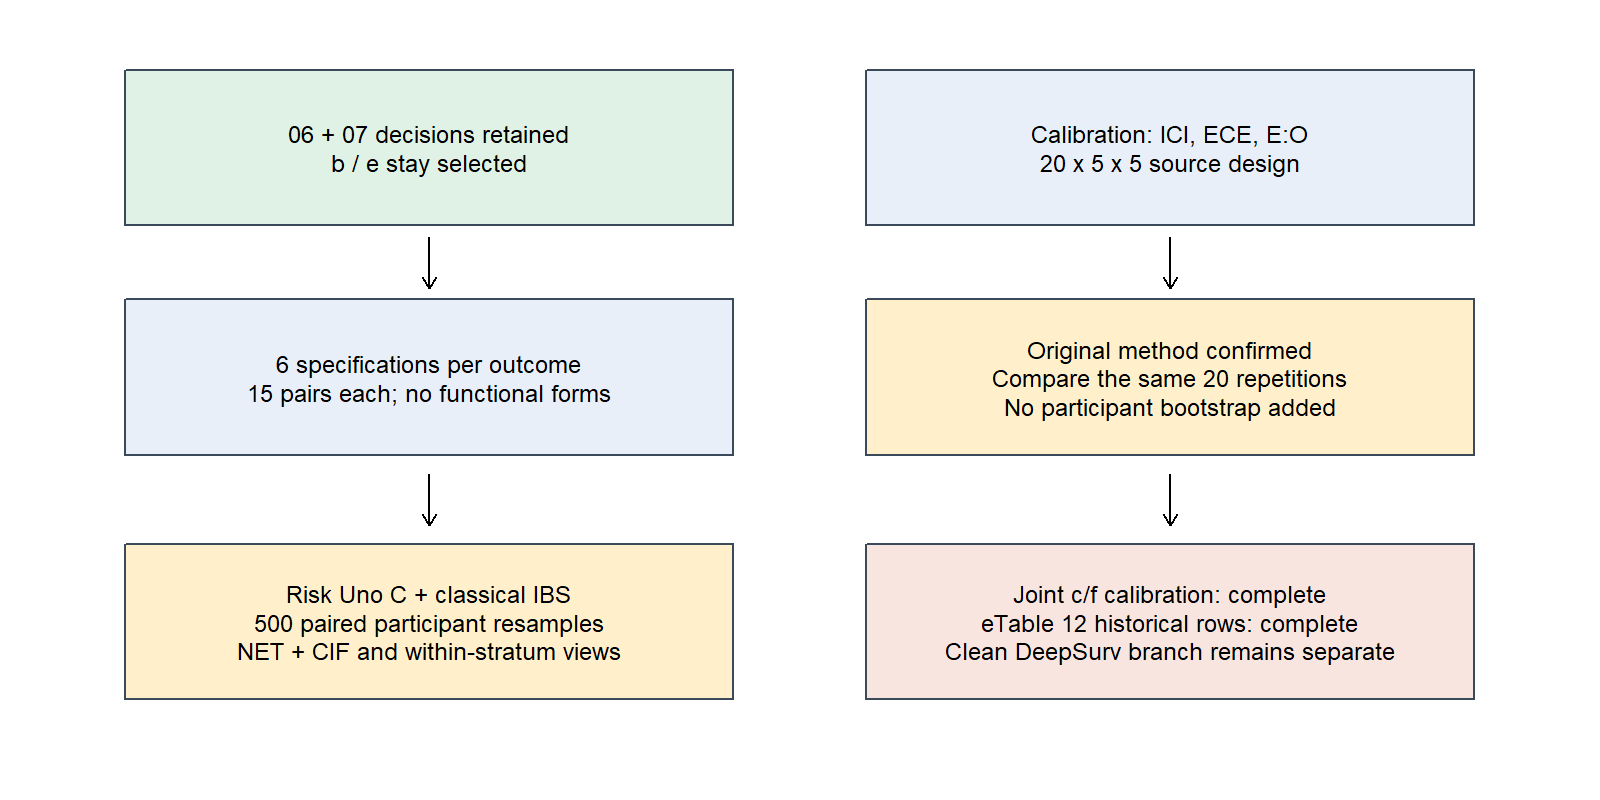

Elapsed: 0.001 minutes


In [34]:
#| label: p225-next-stage-flowchart
#| message: false
.t0 <- proc.time()
# Show the comparison design; execution status is reported in the result tables.
flow_path <- tempfile(fileext = ".png")
grDevices::png(flow_path, width = 1600, height = 800, res = 150)
graphics::par(mar = c(0, 0, 0, 0))
graphics::plot.new()
graphics::plot.window(xlim = c(0, 1), ylim = c(0, 1))
box <- function(x, y, text, fill) {
  graphics::rect(x - 0.205, y - 0.105, x + 0.205, y + 0.105, col = fill, border = "#3a4a5a", lwd = 1.5)
  graphics::text(x, y, text, cex = 0.95)
}
box(0.25, 0.84, "06 + 07 decisions retained\nb / e stay selected", "#e0f1e6")
box(0.25, 0.53, "6 specifications per outcome\n15 pairs each; no functional forms", "#e8eff8")
box(0.25, 0.20, "Risk Uno C + classical IBS\n500 paired participant resamples\nNET + CIF and within-stratum views", "#fff0cb")
box(0.75, 0.84, "Calibration: ICI, ECE, E:O\n20 x 5 x 5 source design", "#e8eff8")
box(0.75, 0.53, "Original method confirmed\nCompare the same 20 repetitions\nNo participant bootstrap added", "#fff0cb")
box(0.75, 0.20, paste0("Joint c/f calibration: ", if (calibration_complete) "complete" else "pending", "\neTable 12 historical rows: ", if (hist12_complete) "complete" else "pending", "\nClean DeepSurv branch remains separate"), "#f8e5df")
for (x in c(0.25, 0.75)) for (y in c(0.72, 0.40)) graphics::arrows(x, y, x, y - 0.07, length = 0.09, lwd = 1.5)
grDevices::dev.off()
IRdisplay::display_png(file = flow_path)
unlink(flow_path)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

In [35]:
#| label: p225-save-preparation-record
#| message: false
.t0 <- proc.time()
# Save aggregate preparation evidence only; all participant-level inputs stay in their existing caches.
entry_signature <- substr(digest::digest(list(source_hashes, comparison_registry$Formula, settings, bootstrap_signature, extended_bootstrap_signature, hist12_signature, vapply(extended_plan, `[[`, character(1L), "Signature")), algo = "sha256"), 1L, 12L)
entry_record <- list(status = if (bootstrap_complete) "c_ibs_bootstrap_complete_calibration_pending" else "all_pairs_prepared_original_methods_accepted", source_hashes = source_hashes, models = model_registry, formal_design = formal_design, cache_manifest = cache_manifest, cached_points = point_estimates, reproduction_controls = point_controls, development_participants = participants, imputations = length(development), fold_signature = shap_run$snapshot$fold_signatures[[1L]], manuscript_review_pending = shap_handoff$manuscript_review_pending, clean_deepsurv_ready = FALSE, preprocessing_limitation = shap_handoff$imputation_limitation, new_model_fits = cf_new_fits, new_bootstrap_replicates = bootstrap_new_jobs * settings$bootstrap_replicates, nonreportable_pilot_draws = sum(pilot_table$Replicates), comparison_registry = comparison_registry, pair_registry = pair_registry, paired_controls = paired_controls, paired_cache_manifest = paired_cache_manifest, calibration_sources = calibration_sources, calibration_method = settings$calibration_comparison_method, bootstrap_signature = bootstrap_signature, pilot = pilot_table, budget = budget, calibration_controls = calibration_controls, calibration_fold_controls = calibration_fold_controls, calibration_pairwise = calibration_pairwise, calibration_complete = calibration_complete, joint_cf_prepared = TRUE, joint_cf_planned_fits = cf_planned_fits)
entry_record$extensions <- list(definitions_confirmed = TRUE, prediction_caches_ready = extended_ready, bootstrap_complete = extended_bootstrap_complete, planned_cox_fits = sum(vapply(extended_plan, `[[`, integer(1L), "Planned_Cox_fits")), new_cox_fits = extended_new_fits, new_bootstrap_jobs = extended_new_jobs, new_bootstrap_replicates = extended_new_jobs * settings$bootstrap_replicates, controls = extension_controls, synthetic_control_replicates = 3L, reused_ibs_anchor = extended_ibs_anchor, input_hashes = extended_input_hashes, bootstrap_signature = extended_bootstrap_signature, grouping = c("global", "within_own", "within_setting"), within_c_aggregation = "Mean of 25 original fold/imputation C statistics", within_ibs = "Identical size-weighted regrouping of global losses with fixed G", lp_ready = length(lp_results) == 2L, threshold_summary_ready = !is.null(threshold_out_best2), dca_run = FALSE)
entry_record$new_model_fits <- cf_new_fits + extended_new_fits
entry_record$new_bootstrap_replicates <- (bootstrap_new_jobs + extended_new_jobs + hist12_new_bootstrap_jobs) * settings$bootstrap_replicates
entry_record$historical_etable12 <- list(complete = hist12_complete, signature = hist12_signature, expected_manuscript_rows = nrow(hist12_reference), completed_manuscript_rows = nrow(hist12_pairwise), new_loss_matrices = hist12_new_points, new_bootstrap_jobs = hist12_new_bootstrap_jobs, new_bootstrap_replicates = hist12_new_bootstrap_jobs * settings$bootstrap_replicates, original_scoring_preserved = TRUE, historical_rng_reproduced = FALSE, method_note_review_pending = TRUE, no_model_selection_applied = TRUE)
entry_record$status <- if (bootstrap_complete && extended_bootstrap_complete && calibration_complete && hist12_complete) "requested_comparisons_complete_review_pending" else "confirmed_branches_prepared_full_comparisons_pending"
entry_path <- file.path(object_dir, paste0("pred225_preparation_", Sys.Date(), "_", entry_signature, ".rds"))
saveRDS(entry_record, entry_path)
stopifnot(identical(readRDS(entry_path), entry_record))
written <- c(written, entry_path)
show_table(data.frame(Item = c("Available RAM (GiB)", "Current R working set (GiB)", "Configured future maximum workers", "Reserved RAM (GiB)", "New model fits", "New bootstrap replicates"), Value = c(ps::ps_system_memory()$avail / 1024^3, ps::ps_memory_info()[["rss"]] / 1024^3, settings$workers, settings$reserve_memory_gib, entry_record$new_model_fits, entry_record$new_bootstrap_replicates)), "Actual preparation resources; heavy execution requires its own budget checkpoint")
cat("The 500-replicate plan is preserved. Full execution status is recorded separately from the non-reportable pilot. No bootstrap reduction is adopted. This record contains no participant-level data.\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Item,Value
Available RAM (GiB),63.601326
Current R working set (GiB),2.520428
Configured future maximum workers,6.000000
Reserved RAM (GiB),20.000000
New model fits,1000.000000
New bootstrap replicates,500.000000


The 500-replicate plan is preserved. Full execution status is recorded separately from the non-reportable pilot. No bootstrap reduction is adopted. This record contains no participant-level data.


Elapsed: 0.001 minutes


## Censoring weights: what the intervals cover
G is the estimated probability of remaining uncensored. Keeping G fixed is **not** setting weights to one and does not establish independent censoring. As approved, primary Uno C and the new Wolbers C re-estimate G in every participant resample; IBS resamples its original fixed IPCW contributions. Those IBS intervals describe variability conditional on the supplied predictions and G, rather than the full imputation/selection/fitting pipeline. Freezing G is an inferential approximation, not a guarantee that intervals are necessarily narrower. Calibration retains the original repeated-CV method.

LP results use joint infinitesimal-jackknife covariance, with Wald limits explicitly distinguished from percentile bootstrap limits. The threshold table preserves the original fixed thresholds, validation-fold G floor and empirical ranges across 25 fold/imputation blocks; those ranges are not presented as participant-bootstrap confidence intervals.

Sources: [Wolbers et al., competing-risk concordance](https://pmc.ncbi.nlm.nih.gov/articles/PMC4059461/), [survival concordance and joint IJ covariance](https://stat.ethz.ch/R-manual/R-devel/library/survival/html/concordance.html), [reference-zero Cox predictions](https://stat.ethz.ch/R-manual/R-devel/library/survival/html/predict.coxph.html), and [riskRegression Score: treatment of censoring-weight uncertainty](https://search.r-project.org/CRAN/refmans/riskRegression/html/Score.html).


## Session info
The main-thread value below is the configured startup setting. The budget pilot subsequently set the main native-thread limits to one; bootstrap workers also used one thread each.

In [36]:
#| label: p225-session-info
#| message: false
.t0 <- proc.time()
# Record the exact preparation environment in browsable tables and a compact text file.
session <- utils::sessionInfo()
quarto_version <- system2(resolve_path(config$runtime$quarto_executable), "--version", stdout = TRUE, stderr = TRUE)
show_table(data.frame(Item = c("R", "Platform", "Operating system", "Recorded", "Quarto", "Seed", "Main threads"), Value = c(session$R.version$version.string, session$platform, session$running, format(Sys.time(), "%Y-%m-%d %H:%M:%S %Z"), paste(quarto_version, collapse = " "), config$imputation$seed, threads)), "Session information")
loaded <- c(session$otherPkgs, session$loadedOnly)
package_table <- do.call(rbind, lapply(loaded, function(x) data.frame(Package = x$Package, Version = x$Version)))
show_table(package_table[order(package_table$Package), ], "Loaded R packages")
session_path <- file.path(object_dir, paste0("SessionInfo_08_", format(Sys.time(), "%Y-%m-%d_%H%M%S"), "_", entry_signature, ".txt"))
session_lines <- c(paste("Recorded:", format(Sys.time(), "%Y-%m-%d %H:%M:%S %Z")), paste("Quarto:", paste(quarto_version, collapse = " ")), capture.output(print(session)))
writeLines(session_lines, session_path, useBytes = TRUE)
stopifnot(identical(readLines(session_path, warn = FALSE), session_lines))
written <- c(written, session_path)
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Item,Value
R,R version 4.4.1 (2024-06-14 ucrt)
Platform,x86_64-w64-mingw32/x64
Operating system,Windows 11 x64 (build 26200)
Recorded,2026-10-09 22:35:51 -03
Quarto,1.9.36
Seed,2125
Main threads,2


Package,Version
Formula,1.2-5
Hmisc,5.2-5
IRdisplay,1.1
IRkernel,1.3.2
MASS,7.3-60.2
Matrix,1.7-0
MatrixModels,0.5-3
R6,2.6.1
RColorBrewer,1.1-3
Rcpp,1.1.1


Elapsed: 0.008 minutes


## Files written and checkpoint
This closing run wrote 128 artifacts listed below, including the completed joint c/f calibration, ten historical IBS loss caches, one additional 500-resample bootstrap cache, compact tables, its aggregate record and Session info. All 53 earlier bootstrap jobs were reused without modification. Each job contains 500 finite resamples; this is not a count of independent participant draws.
Independent verification rebuilt all 84 historical-table paired deltas and percentile intervals, plus 40 added model/horizon estimates, from saved losses and draws. All 360 calibration comparisons are complete. Their 300 previously available rows remained unchanged, and the paired fold/participant coverage checks passed. Groups without comparable pairs remain explicitly flagged in the supplementary support table. The clean DeepSurv branch is separate from this completed comparison set.
The bootstrap intervals are exploratory and pointwise, conditional on stored out-of-fold predictions. They do not repeat imputation, model fitting or selection and are not simultaneous or selection-adjusted intervals. Calibration retains the approved repeated-CV summaries rather than participant-bootstrap intervals. See [methodological review](../docs/08_paired_comparisons_literature.md) and [completion checkpoint](../docs/08_complete_checkpoint.md).

In [37]:
#| label: p225-written-files-and-checkpoint
#| message: false
.t0 <- proc.time()
# Finish with actual relative output paths and sizes, plus a machine-readable preparation state.
stopifnot(all(file.exists(written)))
manifest <- data.frame(Path = substring(unique(written), nchar(root) + 2L), Bytes = as.numeric(file.info(unique(written))$size))
show_table(manifest, "Files written in outputs during this run")
status <- list(status = entry_record$status, entry_signature = entry_signature, retained_models = names(formulas), models = model_registry, participants = participants, imputations = length(development), reproduction_controls = point_controls, cached_points = point_estimates, new_model_fits = entry_record$new_model_fits, new_bootstrap_replicates = entry_record$new_bootstrap_replicates, extensions = entry_record$extensions, historical_etable12 = entry_record$historical_etable12, nonreportable_pilot_draws = sum(pilot_table$Replicates), comparison_registry = comparison_registry, pair_registry = pair_registry, paired_controls = paired_controls, calibration_sources = calibration_sources, calibration_method = settings$calibration_comparison_method, bootstrap_complete = bootstrap_complete, bootstrap_signature = bootstrap_signature, bootstrap_pairs = nrow(bootstrap_pairwise), pilot = pilot_table, budget = budget, calibration_controls = calibration_controls, calibration_fold_controls = calibration_fold_controls, calibration_complete = calibration_complete, calibration_pairwise = calibration_pairwise, joint_cf_prepared = TRUE, joint_cf_planned_fits = cf_planned_fits, clean_deepsurv_ready = FALSE, formal_c_ibs_repeats = settings$c_ibs_repeats, planned_bootstrap_replicates = settings$bootstrap_replicates, calibration_repeats = settings$calibration_repeats, manuscript_modified = FALSE, artifacts = manifest$Path)
cat(jsonlite::toJSON(status, auto_unbox = TRUE, digits = 16), "\n")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time() - .t0)["elapsed"]) / 60))

Path,Bytes
outputs/objects/perf08_cal_aj_c_f_2026-10-09_ff0998e7f195.rds,19563
outputs/objects/perf08_cal_aj_c_f_r01_f01_2026-10-09_ff0998e7f195.rds,461659
outputs/objects/perf08_cal_aj_c_f_r01_f02_2026-10-09_ff0998e7f195.rds,461773
outputs/objects/perf08_cal_aj_c_f_r01_f03_2026-10-09_ff0998e7f195.rds,461668
outputs/objects/perf08_cal_aj_c_f_r01_f04_2026-10-09_ff0998e7f195.rds,461797
outputs/objects/perf08_cal_aj_c_f_r01_f05_2026-10-09_ff0998e7f195.rds,461773
outputs/objects/perf08_cal_aj_c_f_r02_f01_2026-10-09_ff0998e7f195.rds,461724
outputs/objects/perf08_cal_aj_c_f_r02_f02_2026-10-09_ff0998e7f195.rds,461747
outputs/objects/perf08_cal_aj_c_f_r02_f03_2026-10-09_ff0998e7f195.rds,461761
outputs/objects/perf08_cal_aj_c_f_r02_f04_2026-10-09_ff0998e7f195.rds,461746


{"status":"requested_comparisons_complete_review_pending","entry_signature":"3d29285bc2d8","retained_models":["Full_readmission","b","Full_mortality","e"],"models":[{"Model":"Full_readmission","Outcome":"Readmission","Predictor_set":"Full, retained in 06","Ordinary_terms":63,"Stratification":"Treatment setting + rule violation/undetermined discharge","Formula":"Surv(readmit_time_from_disch_m, readmit_event) ~ adm_age_rec3 +      porc_pobr + dit_m + national_foreign + ethnicity + dg_psiq_cie_10_instudy +      dg_psiq_cie_10_dg + dx_f3_mood + dx_f6_personality + dx_f_any_severe_mental +      any_phys_dx + polysubstance_strict + sex_rec_woman + cohabitation_family_of_origin +      cohabitation_with_couple_children + cohabitation_others +      sub_dep_icd10_status_drug_dependence + any_violence_1_domestic_violence_sex_abuse +      tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons +      adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_se

Elapsed: 0.003 minutes
